# TinyML Model Experiments

This notebook is an append-only experiment log. Every model version retains its configuration, results, and rationale. New experiments are added below previous ones so that improvements and trade-offs remain auditable and reproducible.


## 1. Setup and reproducibility

The random seed, data split, preprocessing statistics, and model configuration are fixed and saved. This makes the experiment repeatable and ensures that later ablations differ by one controlled decision at a time.

In [1]:
%matplotlib inline

import getpass
import json
import os
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from huggingface_hub import HfApi, hf_hub_download
from scipy.optimize import linear_sum_assignment

SRC_DIR = Path.cwd() / 'src' if (Path.cwd() / 'src').exists() else Path.cwd()
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

# Always reload local project modules to avoid stale Jupyter imports.
import importlib
import modeling as modeling_module
modeling_module = importlib.reload(modeling_module)

from modeling import (
    MetricAlignedPermutationLoss, MultiPersonLoss, PermutationInvariantMultiPersonLoss,
    build_baseline_model, masked_mean_distance_m,
    person_count_accuracy, slot_confidence_accuracy,
)
# Reload local project modules so notebook execution always sees the latest
# on-disk implementation, even when the Jupyter kernel was already running.
import preprocessing as preprocessing_module
preprocessing_module = importlib.reload(preprocessing_module)

from preprocessing import (
    PreprocessingConfig, build_sorted_targets, normalize_per_radar,
    normalize_per_radar_channel, transform_fused_magnitude_iq,
    transform_phase_ema_temporal, transform_signal, transform_signed_iq_channels,
)

SEED = 42

# Experiment execution policy. Previous versions are preserved and are not
# retrained during a normal Run All. Enable a flag only for full reproduction.
RETRAIN_V1 = False
RETRAIN_V2 = False
TRAIN_V3 = False
TRAIN_V4 = False
TRAIN_V5 = False
TRAIN_V6 = False
TRAIN_V7 = False
TRAIN_V8 = False
TRAIN_V9 = False
TRAIN_V10 = False
TRAIN_V11 = False
RUN_V10_ABLATIONS = False
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

HF_TOKEN = os.getenv('HF_TOKEN')
if not HF_TOKEN:
    HF_TOKEN = getpass.getpass('Enter your Hugging Face read-only token: ')
HF_TOKEN = HF_TOKEN.strip()
api = HfApi(token=HF_TOKEN)
print('Authenticated as:', api.whoami()['name'])
print('TensorFlow version:', tf.__version__)

c:\Users\213053\OneDrive\Documenti\EEAI\.venv_training\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Authenticated as: KetrinMehmeti
TensorFlow version: 2.21.0


## 2. Load the fixed experiment contract

Training must reuse the exact split and per-radar statistics produced by the preprocessing notebook.

In [2]:
ARTIFACT_DIR = SRC_DIR / 'artifacts'
MODEL_DIR = SRC_DIR / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

with (ARTIFACT_DIR / 'data_split.json').open(encoding='utf-8') as handle:
    split = json.load(handle)
with (ARTIFACT_DIR / 'preprocessing_config.json').open(encoding='utf-8') as handle:
    preprocessing_artifact = json.load(handle)

config_values = preprocessing_artifact['config'].copy()
config_values['radar_indices'] = tuple(config_values['radar_indices'])
PREPROCESSING_CONFIG = PreprocessingConfig(**config_values)
RADAR_MEAN = np.asarray(preprocessing_artifact['radar_mean'], dtype=np.float32)
RADAR_STD = np.asarray(preprocessing_artifact['radar_std'], dtype=np.float32)
TRAIN_WINDOWS = split['train_windows']
VALIDATION_WINDOWS = split['validation_windows']

assert PREPROCESSING_CONFIG.background_mode == 'none'
assert set(TRAIN_WINDOWS).isdisjoint(VALIDATION_WINDOWS)
print('Training windows:', TRAIN_WINDOWS)
print('Validation windows:', VALIDATION_WINDOWS)
print('Per-radar mean:', RADAR_MEAN)
print('Per-radar std: ', RADAR_STD)

Training windows: [0, 1, 2, 4, 5, 6, 7, 8, 10, 11, 12, 13, 15, 16, 17, 19, 20, 21, 22]
Validation windows: [3, 9, 14, 18, 23]
Per-radar mean: [5.519326  5.4170136 5.4524097 5.4463177 5.4428096 5.3198543]
Per-radar std:  [1.672727  1.7270064 1.7676206 1.7149378 1.7848368 1.6998575]


## 3. Resolve cached dataset files

The files downloaded in previous notebooks are reused from the Hugging Face cache.

In [3]:
REPO_ID = 'HAEEAI/multi-person-localization'
window_paths = {}
for index in sorted(TRAIN_WINDOWS + VALIDATION_WINDOWS):
    filename = f'data/window_{index:06d}.npz'
    window_paths[index] = Path(hf_hub_download(
        repo_id=REPO_ID, repo_type='dataset', filename=filename, token=HF_TOKEN
    ))
print(f'{len(window_paths)} windows are ready.')

24 windows are ready.


## 4. Streaming input pipeline

Precomputing all float32 features would require more than one gigabyte of memory. The generator therefore loads one acquisition window at a time, transforms 256-frame chunks, and releases each window before loading the next. Training windows and chunks are shuffled, while validation remains deterministic.

In [4]:
CHUNK_SIZE = 256
BATCH_SIZE = 128
INPUT_SHAPE = (len(PREPROCESSING_CONFIG.radar_indices), 3, 120)

def window_chunk_generator(indices, shuffle):
    ordered_indices = list(indices)
    if shuffle:
        np.random.shuffle(ordered_indices)
    for window_index in ordered_indices:
        with np.load(window_paths[window_index], allow_pickle=False) as data:
            radar = data['radar_cir_iq']
            people_xy = data['people_xy']
            people_mask = data['people_mask']
            starts = list(range(0, len(radar), CHUNK_SIZE))
            if shuffle:
                np.random.shuffle(starts)
            for start in starts:
                stop = min(start + CHUNK_SIZE, len(radar))
                features = transform_signal(radar[start:stop], PREPROCESSING_CONFIG)
                features = normalize_per_radar(features, RADAR_MEAN, RADAR_STD)
                targets = build_sorted_targets(people_xy[start:stop], people_mask[start:stop])
                yield features, targets

output_signature = (
    tf.TensorSpec(shape=(None,) + INPUT_SHAPE, dtype=tf.float32),
    tf.TensorSpec(shape=(None, 4, 3), dtype=tf.float32),
)

def make_dataset(indices, training, repeat=False):
    dataset = tf.data.Dataset.from_generator(
        lambda: window_chunk_generator(indices, shuffle=training),
        output_signature=output_signature,
    ).unbatch()
    if training:
        dataset = dataset.shuffle(8192, seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.batch(BATCH_SIZE)
    if repeat:
        dataset = dataset.repeat()
    return dataset.prefetch(tf.data.AUTOTUNE)

TRAIN_STEPS = int(np.ceil(len(TRAIN_WINDOWS) * 7500 / BATCH_SIZE))
VALIDATION_STEPS = int(np.ceil(len(VALIDATION_WINDOWS) * 7500 / BATCH_SIZE))
train_dataset = make_dataset(TRAIN_WINDOWS, training=True, repeat=True)
validation_fit_dataset = make_dataset(VALIDATION_WINDOWS, training=False, repeat=True)
validation_dataset = make_dataset(VALIDATION_WINDOWS, training=False, repeat=False)

sample_features, sample_targets = next(iter(train_dataset))
print('Feature batch:', sample_features.shape, sample_features.dtype)
print('Target batch: ', sample_targets.shape, sample_targets.dtype)
print('Feature range:', float(tf.reduce_min(sample_features)), float(tf.reduce_max(sample_features)))
print('Target range: ', float(tf.reduce_min(sample_targets)), float(tf.reduce_max(sample_targets)))

Feature batch: (128, 6, 3, 120) <dtype: 'float32'>
Target batch:  (128, 4, 3) <dtype: 'float32'>
Feature range: -3.299595832824707 2.8229873180389404
Target range:  0.0 1.0


### Shared visualisation protocol

Every model version uses the same plotting functions and axis ranges. Convergence is always shown as training/validation loss plus the version's presence-related accuracy metric. Official evaluation is always shown as a four-panel dashboard: confidence-threshold curves, global metrics, occupancy F1, and occupancy count accuracy. This makes the experiments visually comparable.

In [5]:
def plot_convergence_dashboard(history_record, accuracy_key, validation_accuracy_key, version, selected_epoch=None):
    epochs = np.arange(1, len(history_record['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(epochs, history_record['loss'], marker='.', label='Training')
    axes[0].plot(epochs, history_record['val_loss'], marker='.', label='Validation')
    axes[0].set(title='Composite loss', xlabel='Epoch')
    axes[1].plot(epochs, history_record[accuracy_key], marker='.', label='Training')
    axes[1].plot(epochs, history_record[validation_accuracy_key], marker='.', label='Validation')
    axes[1].set(title='Presence-related accuracy', xlabel='Epoch', ylim=(0, 1.05))
    for axis in axes:
        if selected_epoch is not None:
            axis.axvline(selected_epoch, color='black', linestyle='--', alpha=0.7, label='Selected epoch')
        axis.grid(alpha=0.25)
        axis.legend()
    fig.suptitle(f'{version} Convergence')
    plt.tight_layout()
    plt.show()


def plot_evaluation_dashboard(version, threshold_results, best_result, occupancy_results):
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    thresholds = [result['threshold'] for result in threshold_results]
    for metric, marker in [('f1', 'o'), ('precision', '.'), ('recall', '.')]:
        axes[0, 0].plot(thresholds, [result[metric] for result in threshold_results], marker=marker, label=metric.title())
    axes[0, 0].axvline(best_result['threshold'], color='black', linestyle='--', label=f"Best: {best_result['threshold']:.2f}")
    axes[0, 0].set(title='Confidence-threshold sweep', xlabel='Threshold', ylabel='Score', ylim=(0, 1))
    axes[0, 0].legend()

    global_names = ['Precision', 'Recall', 'F1', 'Count accuracy']
    global_values = [best_result['precision'], best_result['recall'], best_result['f1'], best_result['count_accuracy']]
    bars = axes[0, 1].bar(global_names, global_values, color=['#4c72b0', '#dd8452', '#55a868', '#8172b2'])
    axes[0, 1].bar_label(bars, fmt='%.3f', padding=3)
    axes[0, 1].set(title='Global validation metrics', ylim=(0, 1))
    axes[0, 1].tick_params(axis='x', rotation=20)

    occupancies = np.arange(5)
    f1_values = [np.nan if level == 0 else occupancy_results[level]['f1'] for level in occupancies]
    axes[1, 0].bar(occupancies[1:], f1_values[1:], color='#4c72b0')
    axes[1, 0].set(title='Hungarian F1 by occupancy', xlabel='Ground-truth people', ylabel='F1', ylim=(0, 1), xticks=occupancies[1:])

    count_values = [occupancy_results[level]['count_accuracy'] for level in occupancies]
    axes[1, 1].bar(occupancies, count_values, color='#55a868')
    axes[1, 1].set(title='Count accuracy by occupancy', xlabel='Ground-truth people', ylabel='Accuracy', ylim=(0, 1), xticks=occupancies)
    for axis in axes.flat:
        axis.grid(axis='y', alpha=0.25)
    fig.suptitle(f'{version} Official Evaluation Dashboard')
    plt.tight_layout()
    plt.show()

## 5. Experiment 1 - Minimal global-pooling baseline (V1)

V1 establishes the smallest credible reference model. It uses early range-bin downsampling, three depthwise-separable blocks, global average pooling, and a 32-unit bottleneck. The experiment intentionally prioritises a very small parameter count and standard TensorFlow Lite Micro operations.

The data split, preprocessing, target construction, and Hungarian evaluator are identical to subsequent versions. This makes later comparisons attributable to the model and objective rather than to a changed validation protocol.

In [6]:
V1_FILTERS = (16, 24, 32)
V1_DENSE_UNITS = 32
V1_DROPOUT_RATE = 0.10
V1_LOCALIZATION_WEIGHT = 5.0

v1_model = build_baseline_model(
    input_shape=INPUT_SHAPE,
    filters=V1_FILTERS,
    dense_units=V1_DENSE_UNITS,
    dropout_rate=V1_DROPOUT_RATE,
    preserve_spatial_layout=False,
)
v1_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=MultiPersonLoss(localization_weight=V1_LOCALIZATION_WEIGHT, delta=0.1),
    metrics=[masked_mean_distance_m, slot_confidence_accuracy],
)

print(f'V1 parameters: {v1_model.count_params():,}')
print(f'V1 estimated INT8 weight size: {v1_model.count_params() / 1024:.1f} KiB')

with (ARTIFACT_DIR / 'baseline_experiment.json').open(encoding='utf-8') as handle:
    v1_experiment = json.load(handle)
print('V1 recorded validation metrics:')
print(json.dumps(v1_experiment['validation_metrics'], indent=2))

V1 parameters: 4,372
V1 estimated INT8 weight size: 4.3 KiB
V1 recorded validation metrics:
{
  "threshold": 0.8500000000000002,
  "tp": 32468,
  "fp": 41004,
  "fn": 42532,
  "precision": 0.4419098432055749,
  "recall": 0.43290666666666666,
  "f1": 0.4373619268279541,
  "matched_mae_m": 0.5292271971702576,
  "matched_p90_m": 0.8904476761817932,
  "count_mae": 0.2890666666666667,
  "count_accuracy": 0.7109333333333333
}


### 5.1 V1 results and diagnosis

V1 contains only **4,372 parameters**. Its selected confidence threshold is **0.85**, with global validation **F1 = 0.4374**, precision **0.4419**, recall **0.4329**, count accuracy **0.7109**, matched MAE **0.529 m**, and matched P90 **0.890 m**.

The matched-distance values are conditional on a prediction already falling within the official 1 m acceptance radius. They therefore do not compensate for the large numbers of unmatched predictions: 41,004 false positives and 42,532 false negatives.

Occupancy-level F1 is 0.3660 for one person, 0.3715 for two people, 0.4890 for three people, and 0.4569 for four people. Empty-room count accuracy is 0.8339, meaning that approximately 16.6% of empty frames still contain at least one false detection.

Training confidence accuracy approaches 99%, while training localisation error remains around 1.35 m and the best validation localisation diagnostic remains around 1.09 m. This is **geometric underfitting**, not conventional overfitting. Global average pooling removes absolute range-bin position, and fixed left-to-right target slots introduce discontinuities when people cross. These observations motivate V2.

### 5.2 V1 convergence curves

The arrays below preserve the epoch-level metrics recorded during the original V1 run. They are stored explicitly because the initial Keras history object was not serialised. The best validation loss occurred at epoch 8; training continued until epoch 13 and then restored epoch-8 weights.

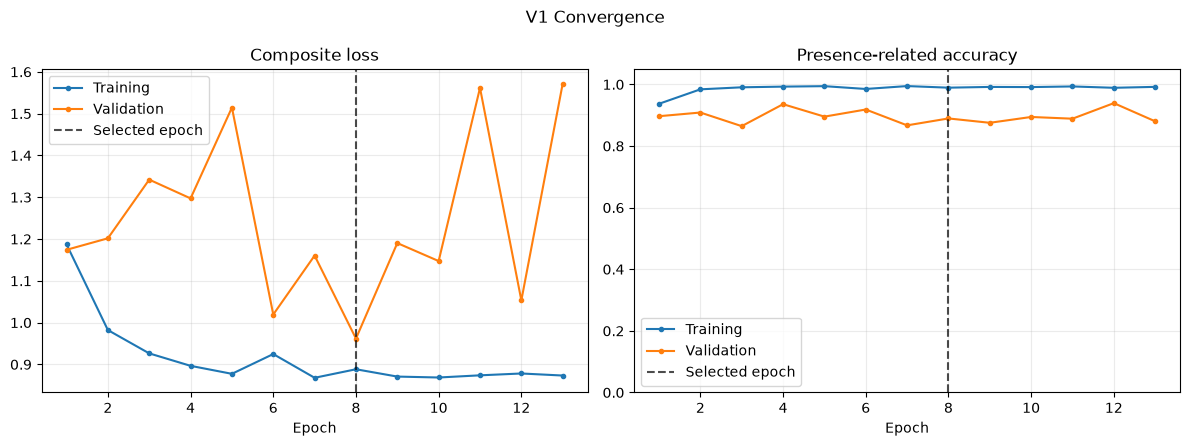

In [7]:
v1_history_record = {
    'loss': [1.1873, 0.9822, 0.9264, 0.8966, 0.8775, 0.9248, 0.8680, 0.8884, 0.8709, 0.8687, 0.8739, 0.8783, 0.8734],
    'val_loss': [1.1742, 1.2017, 1.3421, 1.2972, 1.5145, 1.0194, 1.1604, 0.9618, 1.1903, 1.1473, 1.5616, 1.0532, 1.5716],
    'masked_mean_distance_m': [1.4869, 1.4127, 1.3589, 1.3538, 1.3460, 1.3884, 1.3629, 1.3756, 1.3630, 1.3528, 1.3893, 1.3492, 1.3555],
    'val_masked_mean_distance_m': [1.1934, 1.3217, 1.2715, 1.3264, 1.3264, 1.1760, 1.2397, 1.0941, 1.1698, 1.1874, 1.1255, 1.1236, 1.1380],
    'slot_confidence_accuracy': [0.9371, 0.9840, 0.9906, 0.9928, 0.9943, 0.9852, 0.9946, 0.9894, 0.9918, 0.9913, 0.9934, 0.9890, 0.9920],
    'val_slot_confidence_accuracy': [0.8968, 0.9087, 0.8645, 0.9358, 0.8954, 0.9185, 0.8671, 0.8895, 0.8754, 0.8943, 0.8887, 0.9392, 0.8802],
}

plot_convergence_dashboard(
    v1_history_record,
    'slot_confidence_accuracy',
    'val_slot_confidence_accuracy',
    'V1',
    selected_epoch=8,
)

### 5.3 V1 Hungarian and occupancy-level diagnostics

The official Hungarian evaluation is summarised globally and by occupancy. Empty-room F1 is undefined because no positive ground-truth people exist; count accuracy is used instead to quantify false detections.

V1 global Hungarian metrics:
{
  "threshold": 0.8500000000000002,
  "tp": 32468,
  "fp": 41004,
  "fn": 42532,
  "precision": 0.4419098432055749,
  "recall": 0.43290666666666666,
  "f1": 0.4373619268279541,
  "matched_mae_m": 0.5292271971702576,
  "matched_p90_m": 0.8904476761817932,
  "count_mae": 0.2890666666666667,
  "count_accuracy": 0.7109333333333333
}


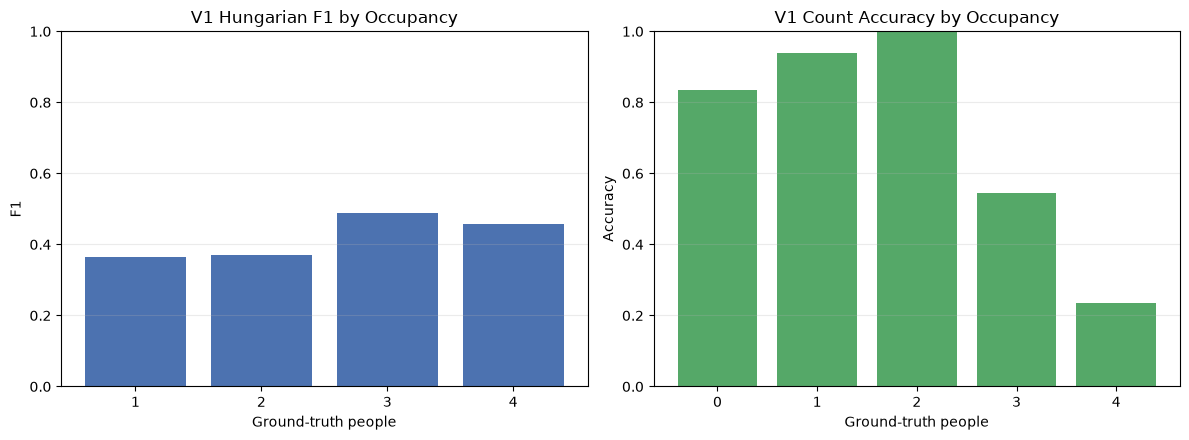

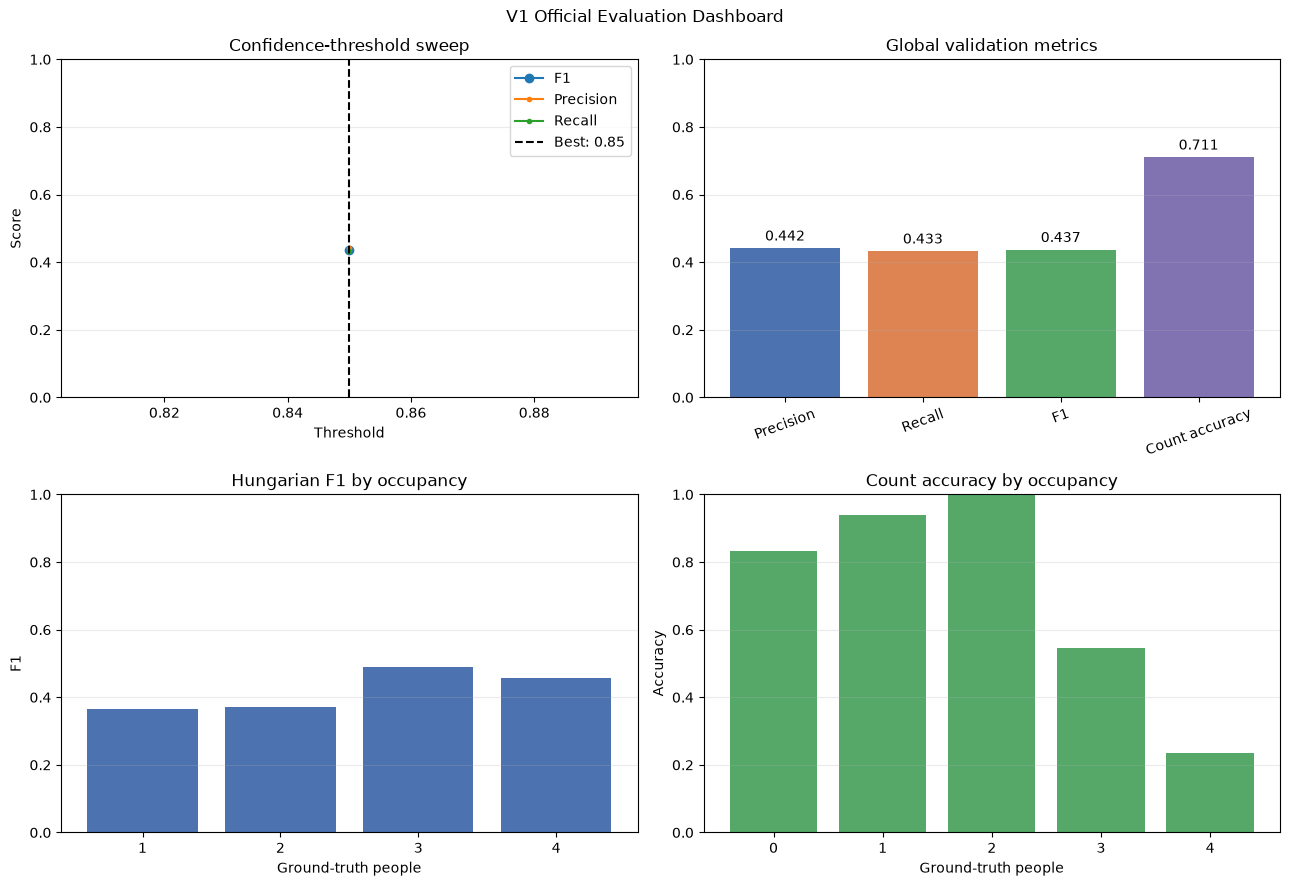

In [8]:
v1_occupancy_results = {
    0: {'f1': np.nan, 'precision': np.nan, 'recall': np.nan, 'count_accuracy': 0.8339},
    1: {'f1': 0.3660, 'precision': 0.3776, 'recall': 0.3551, 'count_accuracy': 0.9403},
    2: {'f1': 0.3715, 'precision': 0.3715, 'recall': 0.3715, 'count_accuracy': 1.0000},
    3: {'f1': 0.4890, 'precision': 0.4568, 'recall': 0.5260, 'count_accuracy': 0.5449},
    4: {'f1': 0.4569, 'precision': 0.5109, 'recall': 0.4132, 'count_accuracy': 0.2356},
}

print('V1 global Hungarian metrics:')
print(json.dumps(v1_experiment['validation_metrics'], indent=2))

occupancies = np.arange(5)
f1_values = [v1_occupancy_results[level]['f1'] for level in occupancies]
count_values = [v1_occupancy_results[level]['count_accuracy'] for level in occupancies]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(occupancies[1:], f1_values[1:], color='#4c72b0')
axes[0].set(title='V1 Hungarian F1 by Occupancy', xlabel='Ground-truth people', ylabel='F1', ylim=(0, 1))
axes[0].set_xticks(occupancies[1:])
axes[1].bar(occupancies, count_values, color='#55a868')
axes[1].set(title='V1 Count Accuracy by Occupancy', xlabel='Ground-truth people', ylabel='Accuracy', ylim=(0, 1))
axes[1].set_xticks(occupancies)
for axis in axes:
    axis.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

v1_threshold_results = [v1_experiment['validation_metrics']]
plot_evaluation_dashboard(
    'V1', v1_threshold_results, v1_experiment['validation_metrics'], v1_occupancy_results
)


### 5.4 Decision from V1 to V2

V1 demonstrates that an extremely small network can learn occupancy cues, but it cannot recover enough geometry for the official localisation task. Training and validation confidence metrics are high, while both training and validation fixed-slot distance remain above approximately one metre. The best global Hungarian F1 is only 0.4374 despite 71.1% count accuracy. This means that many frames contain approximately the correct number of predictions at incorrect locations.

Two changes are therefore justified for V2:

1. **Preserve absolute spatial layout.** Global average pooling is replaced by flattening only after aggressive convolutional downsampling. This retains radar and range-bin position while keeping the model small enough for INT8 deployment.
2. **Remove arbitrary slot ordering from the objective.** The fixed left-to-right assignment is replaced by a permutation-invariant loss over all 24 target assignments, aligning training with the unordered Hungarian evaluator.

Capacity is increased from 4,372 to approximately 135,000 parameters because V1 shows underfitting rather than a widening train-validation gap. The localisation weight is also increased from 5 to 8. All preprocessing, windows, batches, and evaluation thresholds remain controlled so the V1-to-V2 comparison isolates these modelling choices.

### 5.5 Optional full V1 reproduction

The checkpoint and recorded metrics are used during a normal run. Set `RETRAIN_V1 = True` only when the complete original optimisation must be repeated.

In [9]:
# V1 is not retrained during a normal Run All because its checkpoint and
# metrics are already preserved. Set this flag only when full reproduction is required.
if RETRAIN_V1:
    v1_callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            MODEL_DIR / 'baseline_best.keras',
            monitor='val_loss',
            save_best_only=True,
            verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=5, restore_best_weights=True, verbose=1
        ),
    ]
    v1_history = v1_model.fit(
        train_dataset,
        validation_data=validation_fit_dataset,
        steps_per_epoch=TRAIN_STEPS,
        validation_steps=VALIDATION_STEPS,
        epochs=30,
        callbacks=v1_callbacks,
        verbose=1,
    )
else:
    print('V1 retraining skipped; preserved checkpoint and metrics will be used.')

V1 retraining skipped; preserved checkpoint and metrics will be used.


## 6. Experiment 2 - Spatial permutation-invariant model (V2)

The first baseline reached a validation F1 of 0.4374 and a count accuracy of 0.7109. Its confidence predictions were substantially better than its localisation: correct counts still produced many false positives and false negatives because predicted coordinates exceeded the 1 m matching threshold. The main architectural limitation was global average pooling, which deliberately removes absolute spatial position even though range-bin location is essential to localisation.

V2 retains early downsampling and depthwise-separable convolutions, but flattens the final small feature map before the dense bottleneck. This preserves absolute radar and range-bin information while remaining comfortably within the expected INT8 flash budget. Capacity is increased moderately because the original model contained only 4,372 parameters and showed underfitting rather than classical overfitting.

In [10]:
MODEL_FILTERS = (24, 32, 48)
DENSE_UNITS = 64
DROPOUT_RATE = 0.15

model = build_baseline_model(
    input_shape=INPUT_SHAPE, filters=MODEL_FILTERS,
    dense_units=DENSE_UNITS, dropout_rate=DROPOUT_RATE,
    preserve_spatial_layout=True,
)
model.summary()
parameter_count = model.count_params()
print(f'Parameters: {parameter_count:,}')
print(f'Estimated float32 weight size: {parameter_count * 4 / 1024:.1f} KiB')
print(f'Estimated INT8 weight size:   {parameter_count / 1024:.1f} KiB')

Model: "uwb_tiny_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ radar_input (InputLayer)        │ (None, 6, 3, 120)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ orient_input (Permute)          │ (None, 6, 120, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ range_conv (Conv2D)             │ (None, 6, 60, 24)      │           504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ range_bn (BatchNormalization)   │ (None, 6, 60, 24)      │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ range_relu (ReLU)               │ (None, 6, 60, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_1 (DepthwiseConv2D)   │ (None, 6, 60, 24)      │           216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_bn_1                  │ (None, 6, 60, 24)      │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_relu_1 (ReLU)         │ (None, 6, 60, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_1 (Conv2D)            │ (None, 6, 60, 24)      │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_bn_1                  │ (None, 6, 60, 24)      │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_relu_1 (ReLU)         │ (None, 6, 60, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pool_1                  │ (None, 6, 30, 24)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_2 (DepthwiseConv2D)   │ (None, 6, 30, 24)      │           216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_bn_2                  │ (None, 6, 30, 24)      │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_relu_2 (ReLU)         │ (None, 6, 30, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_2 (Conv2D)            │ (None, 6, 30, 32)      │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_bn_2                  │ (None, 6, 30, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_relu_2 (ReLU)         │ (None, 6, 30, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pool_2                  │ (None, 6, 15, 32)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_3 (DepthwiseConv2D)   │ (None, 6, 15, 32)      │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_bn_3                  │ (None, 6, 15, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 134,996 (527.33 KB)

 Trainable params: 134,452 (525.20 KB)

 Non-trainable params: 544 (2.12 KB)

Parameters: 134,996
Estimated float32 weight size: 527.3 KiB
Estimated INT8 weight size:   131.8 KiB


### 6.1 Loss and optimisation

The official output is an unordered set of positions, whereas the first loss assumed a fixed left-to-right slot order. That assumption can become unstable when people cross or occupy similar x coordinates. V2 evaluates all 24 permutations of the four target slots and backpropagates through the lowest-cost assignment for each frame. Confidence is supervised with binary cross-entropy and coordinates with masked Smooth L1. This aligns training more closely with the permutation-invariant Hungarian evaluation.

In [11]:
LOCALIZATION_WEIGHT = 8.0
LEARNING_RATE = 1e-3

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=PermutationInvariantMultiPersonLoss(
        localization_weight=LOCALIZATION_WEIGHT, delta=0.1
    ),
    metrics=[person_count_accuracy],
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        MODEL_DIR / 'baseline_v2_best.keras', monitor='val_loss', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True, verbose=1
    ),
]

### 6.2 Train V2

The first run uses at most 30 epochs with early stopping. Because features are generated from cached NPZ files every epoch, training time includes preprocessing.

In [12]:
EPOCHS = 25

if RETRAIN_V2:
    history = model.fit(
        train_dataset, validation_data=validation_fit_dataset,
        steps_per_epoch=TRAIN_STEPS, validation_steps=VALIDATION_STEPS,
        epochs=EPOCHS, callbacks=callbacks, verbose=1,
    )
else:
    # Recorded history from the preserved V2 run (best epoch: 17).
    from types import SimpleNamespace
    history = SimpleNamespace(history={
        'loss': [1.1973,1.0426,0.9340,0.8675,0.8136,0.8297,0.7595,0.7640,0.7154,0.7295,0.7164,0.7062,0.6816,0.6610,0.6464,0.6403,0.6400,0.6756,0.6939,0.7013,0.6459,0.6712],
        'val_loss': [1.5502,1.4566,1.3908,1.5890,1.7803,1.4032,1.3239,1.4314,1.2919,1.7190,1.2743,1.2718,1.1564,1.5015,1.3470,1.3532,1.1225,1.2783,1.1669,1.2220,1.1369,1.6475],
        'person_count_accuracy': [0.6660,0.8468,0.8936,0.9297,0.9477,0.9240,0.9586,0.9470,0.9591,0.9409,0.9499,0.9435,0.9568,0.9659,0.9757,0.9682,0.9705,0.9312,0.9052,0.9136,0.9470,0.9500],
        'val_person_count_accuracy': [0.5443,0.4654,0.6001,0.5649,0.5815,0.6871,0.6228,0.7713,0.7190,0.5751,0.7848,0.7330,0.7779,0.7669,0.7829,0.7641,0.7681,0.7757,0.8420,0.7322,0.8802,0.7479],
    })
    print('V2 retraining skipped; recorded history and preserved checkpoint will be used.')

V2 retraining skipped; recorded history and preserved checkpoint will be used.


### 6.3 Inspect V2 convergence

Training and validation curves are inspected for underfitting, overfitting, and divergence between confidence and localisation behaviour.

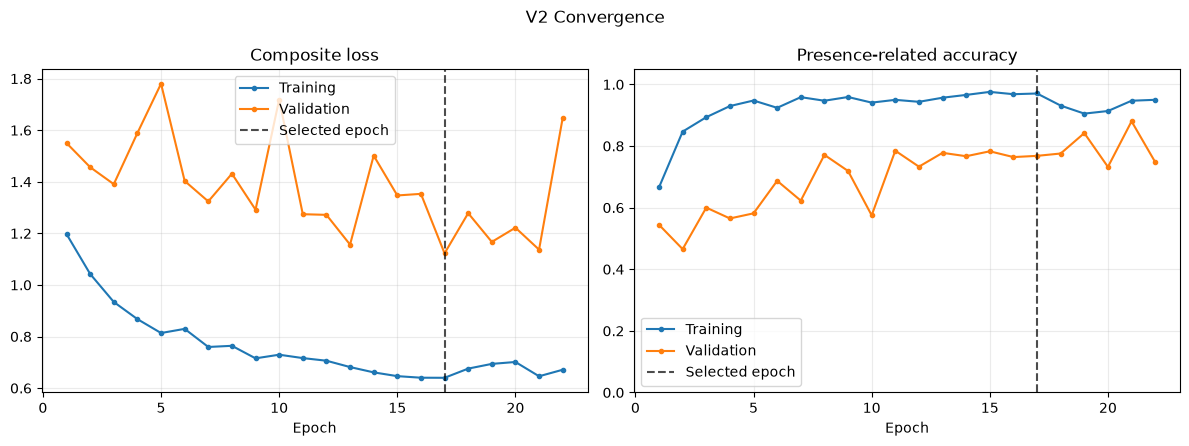

In [13]:
plot_convergence_dashboard(
    history.history,
    'person_count_accuracy',
    'val_person_count_accuracy',
    'V2',
    selected_epoch=17,
)

### 6.4 Collect V2 validation predictions

Predictions and targets are retained in memory only after model inference. Their size is small compared with the radar features.

In [14]:
best_model = tf.keras.models.load_model(MODEL_DIR / 'baseline_v2_best.keras')
all_targets = []
all_predictions = []
for batch_index, (features, targets) in enumerate(validation_dataset):
    predictions = best_model(features, training=False).numpy()
    all_targets.append(targets.numpy())
    all_predictions.append(predictions)
    if (batch_index + 1) % 50 == 0:
        print(f'Processed {batch_index + 1} validation batches')

validation_targets = np.concatenate(all_targets, axis=0)
validation_predictions = np.concatenate(all_predictions, axis=0)
print('Targets:', validation_targets.shape)
print('Predictions:', validation_predictions.shape)

Processed 50 validation batches
Processed 100 validation batches
Processed 150 validation batches
Processed 200 validation batches
Processed 250 validation batches
Targets: (37500, 4, 3)
Predictions: (37500, 4, 3)


### 6.5 Official Hungarian-matching evaluation

For each frame, predicted coordinates are optimally matched to ground truth. A pair is a true positive only when its Euclidean distance is at most 1.0 m. Metrics are then aggregated globally across all validation frames, matching the official evaluator.

In [15]:
ROOM_SCALE = np.array([4.8, 7.2], dtype=np.float32)
MATCH_DISTANCE_M = 1.0

def evaluate_hungarian(targets, predictions, confidence_threshold):
    tp = fp = fn = 0
    matched_distances = []
    true_counts = []
    predicted_counts = []
    for target, prediction in zip(targets, predictions):
        ground_truth = target[target[:, 0] >= 0.5, 1:] * ROOM_SCALE
        predicted = prediction[prediction[:, 0] >= confidence_threshold, 1:] * ROOM_SCALE
        predicted = np.clip(predicted, [0.0, 0.0], ROOM_SCALE)
        true_counts.append(len(ground_truth))
        predicted_counts.append(len(predicted))
        if len(ground_truth) and len(predicted):
            distances = np.linalg.norm(ground_truth[:, None, :] - predicted[None, :, :], axis=-1)
            gt_indices, prediction_indices = linear_sum_assignment(distances)
            assigned = distances[gt_indices, prediction_indices]
            accepted = assigned <= MATCH_DISTANCE_M
            matches = int(accepted.sum())
            matched_distances.extend(assigned[accepted].tolist())
        else:
            matches = 0
        tp += matches
        fp += len(predicted) - matches
        fn += len(ground_truth) - matches
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    matched_distances = np.asarray(matched_distances, dtype=np.float32)
    true_counts = np.asarray(true_counts)
    predicted_counts = np.asarray(predicted_counts)
    return {
        'threshold': float(confidence_threshold), 'tp': tp, 'fp': fp, 'fn': fn,
        'precision': precision, 'recall': recall, 'f1': f1,
        'matched_mae_m': float(matched_distances.mean()) if len(matched_distances) else float('nan'),
        'matched_p90_m': float(np.percentile(matched_distances, 90)) if len(matched_distances) else float('nan'),
        'count_mae': float(np.mean(np.abs(true_counts - predicted_counts))),
        'count_accuracy': float(np.mean(true_counts == predicted_counts)),
    }

threshold_results = [
    evaluate_hungarian(validation_targets, validation_predictions, threshold)
    for threshold in np.arange(0.10, 0.91, 0.05)
]
best_result = max(threshold_results, key=lambda result: result['f1'])
print(json.dumps(best_result, indent=2))

{
  "threshold": 0.1,
  "tp": 39145,
  "fp": 43254,
  "fn": 35855,
  "precision": 0.47506644498112843,
  "recall": 0.5219333333333334,
  "f1": 0.49739833162853647,
  "matched_mae_m": 0.5530833601951599,
  "matched_p90_m": 0.903549075126648,
  "count_mae": 0.24392,
  "count_accuracy": 0.7574133333333334
}


### 6.6 Threshold and occupancy-level diagnostics

The confidence threshold is selected on validation F1. Performance is also reported by ground-truth occupancy to expose empty-room false positives and crowded-scene recall failures.

V2 occupancy-level results at the selected threshold:
0 people | frames=7,500 | F1=0.0000 | P=0.0000 | R=0.0000 | count acc=0.9992
1 people | frames=7,500 | F1=0.8391 | P=0.7835 | R=0.9032 | count acc=0.8204
2 people | frames=7,500 | F1=0.3816 | P=0.3816 | R=0.3816 | count acc=1.0000
3 people | frames=7,500 | F1=0.5311 | P=0.4680 | R=0.6139 | count acc=0.0635
4 people | frames=7,500 | F1=0.4333 | P=0.4390 | R=0.4278 | count acc=0.9040


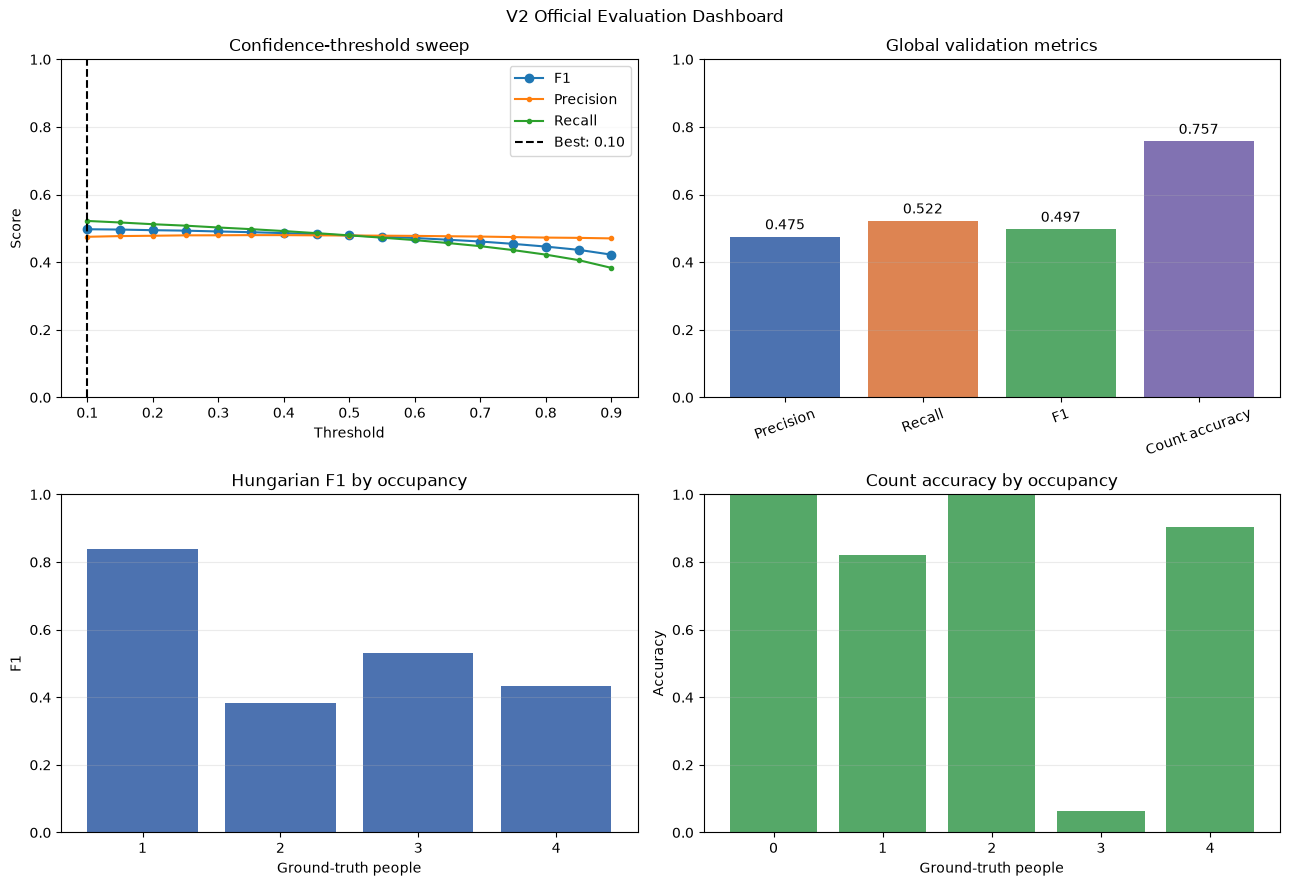

In [16]:
v2_occupancy_results = {}
print('V2 occupancy-level results at the selected threshold:')
for people in range(5):
    frame_mask = validation_targets[..., 0].sum(axis=1).astype(int) == people
    result = evaluate_hungarian(
        validation_targets[frame_mask], validation_predictions[frame_mask], best_result['threshold']
    )
    v2_occupancy_results[people] = result
    print(f"{people} people | frames={frame_mask.sum():,} | F1={result['f1']:.4f} | P={result['precision']:.4f} | R={result['recall']:.4f} | count acc={result['count_accuracy']:.4f}")

plot_evaluation_dashboard('V2', threshold_results, best_result, v2_occupancy_results)

### 6.7 Save V2 experiment

The selected threshold and validation metrics are saved with the architecture configuration. TFLite conversion is intentionally performed in the next notebook after this float baseline has been reviewed.

In [17]:
experiment = {
    'seed': SEED, 'filters': list(MODEL_FILTERS), 'dense_units': DENSE_UNITS,
    'dropout_rate': DROPOUT_RATE, 'localization_weight': LOCALIZATION_WEIGHT,
    'preserve_spatial_layout': True,
    'loss': 'PermutationInvariantMultiPersonLoss',
    'parent_baseline_f1': 0.4373619268279541,
    'learning_rate': LEARNING_RATE, 'batch_size': BATCH_SIZE,
    'parameters': int(model.count_params()),
    'best_confidence_threshold': best_result['threshold'],
    'validation_metrics': best_result,
}
with (ARTIFACT_DIR / 'baseline_v2_experiment.json').open('w', encoding='utf-8') as handle:
    json.dump(experiment, handle, indent=2)
best_model.save(MODEL_DIR / 'baseline_v2_final.keras')
print('Saved V2 model and experiment metadata.')

Saved V2 model and experiment metadata.


### 6.8 V2 results, comparison, and decision for V3

V2 improves global Hungarian F1 from **0.4374 to 0.4974** (+0.0600), recall from **0.4329 to 0.5219**, precision from **0.4419 to 0.4751**, and count accuracy from **0.7109 to 0.7574**. Empty-room count accuracy rises from 0.8339 to 0.9992, and one-person F1 rises substantially from 0.3660 to 0.8391. These gains confirm both V2 hypotheses: retaining spatial layout is useful, and permutation-invariant assignment removes a major limitation for simple scenes.

However, V2 introduces a clear generalisation gap. Training loss falls to approximately 0.64 while the best validation loss remains 1.1225. Training count accuracy frequently exceeds 0.95, whereas validation count accuracy is unstable. The optimal confidence threshold is only **0.10**, indicating poorly calibrated presence probabilities. Occupancy-level results are also inconsistent: two-person F1 remains 0.3816 despite perfect count accuracy, while three-person count accuracy collapses to 0.0635. The model often predicts a plausible number of people but still confuses multi-person geometry or confidence allocation.

V2 contains 134,996 parameters, with most weights located in the dense layer following the flattened spatial map. The larger spatial head improves capacity but can memorise acquisition-specific layouts. V3 therefore keeps the successful spatial and permutation-invariant ideas while testing a narrower, more regularised head:

1. Insert a 1x1 spatial projection before Flatten to retain absolute position while reducing channels.
2. Reduce the dense bottleneck and add stronger dropout plus L2 regularisation.
3. Increase the relative confidence contribution and add an explicit differentiable person-count penalty to improve calibration, especially for three-person frames.
4. Keep the same preprocessing, split, evaluator, and convolutional backbone so the comparison isolates head regularisation and objective calibration.

V3 is justified by V2's measured train-validation gap and confidence calibration failure, not by an arbitrary search for a larger model.

## 7. Experiment 3 - Regularised spatial projection and count calibration (V3)

V3 tests whether the spatial representation learned by V2 can generalise better with a compressed head and a better-calibrated objective. The convolutional backbone and input pipeline remain unchanged.

In [18]:
# Reload the local module so this cell also works when modeling.py was
# updated after the Jupyter kernel had already started.
import importlib
import modeling as modeling_module
modeling_module = importlib.reload(modeling_module)
build_baseline_model = modeling_module.build_baseline_model
PermutationInvariantMultiPersonLoss = modeling_module.PermutationInvariantMultiPersonLoss
person_count_accuracy = modeling_module.person_count_accuracy

V3_FILTERS = (24, 32, 48)
V3_SPATIAL_PROJECTION = 16
V3_DENSE_UNITS = 48
V3_DROPOUT_RATE = 0.25
V3_L2 = 1e-4
V3_LOCALIZATION_WEIGHT = 6.0
V3_CONFIDENCE_WEIGHT = 2.0
V3_COUNT_WEIGHT = 0.75
V3_LEARNING_RATE = 5e-4

v3_model = build_baseline_model(
    input_shape=INPUT_SHAPE,
    filters=V3_FILTERS,
    dense_units=V3_DENSE_UNITS,
    dropout_rate=V3_DROPOUT_RATE,
    preserve_spatial_layout=True,
    spatial_projection_filters=V3_SPATIAL_PROJECTION,
    l2_regularization=V3_L2,
)
v3_model.summary()
print(f'V3 parameters: {v3_model.count_params():,}')
print(f'V3 estimated float32 weight size: {v3_model.count_params() * 4 / 1024:.1f} KiB')
print(f'V3 estimated INT8 weight size: {v3_model.count_params() / 1024:.1f} KiB')

Model: "uwb_tiny_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ radar_input (InputLayer)        │ (None, 6, 3, 120)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ orient_input (Permute)          │ (None, 6, 120, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ range_conv (Conv2D)             │ (None, 6, 60, 24)      │           504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ range_bn (BatchNormalization)   │ (None, 6, 60, 24)      │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ range_relu (ReLU)               │ (None, 6, 60, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_1 (DepthwiseConv2D)   │ (None, 6, 60, 24)      │           216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_bn_1                  │ (None, 6, 60, 24)      │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_relu_1 (ReLU)         │ (None, 6, 60, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_1 (Conv2D)            │ (None, 6, 60, 24)      │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_bn_1                  │ (None, 6, 60, 24)      │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_relu_1 (ReLU)         │ (None, 6, 60, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pool_1                  │ (None, 6, 30, 24)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_2 (DepthwiseConv2D)   │ (None, 6, 30, 24)      │           216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_bn_2                  │ (None, 6, 30, 24)      │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_relu_2 (ReLU)         │ (None, 6, 30, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_2 (Conv2D)            │ (None, 6, 30, 32)      │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_bn_2                  │ (None, 6, 30, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_relu_2 (ReLU)         │ (None, 6, 30, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pool_2                  │ (None, 6, 15, 32)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_3 (DepthwiseConv2D)   │ (None, 6, 15, 32)      │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_bn_3                  │ (None, 6, 15, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 38,804 (151.58 KB)

 Trainable params: 38,260 (149.45 KB)

 Non-trainable params: 544 (2.12 KB)

V3 parameters: 38,804
V3 estimated float32 weight size: 151.6 KiB
V3 estimated INT8 weight size: 37.9 KiB


### 7.1 V3 loss and optimisation

V3 retains permutation-invariant Smooth L1 localisation but rebalances the objective. Confidence loss receives twice its previous relative weight, localisation weight is reduced from 8 to 6, and a soft count penalty directly supervises the sum of the four confidence outputs. This targets the 0.10 optimal threshold and three-person count failure observed in V2.

In [19]:
v3_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=V3_LEARNING_RATE),
    loss=PermutationInvariantMultiPersonLoss(
        localization_weight=V3_LOCALIZATION_WEIGHT,
        confidence_weight=V3_CONFIDENCE_WEIGHT,
        count_weight=V3_COUNT_WEIGHT,
        delta=0.1,
    ),
    metrics=[person_count_accuracy],
)

v3_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        MODEL_DIR / 'baseline_v3_best.keras', monitor='val_loss', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True, verbose=1
    ),
]

### 7.2 Train V3

In [20]:
V3_EPOCHS = 25
if TRAIN_V3:
    v3_history = v3_model.fit(
        train_dataset,
        validation_data=validation_fit_dataset,
        steps_per_epoch=TRAIN_STEPS,
        validation_steps=VALIDATION_STEPS,
        epochs=V3_EPOCHS,
        callbacks=v3_callbacks,
        verbose=1,
    )
else:
    from types import SimpleNamespace
    v3_history = SimpleNamespace(history={
        'loss': [1.3551,1.0772,0.9624,0.8642,0.8374,0.9264,0.8210,0.9220,0.8393],
        'val_loss': [2.0648,1.4016,1.4604,1.2416,2.3488,1.8457,1.7135,1.5753,1.5204],
        'person_count_accuracy': [0.8919,0.9560,0.9799,0.9885,0.9892,0.9649,0.9893,0.9666,0.9765],
        'val_person_count_accuracy': [0.5997,0.6160,0.6293,0.8008,0.6130,0.7994,0.6033,0.7998,0.6006],
    })
    print('V3 training skipped; recorded history and preserved checkpoint will be used.')

V3 training skipped; recorded history and preserved checkpoint will be used.


### 7.3 V3 convergence curves

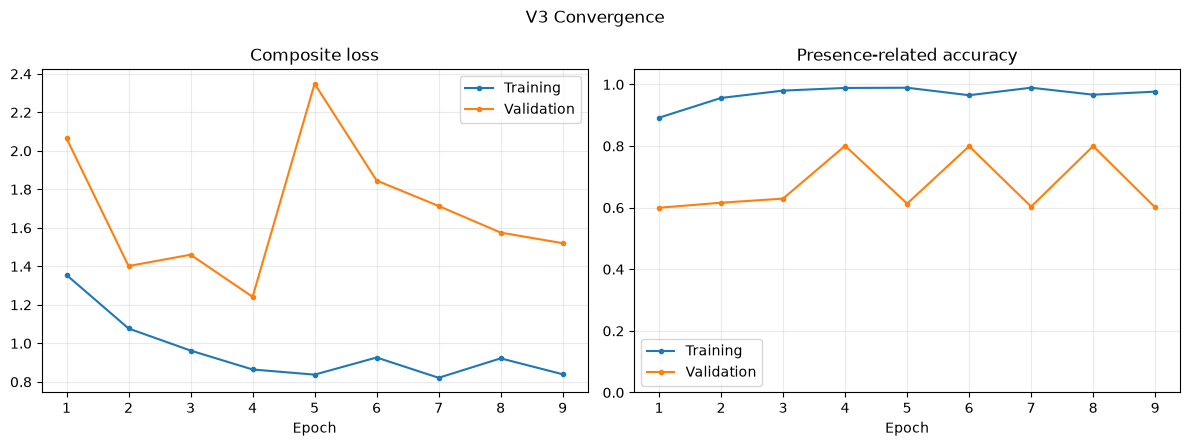

In [21]:
plot_convergence_dashboard(
    v3_history.history,
    'person_count_accuracy',
    'val_person_count_accuracy',
    'V3',
)

### 7.4 Collect V3 validation predictions

In [22]:
v3_best_model = tf.keras.models.load_model(MODEL_DIR / 'baseline_v3_best.keras')
v3_targets_batches = []
v3_prediction_batches = []
for features, targets in validation_dataset:
    v3_targets_batches.append(targets.numpy())
    v3_prediction_batches.append(v3_best_model(features, training=False).numpy())
v3_validation_targets = np.concatenate(v3_targets_batches, axis=0)
v3_validation_predictions = np.concatenate(v3_prediction_batches, axis=0)
print('V3 targets:', v3_validation_targets.shape)
print('V3 predictions:', v3_validation_predictions.shape)

V3 targets: (37500, 4, 3)
V3 predictions: (37500, 4, 3)


### 7.5 V3 official Hungarian evaluation and threshold sweep

In [23]:
v3_threshold_results = [
    evaluate_hungarian(v3_validation_targets, v3_validation_predictions, threshold)
    for threshold in np.arange(0.05, 0.96, 0.05)
]
v3_best_result = max(v3_threshold_results, key=lambda result: result['f1'])
print(json.dumps(v3_best_result, indent=2))

print('V3 best threshold result:')
print(json.dumps(v3_best_result, indent=2))


{
  "threshold": 0.55,
  "tp": 34787,
  "fp": 47531,
  "fn": 40213,
  "precision": 0.42259287154692776,
  "recall": 0.46382666666666666,
  "f1": 0.4422507278251694,
  "matched_mae_m": 0.6072849631309509,
  "matched_p90_m": 0.9219948649406433,
  "count_mae": 0.19626666666666667,
  "count_accuracy": 0.8037333333333333
}
V3 best threshold result:
{
  "threshold": 0.55,
  "tp": 34787,
  "fp": 47531,
  "fn": 40213,
  "precision": 0.42259287154692776,
  "recall": 0.46382666666666666,
  "f1": 0.4422507278251694,
  "matched_mae_m": 0.6072849631309509,
  "matched_p90_m": 0.9219948649406433,
  "count_mae": 0.19626666666666667,
  "count_accuracy": 0.8037333333333333
}


### 7.6 V3 occupancy-level diagnostics

0 people | frames=7,500 | F1=0.0000 | P=0.0000 | R=0.0000 | count acc=0.9929
1 people | frames=7,500 | F1=0.4140 | P=0.4139 | R=0.4140 | count acc=0.9999
2 people | frames=7,500 | F1=0.3857 | P=0.3857 | R=0.3857 | count acc=1.0000
3 people | frames=7,500 | F1=0.4781 | P=0.4197 | R=0.5556 | count acc=0.0287
4 people | frames=7,500 | F1=0.4467 | P=0.4469 | R=0.4466 | count acc=0.9972


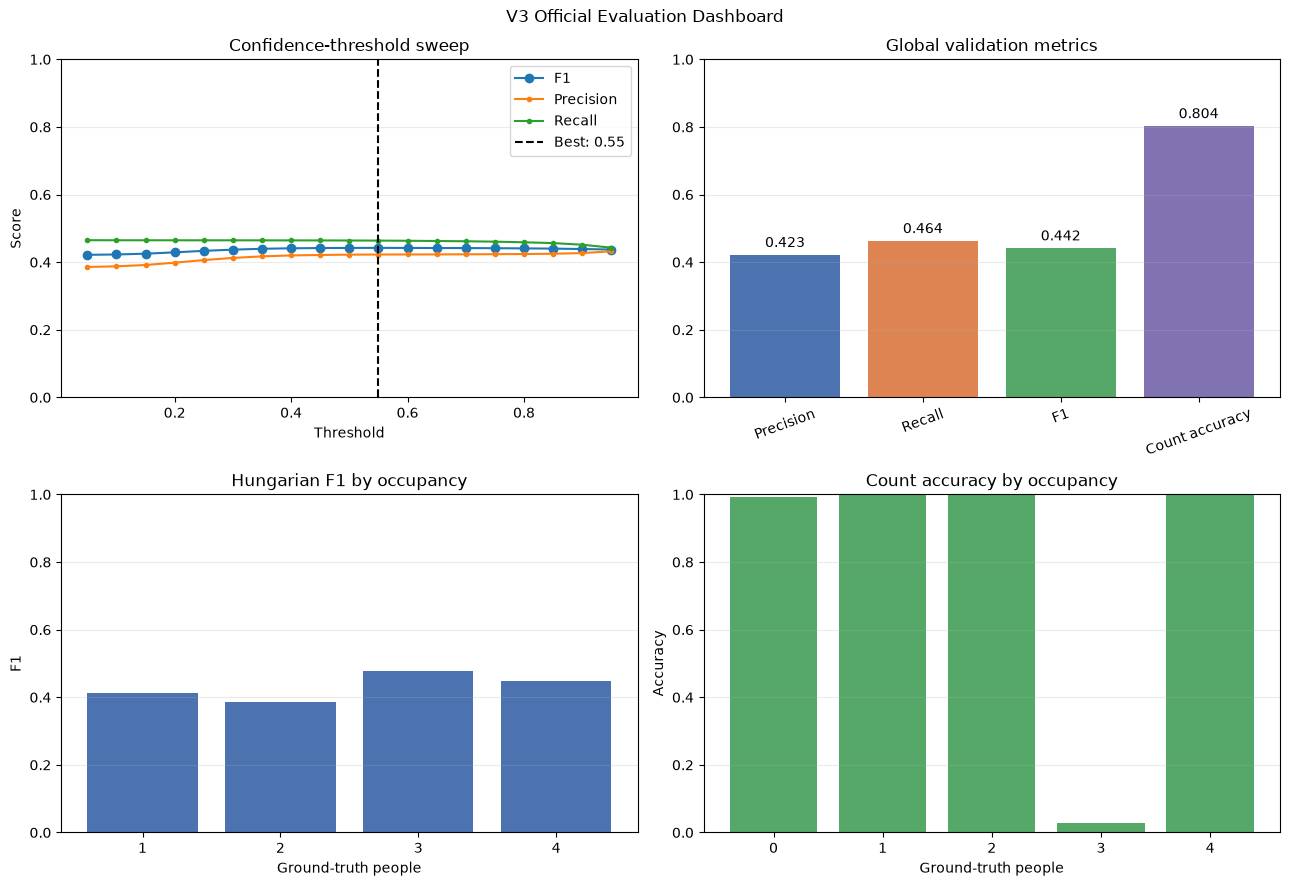

In [24]:
v3_occupancy_results = {}
for people in range(5):
    frame_mask = v3_validation_targets[..., 0].sum(axis=1).astype(int) == people
    result = evaluate_hungarian(
        v3_validation_targets[frame_mask],
        v3_validation_predictions[frame_mask],
        v3_best_result['threshold'],
    )
    v3_occupancy_results[people] = result
    print(f"{people} people | frames={frame_mask.sum():,} | F1={result['f1']:.4f} | P={result['precision']:.4f} | R={result['recall']:.4f} | count acc={result['count_accuracy']:.4f}")

plot_evaluation_dashboard('V3', v3_threshold_results, v3_best_result, v3_occupancy_results)


### 7.7 Save V3 artifacts

In [25]:
v3_experiment = {
    'version': 'V3',
    'parent': 'V2',
    'hypothesis': 'A compressed regularised spatial head and explicit count calibration improve validation generalisation.',
    'filters': list(V3_FILTERS),
    'spatial_projection_filters': V3_SPATIAL_PROJECTION,
    'dense_units': V3_DENSE_UNITS,
    'dropout_rate': V3_DROPOUT_RATE,
    'l2_regularization': V3_L2,
    'localization_weight': V3_LOCALIZATION_WEIGHT,
    'confidence_weight': V3_CONFIDENCE_WEIGHT,
    'count_weight': V3_COUNT_WEIGHT,
    'parameters': int(v3_model.count_params()),
    'best_confidence_threshold': v3_best_result['threshold'],
    'validation_metrics': v3_best_result,
    'parent_v2_f1': 0.49739833162853647,
}
with (ARTIFACT_DIR / 'baseline_v3_experiment.json').open('w', encoding='utf-8') as handle:
    json.dump(v3_experiment, handle, indent=2)
v3_best_model.save(MODEL_DIR / 'baseline_v3_final.keras')
print('Saved V3 model and experiment metadata.')

Saved V3 model and experiment metadata.


### 7.8 V3 results and decision for V4

V3 succeeds at calibration but not at localisation. Its best threshold moves from V2's 0.10 to **0.55**, count MAE improves from 0.2439 to **0.1963**, and count accuracy improves from 0.7574 to **0.8037**. Empty-room count accuracy remains high at 0.9929, while one-, two-, and four-person count accuracies are approximately 1.0. These results support the explicit confidence and count supervision introduced in V3.

However, global Hungarian F1 falls from **0.4974 to 0.4423**. Precision falls to 0.4226, recall to 0.4638, matched MAE worsens to 0.607 m, and matched P90 worsens to 0.922 m. Three-person count accuracy remains extremely low at 0.0287. The reduced 38,804-parameter head therefore removes too much spatial capacity, while the train-validation loss gap remains substantial: training loss reaches approximately 0.84 before early stopping, but the best validation loss is 1.2416.

V3 should not replace V2 as the accuracy candidate. It nevertheless isolates a useful result: count calibration improves when confidence receives more weight and an explicit count penalty is added. V4 therefore returns to the exact 134,996-parameter V2 spatial architecture and changes only the objective to the calibrated V3 formulation. This controlled experiment tests whether V2 geometry and V3 calibration are complementary.

The V4 architecture retains V2's estimated INT8 weight size of approximately 132 KiB, far below the 800 KB Flash limit. Its largest early feature map also remains unchanged, so no additional activation-arena risk is introduced. If V4 does not exceed V2 F1, V2 will be selected for full INT8 conversion rather than adding more model capacity.

## 8. Experiment 4 - V2 spatial capacity with calibrated set loss (V4)

V4 is a controlled combination experiment. It restores the complete V2 spatial head, which achieved the best localisation F1, while retaining the confidence weighting and count penalty validated by V3. No preprocessing, split, convolutional width, or evaluator setting changes.

In [26]:
V4_FILTERS = (24, 32, 48)
V4_DENSE_UNITS = 64
V4_DROPOUT_RATE = 0.15
V4_LOCALIZATION_WEIGHT = 8.0
V4_CONFIDENCE_WEIGHT = 2.0
V4_COUNT_WEIGHT = 0.75
V4_LEARNING_RATE = 5e-4

v4_model = build_baseline_model(
    input_shape=INPUT_SHAPE,
    filters=V4_FILTERS,
    dense_units=V4_DENSE_UNITS,
    dropout_rate=V4_DROPOUT_RATE,
    preserve_spatial_layout=True,
    spatial_projection_filters=None,
    l2_regularization=0.0,
)
v4_model.summary()
print(f'V4 parameters: {v4_model.count_params():,}')
print(f'V4 estimated float32 weight size: {v4_model.count_params() * 4 / 1024:.1f} KiB')
print(f'V4 estimated INT8 weight size: {v4_model.count_params() / 1024:.1f} KiB')
assert v4_model.count_params() == 134996
assert v4_model.count_params() / 1024 < 800

Model: "uwb_tiny_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ radar_input (InputLayer)        │ (None, 6, 3, 120)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ orient_input (Permute)          │ (None, 6, 120, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ range_conv (Conv2D)             │ (None, 6, 60, 24)      │           504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ range_bn (BatchNormalization)   │ (None, 6, 60, 24)      │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ range_relu (ReLU)               │ (None, 6, 60, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_1 (DepthwiseConv2D)   │ (None, 6, 60, 24)      │           216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_bn_1                  │ (None, 6, 60, 24)      │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_relu_1 (ReLU)         │ (None, 6, 60, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_1 (Conv2D)            │ (None, 6, 60, 24)      │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_bn_1                  │ (None, 6, 60, 24)      │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_relu_1 (ReLU)         │ (None, 6, 60, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pool_1                  │ (None, 6, 30, 24)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_2 (DepthwiseConv2D)   │ (None, 6, 30, 24)      │           216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_bn_2                  │ (None, 6, 30, 24)      │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_relu_2 (ReLU)         │ (None, 6, 30, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_2 (Conv2D)            │ (None, 6, 30, 32)      │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_bn_2                  │ (None, 6, 30, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_relu_2 (ReLU)         │ (None, 6, 30, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pool_2                  │ (None, 6, 15, 32)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_3 (DepthwiseConv2D)   │ (None, 6, 15, 32)      │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_bn_3                  │ (None, 6, 15, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 134,996 (527.33 KB)

 Trainable params: 134,452 (525.20 KB)

 Non-trainable params: 544 (2.12 KB)

V4 parameters: 134,996
V4 estimated float32 weight size: 527.3 KiB
V4 estimated INT8 weight size: 131.8 KiB


### 8.1 V4 loss and optimisation

Only the objective changes relative to V2. Confidence weight is doubled and a soft count penalty is added, while localisation weight remains at 8 to preserve V2's geometric emphasis. The lower initial learning rate follows the more stable later phase of V2.

In [27]:
v4_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=V4_LEARNING_RATE),
    loss=PermutationInvariantMultiPersonLoss(
        localization_weight=V4_LOCALIZATION_WEIGHT,
        confidence_weight=V4_CONFIDENCE_WEIGHT,
        count_weight=V4_COUNT_WEIGHT,
        delta=0.1,
    ),
    metrics=[person_count_accuracy],
)
v4_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        MODEL_DIR / 'baseline_v4_best.keras', monitor='val_loss', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True, verbose=1
    ),
]

### 8.2 Train V4

In [28]:
V4_EPOCHS = 25
if TRAIN_V4:
    v4_history = v4_model.fit(
        train_dataset,
        validation_data=validation_fit_dataset,
        steps_per_epoch=TRAIN_STEPS,
        validation_steps=VALIDATION_STEPS,
        epochs=V4_EPOCHS,
        callbacks=v4_callbacks,
        verbose=1,
    )
else:
    from types import SimpleNamespace
    v4_history = SimpleNamespace(history={
        'loss': [1.5580,1.2616,1.1452,1.0417,1.0056,1.0710,0.9509,1.0263,0.9303,0.9426,0.9229,0.9777,0.9067,0.8618,0.8481,0.8799,0.8706,1.1348],
        'val_loss': [1.9044,1.7578,1.9193,1.6139,2.4430,1.8033,1.4353,1.8740,1.1532,2.0165,2.1599,1.2678,1.1501,1.8075,1.3464,1.4110,1.1868,1.4958],
        'person_count_accuracy': [0.8712,0.9617,0.9869,0.9913,0.9910,0.9672,0.9927,0.9663,0.9878,0.9808,0.9900,0.9709,0.9882,0.9936,0.9957,0.9883,0.9915,0.9498],
        'val_person_count_accuracy': [0.4563,0.6452,0.5462,0.7966,0.7160,0.6587,0.6953,0.7364,0.9340,0.7545,0.7383,0.8266,0.9509,0.7974,0.8335,0.8070,0.9200,0.7998],
    })
    print('V4 training skipped; recorded history and preserved checkpoint will be used.')

V4 training skipped; recorded history and preserved checkpoint will be used.


### 8.3 V4 convergence curves

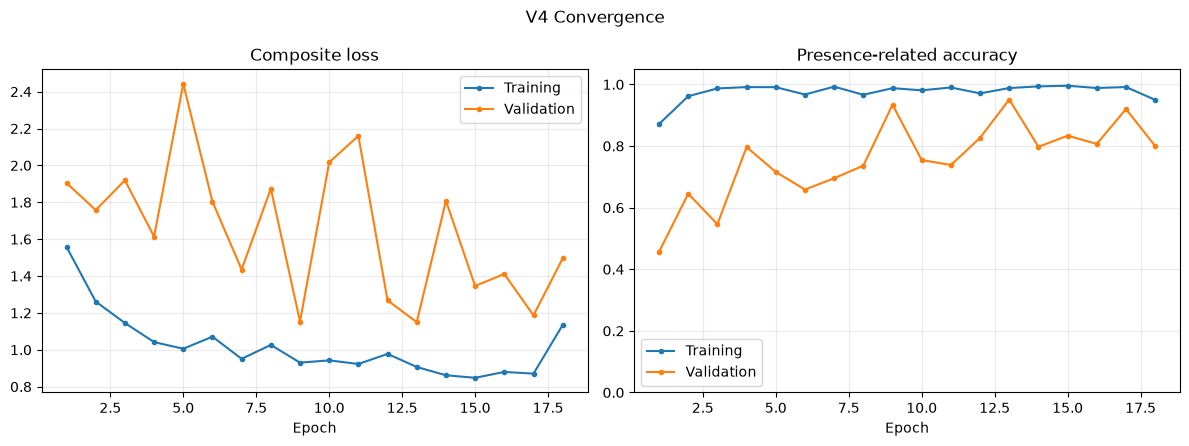

In [29]:
plot_convergence_dashboard(
    v4_history.history,
    'person_count_accuracy',
    'val_person_count_accuracy',
    'V4',
)

### 8.4 Collect V4 validation predictions

In [30]:
v4_best_model = tf.keras.models.load_model(MODEL_DIR / 'baseline_v4_best.keras')
v4_targets_batches = []
v4_prediction_batches = []
for features, targets in validation_dataset:
    v4_targets_batches.append(targets.numpy())
    v4_prediction_batches.append(v4_best_model(features, training=False).numpy())
v4_validation_targets = np.concatenate(v4_targets_batches, axis=0)
v4_validation_predictions = np.concatenate(v4_prediction_batches, axis=0)
print('V4 targets:', v4_validation_targets.shape)
print('V4 predictions:', v4_validation_predictions.shape)

V4 targets: (37500, 4, 3)
V4 predictions: (37500, 4, 3)


### 8.5 V4 official Hungarian evaluation and threshold sweep

In [31]:
v4_threshold_results = [
    evaluate_hungarian(v4_validation_targets, v4_validation_predictions, threshold)
    for threshold in np.arange(0.05, 0.96, 0.05)
]
v4_best_result = max(v4_threshold_results, key=lambda result: result['f1'])
print('V4 best threshold result:')
print(json.dumps(v4_best_result, indent=2))

V4 best threshold result:
{
  "threshold": 0.05,
  "tp": 34750,
  "fp": 47046,
  "fn": 40250,
  "precision": 0.4248374003618759,
  "recall": 0.4633333333333333,
  "f1": 0.4432511033444731,
  "matched_mae_m": 0.6326863765716553,
  "matched_p90_m": 0.9321150779724121,
  "count_mae": 0.18229333333333334,
  "count_accuracy": 0.8177066666666667
}


### 8.6 V4 occupancy-level diagnostics

0 people | frames=7,500 | F1=0.0000 | P=0.0000 | R=0.0000 | count acc=0.7625
1 people | frames=7,500 | F1=0.7068 | P=0.7068 | R=0.7068 | count acc=1.0000
2 people | frames=7,500 | F1=0.4078 | P=0.4078 | R=0.4078 | count acc=1.0000
3 people | frames=7,500 | F1=0.4618 | P=0.4196 | R=0.5135 | count acc=0.3287
4 people | frames=7,500 | F1=0.3928 | P=0.3929 | R=0.3926 | count acc=0.9973


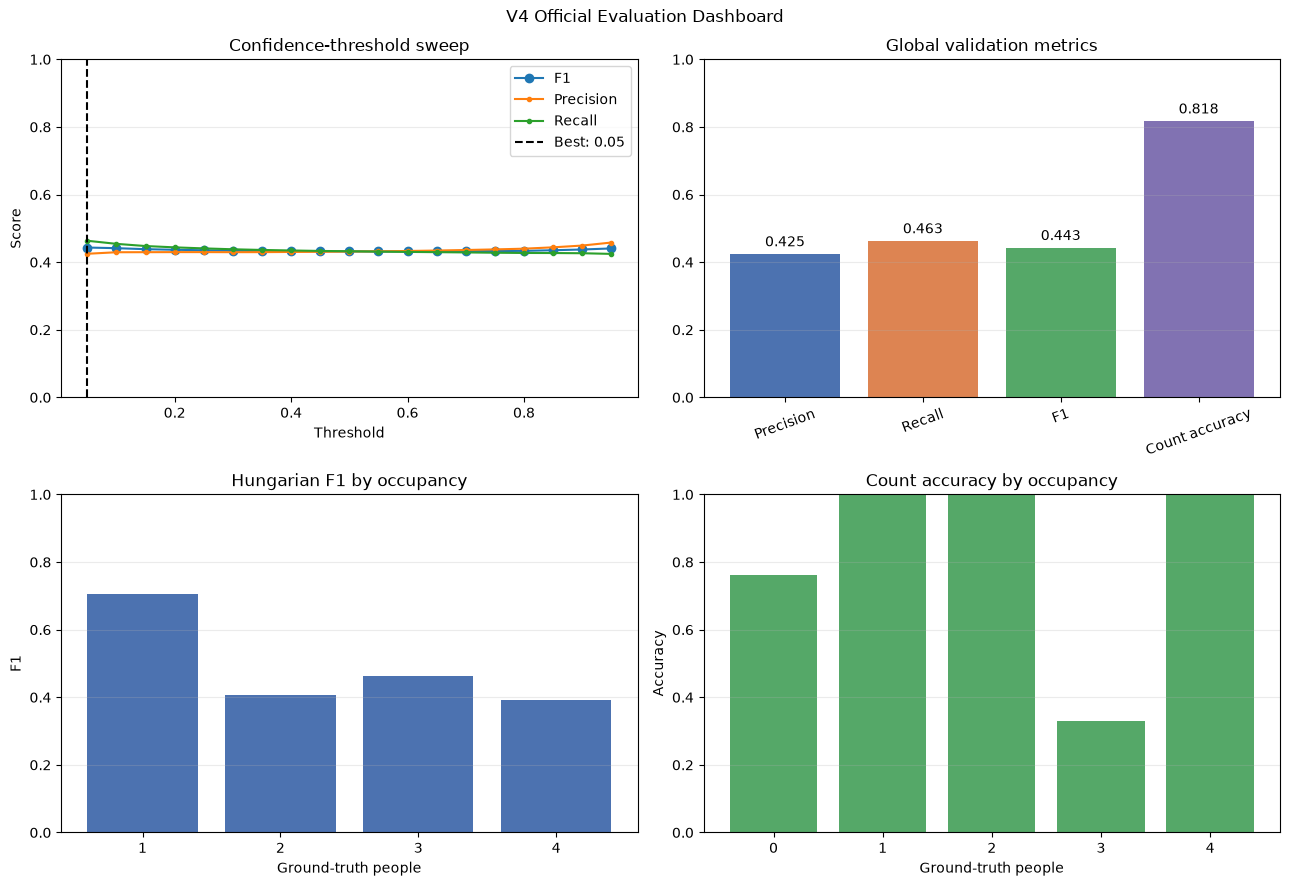

In [32]:
v4_occupancy_results = {}
for people in range(5):
    frame_mask = v4_validation_targets[..., 0].sum(axis=1).astype(int) == people
    result = evaluate_hungarian(
        v4_validation_targets[frame_mask],
        v4_validation_predictions[frame_mask],
        v4_best_result['threshold'],
    )
    v4_occupancy_results[people] = result
    print(f"{people} people | frames={frame_mask.sum():,} | F1={result['f1']:.4f} | P={result['precision']:.4f} | R={result['recall']:.4f} | count acc={result['count_accuracy']:.4f}")

plot_evaluation_dashboard('V4', v4_threshold_results, v4_best_result, v4_occupancy_results)

### 8.7 Save V4 artifacts

In [33]:
v4_experiment = {
    'version': 'V4',
    'parent': 'V2 and V3',
    'hypothesis': 'V2 spatial capacity and V3 count calibration are complementary.',
    'filters': list(V4_FILTERS),
    'dense_units': V4_DENSE_UNITS,
    'dropout_rate': V4_DROPOUT_RATE,
    'localization_weight': V4_LOCALIZATION_WEIGHT,
    'confidence_weight': V4_CONFIDENCE_WEIGHT,
    'count_weight': V4_COUNT_WEIGHT,
    'parameters': int(v4_model.count_params()),
    'estimated_int8_weight_kib': float(v4_model.count_params() / 1024),
    'best_confidence_threshold': v4_best_result['threshold'],
    'validation_metrics': v4_best_result,
    'reference_v2_f1': 0.49739833162853647,
    'reference_v3_f1': 0.4422507278251694,
}
with (ARTIFACT_DIR / 'baseline_v4_experiment.json').open('w', encoding='utf-8') as handle:
    json.dump(v4_experiment, handle, indent=2)
v4_best_model.save(MODEL_DIR / 'baseline_v4_final.keras')
print('Saved V4 model and experiment metadata.')

Saved V4 model and experiment metadata.


### 8.8 V4 results and edge-candidate decision

V4 does not confirm that V2 spatial capacity and V3 calibration are complementary. Count accuracy improves to **0.8177** and count MAE improves to **0.1823**, the best counting results among the four versions. Nevertheless, global Hungarian F1 is only **0.4433**, essentially equal to V3 and clearly below V2's 0.4974. Precision is 0.4248, recall is 0.4633, matched MAE worsens to 0.633 m, and matched P90 reaches 0.932 m.

The optimal confidence threshold falls further to **0.05**, so the count penalty does not calibrate the V2 head as expected. Empty-room count accuracy also falls to 0.7625. Although one-person F1 remains reasonable at 0.7068 and count accuracy is high for one, two, and four people, three-person count accuracy is only 0.3287 and four-person F1 falls to 0.3928.

Training count accuracy approaches 0.99 while validation loss remains volatile, confirming that the large spatial head continues to learn acquisition-specific confidence patterns. Increasing the confidence/count contribution improves discrete counts but moves capacity away from coordinate quality and does not improve the official objective.

V4 is therefore retained as a negative but informative experiment. **V2 remains the current float accuracy candidate** because it has the highest global F1 (0.4974), highest recall (0.5219), and best overall localisation trade-off. V3 remains the most compact calibrated alternative, but its lower F1 does not justify selecting it before edge measurements.

Before quantising V2, one final representation experiment is justified by a limitation shared by V1-V4: every version converts the complex radar samples to magnitude. This removes signed quadrature and phase relationships across the three antennas, even though those relationships contain angular information needed for 2D localisation. V5 therefore restores the exact V2 model and loss but preserves I and Q as six signed antenna channels. This isolates input representation without another architecture search.

The edge cost remains modest: the INT8 input grows from 2,160 to 4,320 values (approximately 4.2 KiB), the first convolution output activation is unchanged, and only the first convolution receives additional input channels. The model remains far below the 800 KB Flash limit and does not introduce new operator types. If V5 does not exceed V2's F1, V2 will proceed immediately to full INT8 conversion and official Flash, activation-arena, operator, and accuracy checks.

## 9. Experiment 5 - Signed I/Q antenna channels (V5)

V5 isolates the input-representation hypothesis. Model capacity, spatial head, loss, split, target construction, optimiser schedule, and official evaluation return to V2 settings. The only substantive change is preserving signed I/Q information instead of collapsing it to magnitude.

### 9.1 Load the signed I/Q preprocessing contract

V5 does not estimate preprocessing statistics inside the training notebook. It loads the train-only 6x6 radar/channel statistics produced by `03b_preprocessing_signed_iq.ipynb`. This keeps preprocessing decisions auditable and prevents accidental differences between training runs.


In [34]:
V5_STATS_PATH = ARTIFACT_DIR / 'v5_iq_normalization.json'
if not V5_STATS_PATH.exists():
    raise FileNotFoundError(
        'Missing V5 preprocessing artifact. Run src/03b_preprocessing_signed_iq.ipynb first.'
    )
with V5_STATS_PATH.open(encoding='utf-8') as handle:
    v5_stats = json.load(handle)
if 'config' not in v5_stats:
    raise ValueError(
        'The V5 artifact uses the old format. Re-run src/03b_preprocessing_signed_iq.ipynb.'
    )
v5_config_values = v5_stats['config'].copy()
v5_config_values['radar_indices'] = tuple(v5_config_values['radar_indices'])
V5_CONFIG = PreprocessingConfig(**v5_config_values)
V5_CONFIG.validate()
V5_IQ_MEAN = np.asarray(v5_stats['mean'], dtype=np.float32)
V5_IQ_STD = np.asarray(v5_stats['std'], dtype=np.float32)
assert v5_stats['representation'] == 'signed_iq'
assert v5_stats['channel_order'] == ['A0-I', 'A0-Q', 'A1-I', 'A1-Q', 'A2-I', 'A2-Q']
assert V5_IQ_MEAN.shape == V5_IQ_STD.shape == (6, 6)
assert np.all(V5_IQ_STD > 0)
print('Loaded:', V5_STATS_PATH.resolve())
print('V5 I/Q std range:', float(V5_IQ_STD.min()), float(V5_IQ_STD.max()))

Loaded: C:\Users\213053\OneDrive\Documenti\EEAI\src\artifacts\v5_iq_normalization.json
V5 I/Q std range: 3.7532403469085693 5.646988391876221


### 9.2 V5 streaming dataset

The V5 generator retains the same chunking and batch sizes. Signed I/Q features are normalised with the train-only 6x6 statistics. Previous model datasets remain unchanged.

In [35]:
V5_INPUT_SHAPE = (6, 6, 120)

def v5_window_chunk_generator(indices, shuffle):
    ordered_indices = list(indices)
    if shuffle:
        np.random.shuffle(ordered_indices)
    for window_index in ordered_indices:
        with np.load(window_paths[window_index], allow_pickle=False) as data:
            radar = data['radar_cir_iq']
            people_xy = data['people_xy']
            people_mask = data['people_mask']
            starts = list(range(0, len(radar), CHUNK_SIZE))
            if shuffle:
                np.random.shuffle(starts)
            for start in starts:
                stop = min(start + CHUNK_SIZE, len(radar))
                features = transform_signed_iq_channels(radar[start:stop], V5_CONFIG)
                features = normalize_per_radar_channel(
                    features, V5_IQ_MEAN, V5_IQ_STD, V5_CONFIG.epsilon
                )
                targets = build_sorted_targets(people_xy[start:stop], people_mask[start:stop])
                yield features, targets

v5_output_signature = (
    tf.TensorSpec(shape=(None,) + V5_INPUT_SHAPE, dtype=tf.float32),
    tf.TensorSpec(shape=(None, 4, 3), dtype=tf.float32),
)

def make_v5_dataset(indices, training, repeat=False):
    dataset = tf.data.Dataset.from_generator(
        lambda: v5_window_chunk_generator(indices, shuffle=training),
        output_signature=v5_output_signature,
    ).unbatch()
    if training:
        dataset = dataset.shuffle(8192, seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.batch(BATCH_SIZE)
    if repeat:
        dataset = dataset.repeat()
    return dataset.prefetch(tf.data.AUTOTUNE)

v5_train_dataset = make_v5_dataset(TRAIN_WINDOWS, training=True, repeat=True)
v5_validation_fit_dataset = make_v5_dataset(VALIDATION_WINDOWS, training=False, repeat=True)
v5_validation_dataset = make_v5_dataset(VALIDATION_WINDOWS, training=False, repeat=False)
v5_sample_features, v5_sample_targets = next(iter(v5_train_dataset))
print('V5 feature batch:', v5_sample_features.shape)
print('V5 feature range:', float(tf.reduce_min(v5_sample_features)), float(tf.reduce_max(v5_sample_features)))

V5 feature batch: (128, 6, 6, 120)
V5 feature range: -2.461472988128662 2.39422607421875


### 9.3 V5 model and technical-cost estimate

V5 restores the best V2 architecture. Doubling input channels changes only the first convolution's kernel depth; downstream activation shapes remain identical. The parameter and INT8 estimates are checked before training.

In [36]:
V5_FILTERS = (24, 32, 48)
V5_DENSE_UNITS = 64
V5_DROPOUT_RATE = 0.15
V5_LOCALIZATION_WEIGHT = 8.0
V5_LEARNING_RATE = 5e-4

v5_model = build_baseline_model(
    input_shape=V5_INPUT_SHAPE,
    filters=V5_FILTERS,
    dense_units=V5_DENSE_UNITS,
    dropout_rate=V5_DROPOUT_RATE,
    preserve_spatial_layout=True,
)
v5_model.summary()
V5_PARAMETERS = v5_model.count_params()
print(f'V5 parameters: {V5_PARAMETERS:,}')
print(f'V5 estimated INT8 weight size: {V5_PARAMETERS / 1024:.1f} KiB')
print(f'V5 INT8 input tensor: {np.prod(V5_INPUT_SHAPE) / 1024:.1f} KiB')
assert V5_PARAMETERS / 1024 < 800
assert np.prod(V5_INPUT_SHAPE) < 300 * 1024

Model: "uwb_tiny_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ radar_input (InputLayer)        │ (None, 6, 6, 120)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ orient_input (Permute)          │ (None, 6, 120, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ range_conv (Conv2D)             │ (None, 6, 60, 24)      │         1,008 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ range_bn (BatchNormalization)   │ (None, 6, 60, 24)      │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ range_relu (ReLU)               │ (None, 6, 60, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_1 (DepthwiseConv2D)   │ (None, 6, 60, 24)      │           216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_bn_1                  │ (None, 6, 60, 24)      │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_relu_1 (ReLU)         │ (None, 6, 60, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_1 (Conv2D)            │ (None, 6, 60, 24)      │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_bn_1                  │ (None, 6, 60, 24)      │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_relu_1 (ReLU)         │ (None, 6, 60, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pool_1                  │ (None, 6, 30, 24)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_2 (DepthwiseConv2D)   │ (None, 6, 30, 24)      │           216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_bn_2                  │ (None, 6, 30, 24)      │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_relu_2 (ReLU)         │ (None, 6, 30, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_2 (Conv2D)            │ (None, 6, 30, 32)      │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_bn_2                  │ (None, 6, 30, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_relu_2 (ReLU)         │ (None, 6, 30, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pool_2                  │ (None, 6, 15, 32)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_3 (DepthwiseConv2D)   │ (None, 6, 15, 32)      │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_bn_3                  │ (None, 6, 15, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 135,500 (529.30 KB)

 Trainable params: 134,956 (527.17 KB)

 Non-trainable params: 544 (2.12 KB)

V5 parameters: 135,500
V5 estimated INT8 weight size: 132.3 KiB
V5 INT8 input tensor: 4.2 KiB


### 9.4 V5 loss and optimisation

V5 returns exactly to the V2 permutation-invariant objective. This avoids the count/localisation competition observed in V3 and V4, making signed I/Q representation the isolated experimental variable.

In [37]:
v5_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=V5_LEARNING_RATE),
    loss=PermutationInvariantMultiPersonLoss(
        localization_weight=V5_LOCALIZATION_WEIGHT,
        confidence_weight=1.0,
        count_weight=0.0,
        delta=0.1,
    ),
    metrics=[person_count_accuracy],
)
v5_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(MODEL_DIR / 'baseline_v5_best.keras', monitor='val_loss', save_best_only=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
]

### 9.5 Train V5

In [38]:
V5_EPOCHS = 25
if TRAIN_V5:
    v5_history = v5_model.fit(
        v5_train_dataset,
        validation_data=v5_validation_fit_dataset,
        steps_per_epoch=TRAIN_STEPS,
        validation_steps=VALIDATION_STEPS,
        epochs=V5_EPOCHS,
        callbacks=v5_callbacks,
        verbose=1,
    )
    v5_history_record = v5_history.history
else:
    v5_history_record = {
        'loss': [1.2230, 1.0247, 0.9630, 0.8680, 0.8517, 0.8149, 0.7917, 0.7948, 0.9111, 0.8757, 0.8626, 0.8377, 0.8869, 0.7954, 0.8210, 0.8828, 0.8145, 0.7896, 0.8762],
        'val_loss': [1.3175, 1.1652, 1.1685, 1.1799, 1.2060, 1.0771, 1.1289, 1.4447, 1.3242, 1.1033, 1.0629, 1.2590, 1.0556, 0.9853, 1.1582, 1.0564, 1.0269, 1.0327, 1.2408],
        'person_count_accuracy': [0.6387, 0.7756, 0.7903, 0.8460, 0.8594, 0.8717, 0.8851, 0.8850, 0.7816, 0.8070, 0.8395, 0.8489, 0.7949, 0.9010, 0.8533, 0.7938, 0.8630, 0.8769, 0.8108],
        'val_person_count_accuracy': [0.7857, 0.6376, 0.7603, 0.7097, 0.7564, 0.8775, 0.6664, 0.5376, 0.5207, 0.7984, 0.7203, 0.5935, 0.8178, 0.8569, 0.6609, 0.6654, 0.8900, 0.8317, 0.7266],
    }
    print('V5 training skipped; using the recorded convergence history.')

V5 training skipped; using the recorded convergence history.


### 9.6 V5 convergence curves

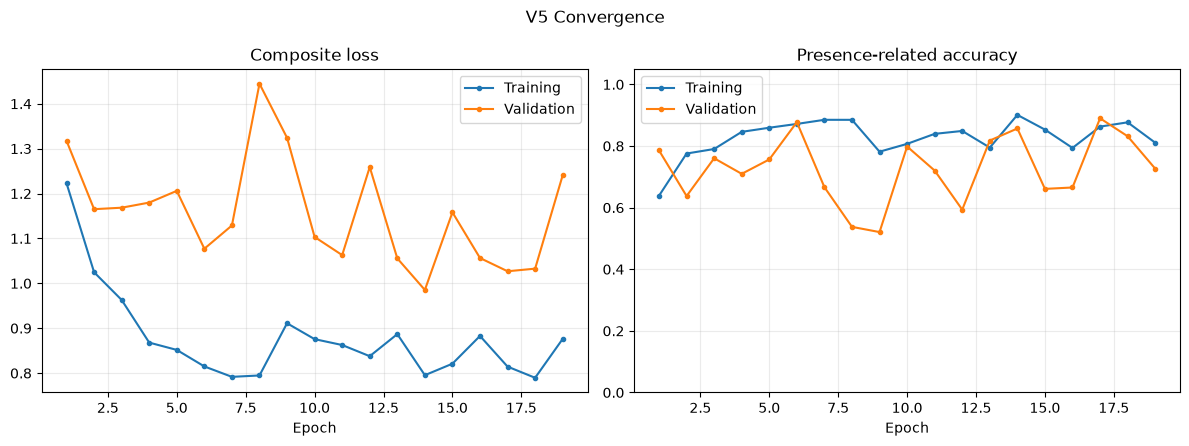

In [39]:
plot_convergence_dashboard(v5_history_record, 'person_count_accuracy', 'val_person_count_accuracy', 'V5')

### 9.7 V5 validation predictions and official Hungarian evaluation

In [40]:
v5_best_model = tf.keras.models.load_model(MODEL_DIR / 'baseline_v5_best.keras')
v5_target_batches, v5_prediction_batches = [], []
for features, targets in v5_validation_dataset:
    v5_target_batches.append(targets.numpy())
    v5_prediction_batches.append(v5_best_model(features, training=False).numpy())
v5_validation_targets = np.concatenate(v5_target_batches, axis=0)
v5_validation_predictions = np.concatenate(v5_prediction_batches, axis=0)
v5_threshold_results = [
    evaluate_hungarian(v5_validation_targets, v5_validation_predictions, threshold)
    for threshold in np.arange(0.05, 0.96, 0.05)
]
v5_best_result = max(v5_threshold_results, key=lambda result: result['f1'])
print(json.dumps(v5_best_result, indent=2))

{
  "threshold": 0.3,
  "tp": 39100,
  "fp": 43062,
  "fn": 35900,
  "precision": 0.47588909714953387,
  "recall": 0.5213333333333333,
  "f1": 0.49757574986319847,
  "matched_mae_m": 0.5874950885772705,
  "matched_p90_m": 0.9109871983528137,
  "count_mae": 0.22202666666666668,
  "count_accuracy": 0.78952
}


### 9.8 V5 occupancy diagnostics and common dashboard

0 people | F1=0.0000 | P=0.0000 | R=0.0000 | count acc=0.9519
1 people | F1=0.7231 | P=0.7290 | R=0.7173 | count acc=0.8747
2 people | F1=0.5625 | P=0.4796 | R=0.6799 | count acc=0.2107
3 people | F1=0.4561 | P=0.4496 | R=0.4628 | count acc=0.9115
4 people | F1=0.4370 | P=0.4370 | R=0.4369 | count acc=0.9989


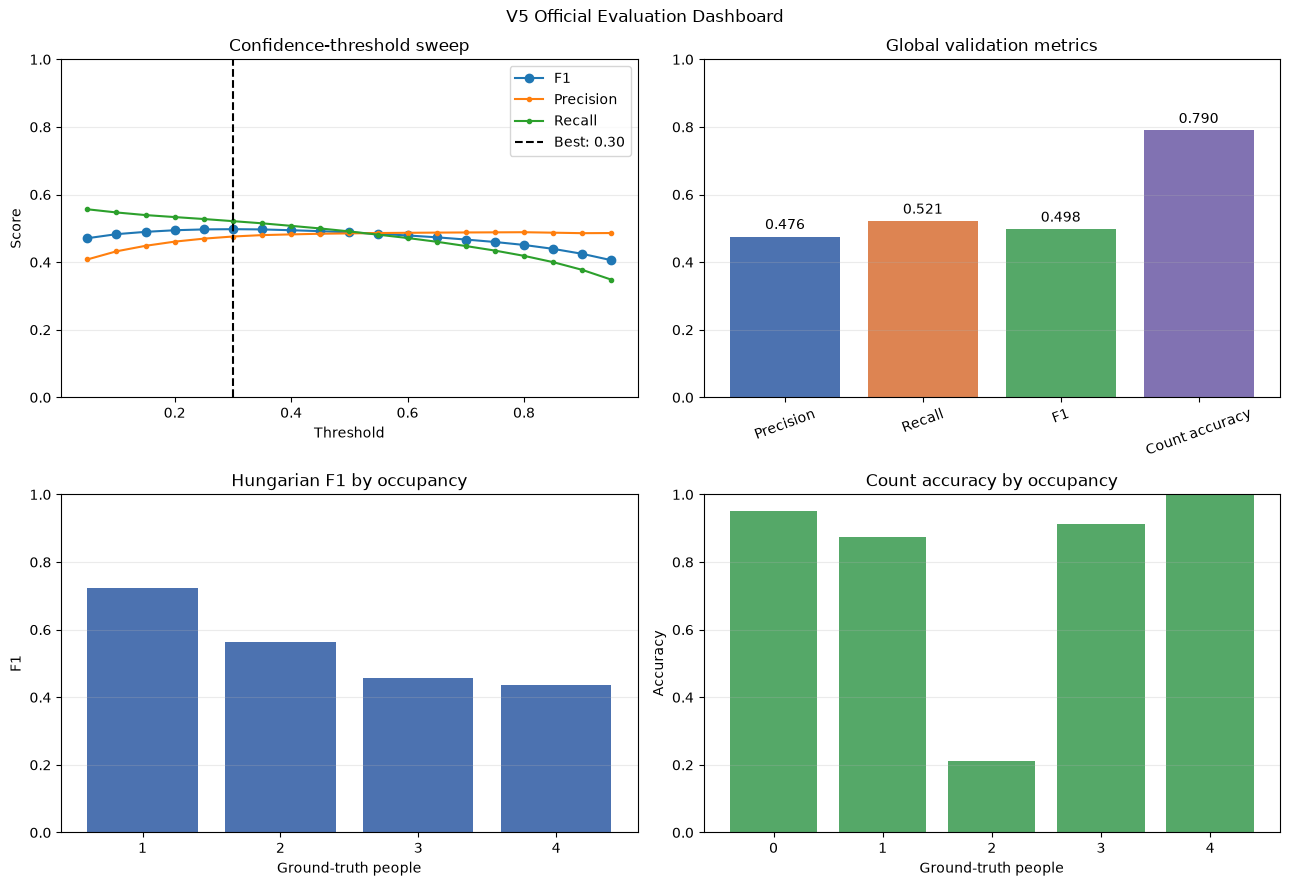

In [41]:
v5_occupancy_results = {}
for people in range(5):
    frame_mask = v5_validation_targets[..., 0].sum(axis=1).astype(int) == people
    result = evaluate_hungarian(v5_validation_targets[frame_mask], v5_validation_predictions[frame_mask], v5_best_result['threshold'])
    v5_occupancy_results[people] = result
    print(f"{people} people | F1={result['f1']:.4f} | P={result['precision']:.4f} | R={result['recall']:.4f} | count acc={result['count_accuracy']:.4f}")
plot_evaluation_dashboard('V5', v5_threshold_results, v5_best_result, v5_occupancy_results)

### 9.9 Save V5 artifacts

In [42]:
v5_experiment = {
    'version': 'V5', 'parent': 'V2',
    'hypothesis': 'Signed I/Q antenna channels improve angular and multi-person localisation over magnitude-only input.',
    'input_shape': list(V5_INPUT_SHAPE), 'parameters': int(V5_PARAMETERS),
    'estimated_int8_weight_kib': float(V5_PARAMETERS / 1024),
    'estimated_int8_input_kib': float(np.prod(V5_INPUT_SHAPE) / 1024),
    'best_confidence_threshold': v5_best_result['threshold'],
    'validation_metrics': v5_best_result, 'reference_v2_f1': 0.49739833162853647,
}
with (ARTIFACT_DIR / 'baseline_v5_experiment.json').open('w', encoding='utf-8') as handle:
    json.dump(v5_experiment, handle, indent=2)
v5_best_model.save(MODEL_DIR / 'baseline_v5_final.keras')
print('Saved V5 model and experiment metadata.')

Saved V5 model and experiment metadata.


### 9.10 V5 result and model-selection decision

V5 reaches a global Hungarian F1 of **0.4976**, only 0.0002 above V2's 0.4974. This difference is too small to establish an overall improvement. Precision (0.4759) and recall (0.5213) are also effectively unchanged. Moreover, matched MAE worsens from 0.553 m to 0.587 m and matched P90 worsens from 0.890 m to 0.911 m. Signed I/Q alone therefore does not replace magnitude as a clearly superior representation.

The occupancy breakdown nevertheless provides a new, testable result. Two-person F1 rises from **0.3816 in V2 to 0.5625 in V5**, whereas one-person F1 falls from **0.8391 to 0.7231**. Magnitude appears to provide a robust energy/localisation cue for simple scenes, while signed quadrature contributes complementary information in ambiguous multi-person scenes. V6 therefore tests a fused magnitude plus signed-I/Q representation while keeping the V2/V5 architecture, loss, split, and evaluator fixed. This is a representation ablation rather than an unconstrained architecture search.

## 10. Experiment 6 - Fused magnitude and signed I/Q (V6)

V6 tests the complementary-representation hypothesis derived from V2 and V5. It concatenates log-magnitude and signed-log I/Q channels but keeps the V2/V5 architecture, permutation-invariant loss, split, target construction, optimiser, and official Hungarian evaluator unchanged.

### 10.1 Load the fused preprocessing contract

The train-only 6-by-9 statistics and channel order are produced by `03c_preprocessing_fused_magnitude_iq.ipynb`. No preprocessing statistics are estimated in this training notebook.

In [43]:
V6_STATS_PATH = ARTIFACT_DIR / 'v6_fused_normalization.json'
if not V6_STATS_PATH.exists():
    raise FileNotFoundError(
        'Missing V6 preprocessing artifact. Run src/03c_preprocessing_fused_magnitude_iq.ipynb first.'
    )
with V6_STATS_PATH.open(encoding='utf-8') as handle:
    v6_stats = json.load(handle)
v6_config_values = v6_stats['config'].copy()
v6_config_values['radar_indices'] = tuple(v6_config_values['radar_indices'])
V6_CONFIG = PreprocessingConfig(**v6_config_values)
V6_CONFIG.validate()
V6_MEAN = np.asarray(v6_stats['mean'], dtype=np.float32)
V6_STD = np.asarray(v6_stats['std'], dtype=np.float32)
V6_CHANNEL_ORDER = [
    'A0-mag', 'A1-mag', 'A2-mag',
    'A0-I', 'A0-Q', 'A1-I', 'A1-Q', 'A2-I', 'A2-Q',
]
assert v6_stats['representation'] == 'fused_magnitude_signed_iq'
assert v6_stats['channel_order'] == V6_CHANNEL_ORDER
assert V6_MEAN.shape == V6_STD.shape == (6, 9)
assert np.all(V6_STD > 0)
assert v6_stats['training_windows'] == TRAIN_WINDOWS
assert v6_stats['validation_windows'] == VALIDATION_WINDOWS
print('Loaded:', V6_STATS_PATH.resolve())
print('V6 standard-deviation range:', float(V6_STD.min()), float(V6_STD.max()))

Loaded: C:\Users\213053\OneDrive\Documenti\EEAI\src\artifacts\v6_fused_normalization.json
V6 standard-deviation range: 1.48440682888031 5.646988391876221


### 10.2 V6 streaming dataset

In [44]:
V6_INPUT_SHAPE = (6, 9, 120)

def v6_window_chunk_generator(indices, shuffle):
    ordered_indices = list(indices)
    if shuffle:
        np.random.shuffle(ordered_indices)
    for window_index in ordered_indices:
        with np.load(window_paths[window_index], allow_pickle=False) as data:
            radar = data['radar_cir_iq']
            people_xy = data['people_xy']
            people_mask = data['people_mask']
            starts = list(range(0, len(radar), CHUNK_SIZE))
            if shuffle:
                np.random.shuffle(starts)
            for start in starts:
                stop = min(start + CHUNK_SIZE, len(radar))
                features = transform_fused_magnitude_iq(radar[start:stop], V6_CONFIG)
                features = normalize_per_radar_channel(
                    features, V6_MEAN, V6_STD, V6_CONFIG.epsilon
                )
                targets = build_sorted_targets(
                    people_xy[start:stop], people_mask[start:stop]
                )
                yield features, targets

v6_output_signature = (
    tf.TensorSpec(shape=(None,) + V6_INPUT_SHAPE, dtype=tf.float32),
    tf.TensorSpec(shape=(None, 4, 3), dtype=tf.float32),
)

def make_v6_dataset(indices, training, repeat=False):
    dataset = tf.data.Dataset.from_generator(
        lambda: v6_window_chunk_generator(indices, shuffle=training),
        output_signature=v6_output_signature,
    ).unbatch()
    if training:
        dataset = dataset.shuffle(8192, seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.batch(BATCH_SIZE)
    if repeat:
        dataset = dataset.repeat()
    return dataset.prefetch(tf.data.AUTOTUNE)

v6_train_dataset = make_v6_dataset(TRAIN_WINDOWS, training=True, repeat=True)
v6_validation_fit_dataset = make_v6_dataset(VALIDATION_WINDOWS, training=False, repeat=True)
v6_validation_dataset = make_v6_dataset(VALIDATION_WINDOWS, training=False)
v6_sample_features, v6_sample_targets = next(iter(v6_train_dataset))
print('V6 feature batch:', v6_sample_features.shape)
print('V6 feature range:', float(tf.reduce_min(v6_sample_features)), float(tf.reduce_max(v6_sample_features)))

V6 feature batch: (128, 6, 9, 120)
V6 feature range: -3.702247381210327 2.902369260787964


### 10.3 V6 model and technical-cost estimate

V6 reuses the V2/V5 model. Increasing the input from six to nine feature channels changes only the first convolution kernel. Its output remains `(6, 60, 24)`, so the principal early activation is unchanged. The estimates below are screening checks; the final limits must still be measured on the converted INT8 model.

In [45]:
V6_FILTERS = (24, 32, 48)
V6_DENSE_UNITS = 64
V6_DROPOUT_RATE = 0.15
V6_LOCALIZATION_WEIGHT = 8.0
V6_LEARNING_RATE = 5e-4

v6_model = build_baseline_model(
    input_shape=V6_INPUT_SHAPE, filters=V6_FILTERS,
    dense_units=V6_DENSE_UNITS, dropout_rate=V6_DROPOUT_RATE,
    preserve_spatial_layout=True,
)
v6_model.summary()
V6_PARAMETERS = v6_model.count_params()
V6_ESTIMATED_INT8_WEIGHT_KIB = V6_PARAMETERS / 1024
V6_INT8_INPUT_KIB = np.prod(V6_INPUT_SHAPE) / 1024
V6_FIRST_ACTIVATION_KIB = 6 * 60 * 24 / 1024
print(f'V6 parameters: {V6_PARAMETERS:,}')
print(f'Estimated INT8 weights: {V6_ESTIMATED_INT8_WEIGHT_KIB:.1f} KiB')
print(f'INT8 input tensor: {V6_INT8_INPUT_KIB:.1f} KiB')
print(f'First convolution activation: {V6_FIRST_ACTIVATION_KIB:.1f} KiB')
assert V6_ESTIMATED_INT8_WEIGHT_KIB < 800
assert V6_INT8_INPUT_KIB < 300
assert V6_FIRST_ACTIVATION_KIB < 300

Model: "uwb_tiny_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ radar_input (InputLayer)        │ (None, 6, 9, 120)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ orient_input (Permute)          │ (None, 6, 120, 9)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ range_conv (Conv2D)             │ (None, 6, 60, 24)      │         1,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ range_bn (BatchNormalization)   │ (None, 6, 60, 24)      │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ range_relu (ReLU)               │ (None, 6, 60, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_1 (DepthwiseConv2D)   │ (None, 6, 60, 24)      │           216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_bn_1                  │ (None, 6, 60, 24)      │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_relu_1 (ReLU)         │ (None, 6, 60, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_1 (Conv2D)            │ (None, 6, 60, 24)      │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_bn_1                  │ (None, 6, 60, 24)      │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_relu_1 (ReLU)         │ (None, 6, 60, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pool_1                  │ (None, 6, 30, 24)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_2 (DepthwiseConv2D)   │ (None, 6, 30, 24)      │           216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_bn_2                  │ (None, 6, 30, 24)      │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_relu_2 (ReLU)         │ (None, 6, 30, 24)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_2 (Conv2D)            │ (None, 6, 30, 32)      │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_bn_2                  │ (None, 6, 30, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pointwise_relu_2 (ReLU)         │ (None, 6, 30, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pool_2                  │ (None, 6, 15, 32)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_3 (DepthwiseConv2D)   │ (None, 6, 15, 32)      │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_bn_3                  │ (None, 6, 15, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 136,004 (531.27 KB)

 Trainable params: 135,460 (529.14 KB)

 Non-trainable params: 544 (2.12 KB)

V6 parameters: 136,004
Estimated INT8 weights: 132.8 KiB
INT8 input tensor: 6.3 KiB
First convolution activation: 8.4 KiB


### 10.4 V6 loss and optimisation

The exact V2/V5 permutation-invariant objective is retained so that input representation is the only substantive experimental variable.

In [46]:
v6_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=V6_LEARNING_RATE),
    loss=PermutationInvariantMultiPersonLoss(
        localization_weight=V6_LOCALIZATION_WEIGHT,
        confidence_weight=1.0, count_weight=0.0, delta=0.1,
    ),
    metrics=[person_count_accuracy],
)
v6_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        MODEL_DIR / 'baseline_v6_best.keras', monitor='val_loss',
        save_best_only=True, verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True, verbose=1,
    ),
]

### 10.5 Train V6

In [47]:
V6_EPOCHS = 25
if TRAIN_V6:
    v6_history = v6_model.fit(
        v6_train_dataset, validation_data=v6_validation_fit_dataset,
        steps_per_epoch=TRAIN_STEPS, validation_steps=VALIDATION_STEPS,
        epochs=V6_EPOCHS, callbacks=v6_callbacks, verbose=1,
    )
    v6_history_record = v6_history.history
else:
    v6_history_record = {
        'loss': [1.2292, 1.0479, 0.9418, 0.9149, 0.9056, 0.8351, 0.8660, 0.7977, 0.7595, 0.7549, 0.8185, 0.7655, 0.8493, 0.8448, 0.8013],
        'val_loss': [1.3296, 1.3513, 1.3620, 1.0905, 1.8529, 1.0350, 1.1794, 1.0478, 1.1121, 0.8940, 1.0434, 1.2468, 1.9069, 1.0603, 1.0210],
        'person_count_accuracy': [0.6481, 0.7720, 0.8954, 0.8983, 0.8896, 0.9183, 0.9034, 0.9308, 0.9625, 0.9544, 0.9024, 0.9399, 0.8866, 0.8820, 0.9159],
        'val_person_count_accuracy': [0.5686, 0.5494, 0.7001, 0.8919, 0.4713, 0.7246, 0.7619, 0.8555, 0.7579, 0.9358, 0.9206, 0.7778, 0.5019, 0.8022, 0.9219],
    }
    print('V6 training skipped; using the recorded convergence history.')

V6 training skipped; using the recorded convergence history.


### 10.6 V6 convergence curves

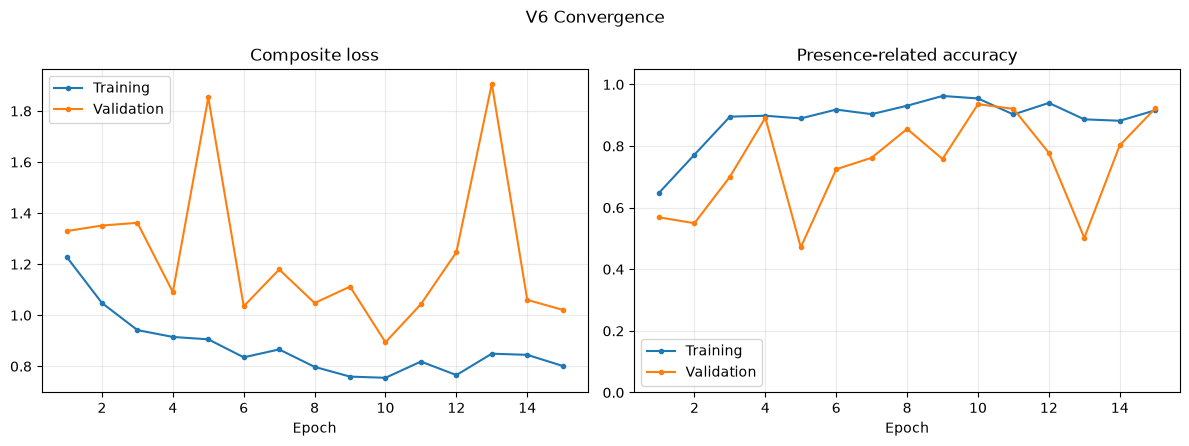

In [48]:
plot_convergence_dashboard(
    v6_history_record, 'person_count_accuracy',
    'val_person_count_accuracy', 'V6',
)

### 10.7 V6 validation predictions and official Hungarian evaluation

In [49]:
v6_best_model = tf.keras.models.load_model(MODEL_DIR / 'baseline_v6_best.keras')
v6_target_batches, v6_prediction_batches = [], []
for features, targets in v6_validation_dataset:
    v6_target_batches.append(targets.numpy())
    v6_prediction_batches.append(v6_best_model(features, training=False).numpy())
v6_validation_targets = np.concatenate(v6_target_batches, axis=0)
v6_validation_predictions = np.concatenate(v6_prediction_batches, axis=0)
v6_threshold_results = [
    evaluate_hungarian(v6_validation_targets, v6_validation_predictions, threshold)
    for threshold in np.arange(0.05, 0.96, 0.05)
]
v6_best_result = max(v6_threshold_results, key=lambda result: result['f1'])
print(json.dumps(v6_best_result, indent=2))

{
  "threshold": 0.3,
  "tp": 39728,
  "fp": 36251,
  "fn": 35272,
  "precision": 0.5228813224706826,
  "recall": 0.5297066666666667,
  "f1": 0.526271865623696,
  "matched_mae_m": 0.5973987579345703,
  "matched_p90_m": 0.9175965189933777,
  "count_mae": 0.056773333333333335,
  "count_accuracy": 0.9432266666666667
}


### 10.8 V6 occupancy diagnostics and common dashboard

0 people | F1=0.0000 | P=0.0000 | R=0.0000 | count acc=0.9996
1 people | F1=0.7336 | P=0.7468 | R=0.7208 | count acc=0.8817
2 people | F1=0.4753 | P=0.4753 | R=0.4753 | count acc=1.0000
3 people | F1=0.4660 | P=0.4538 | R=0.4788 | count acc=0.8349
4 people | F1=0.5473 | P=0.5473 | R=0.5473 | count acc=0.9999


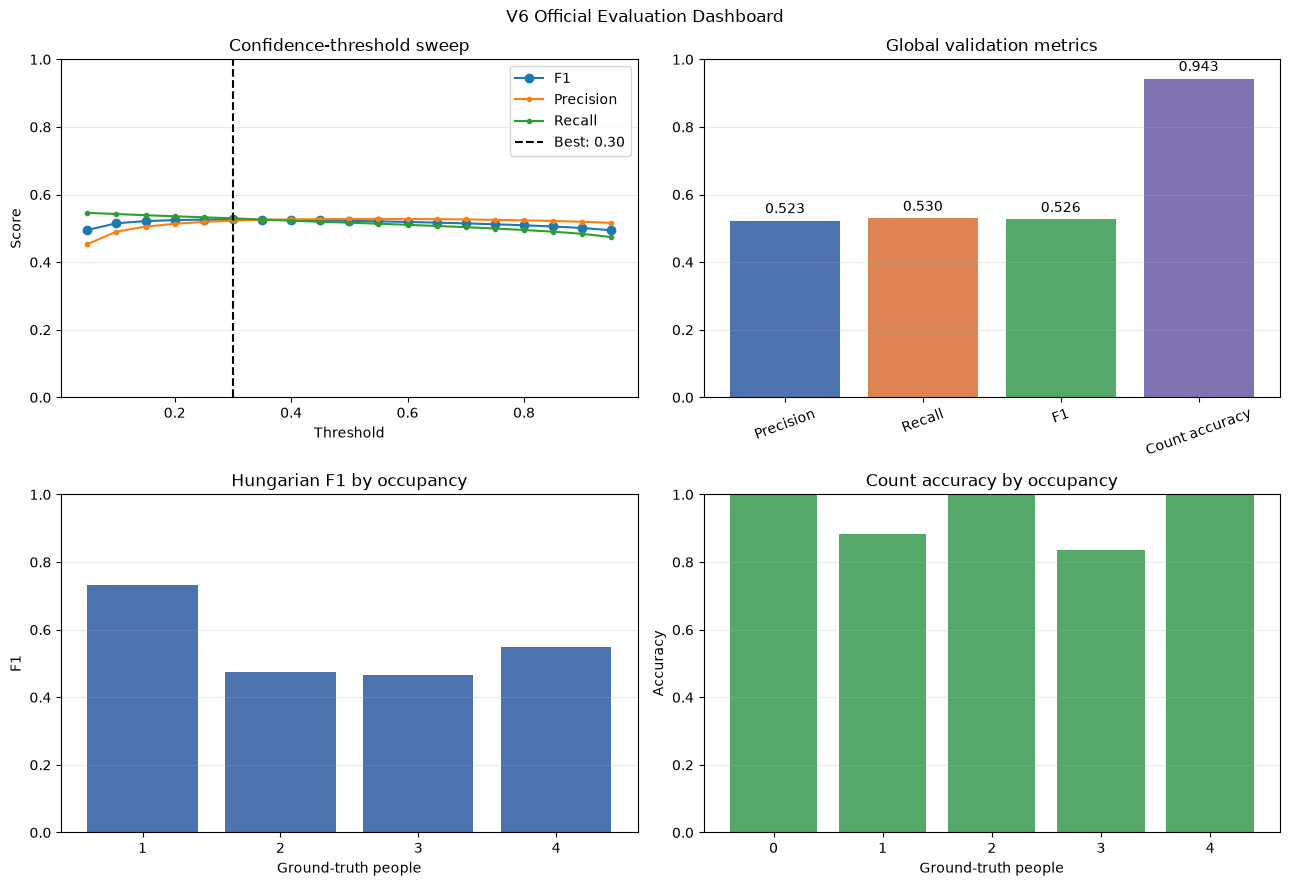

In [50]:
v6_occupancy_results = {}
for people in range(5):
    frame_mask = v6_validation_targets[..., 0].sum(axis=1).astype(int) == people
    result = evaluate_hungarian(
        v6_validation_targets[frame_mask],
        v6_validation_predictions[frame_mask],
        v6_best_result['threshold'],
    )
    v6_occupancy_results[people] = result
    print(
        f'{people} people | F1={result["f1"]:.4f} | '
        f'P={result["precision"]:.4f} | R={result["recall"]:.4f} | '
        f'count acc={result["count_accuracy"]:.4f}'
    )
plot_evaluation_dashboard(
    'V6', v6_threshold_results, v6_best_result, v6_occupancy_results
)

### 10.9 Save V6 artifacts

In [51]:
v6_experiment = {
    'version': 'V6', 'parent': 'V2 and V5',
    'hypothesis': 'Magnitude and signed I/Q provide complementary occupancy-dependent localisation cues.',
    'preprocessing_artifact': V6_STATS_PATH.name,
    'input_shape': list(V6_INPUT_SHAPE),
    'parameters': int(V6_PARAMETERS),
    'estimated_int8_weight_kib': float(V6_ESTIMATED_INT8_WEIGHT_KIB),
    'estimated_int8_input_kib': float(V6_INT8_INPUT_KIB),
    'best_confidence_threshold': v6_best_result['threshold'],
    'validation_metrics': v6_best_result,
    'reference_v2_f1': 0.49739833162853647,
    'reference_v5_f1': 0.49757574986319847,
}
with (ARTIFACT_DIR / 'baseline_v6_experiment.json').open('w', encoding='utf-8') as handle:
    json.dump(v6_experiment, handle, indent=2)
v6_best_model.save(MODEL_DIR / 'baseline_v6_final.keras')
print('Saved V6 model and experiment metadata.')

Saved V6 model and experiment metadata.


### 10.10 V6 result and decision for V7

V6 improves global Hungarian F1 to **0.5263**, an absolute gain of 0.0287 over V5. Precision and recall are balanced at 0.5229 and 0.5297, while count accuracy rises substantially to **0.9432**. The fused representation is particularly strong in empty and four-person scenes, with count accuracies of 0.9996 and 0.9999 and a four-person F1 of 0.5473. This confirms that magnitude and signed I/Q contain complementary information.

The gain is not uniform: one-person F1 is 0.7336, two-person F1 is 0.4753, and matched MAE/P90 are 0.597/0.918 m, both worse than V2. Training accuracy also reaches approximately 0.95 while validation metrics fluctuate sharply across epochs. Because the current validation set contains only one acquisition window per occupancy level, the measured F1 may be sensitive to which recording is held out. V7 therefore repeats the exact V6 model and preprocessing family on a second, predeclared group-stratified split. It does not overwrite or tune against the original split. Raw V6 and V7 scores will not be treated as a direct architecture contest because their validation frames differ; V7 is a robustness check.

## 11. Experiment 7 - Alternative acquisition-level split (V7)

V7 is a split-sensitivity experiment, not a new architecture. It repeats the exact V6 fused representation, model, loss, optimiser, and evaluator on a second predeclared validation fold. The original split and every V1-V6 artifact remain unchanged.

### 11.1 Load the V7 split and leakage-free preprocessing contract

In [52]:
V7_SPLIT_PATH = ARTIFACT_DIR / 'data_split_v7.json'
V7_STATS_PATH = ARTIFACT_DIR / 'v7_fused_normalization.json'
for required_path in (V7_SPLIT_PATH, V7_STATS_PATH):
    if not required_path.exists():
        raise FileNotFoundError(
            'Run src/03d_v7_alternative_split_and_preprocessing.ipynb first.'
        )
with V7_SPLIT_PATH.open(encoding='utf-8') as handle:
    v7_split = json.load(handle)
with V7_STATS_PATH.open(encoding='utf-8') as handle:
    v7_stats = json.load(handle)
V7_TRAIN_WINDOWS = v7_split['train_windows']
V7_VALIDATION_WINDOWS = v7_split['validation_windows']
v7_config_values = v7_stats['config'].copy()
v7_config_values['radar_indices'] = tuple(v7_config_values['radar_indices'])
V7_CONFIG = PreprocessingConfig(**v7_config_values)
V7_MEAN = np.asarray(v7_stats['mean'], dtype=np.float32)
V7_STD = np.asarray(v7_stats['std'], dtype=np.float32)
assert V7_VALIDATION_WINDOWS == [22, 16, 2, 15, 7]
assert set(V7_VALIDATION_WINDOWS).isdisjoint(VALIDATION_WINDOWS)
assert v7_stats['statistics_source_windows'] == V7_TRAIN_WINDOWS
print('V7 training windows:', V7_TRAIN_WINDOWS)
print('V7 validation windows:', V7_VALIDATION_WINDOWS)

V7 training windows: [0, 1, 3, 4, 5, 6, 8, 9, 10, 11, 12, 13, 14, 17, 18, 19, 20, 21, 23]
V7 validation windows: [22, 16, 2, 15, 7]


### 11.2 V7 streaming dataset

In [53]:
V7_INPUT_SHAPE = (6, 9, 120)

def v7_window_chunk_generator(indices, shuffle):
    ordered_indices = list(indices)
    if shuffle:
        np.random.shuffle(ordered_indices)
    for window_index in ordered_indices:
        with np.load(window_paths[window_index], allow_pickle=False) as data:
            radar, people_xy, people_mask = (
                data['radar_cir_iq'], data['people_xy'], data['people_mask']
            )
            starts = list(range(0, len(radar), CHUNK_SIZE))
            if shuffle:
                np.random.shuffle(starts)
            for start in starts:
                stop = min(start + CHUNK_SIZE, len(radar))
                features = transform_fused_magnitude_iq(radar[start:stop], V7_CONFIG)
                features = normalize_per_radar_channel(
                    features, V7_MEAN, V7_STD, V7_CONFIG.epsilon
                )
                yield features, build_sorted_targets(
                    people_xy[start:stop], people_mask[start:stop]
                )

v7_output_signature = (
    tf.TensorSpec(shape=(None,) + V7_INPUT_SHAPE, dtype=tf.float32),
    tf.TensorSpec(shape=(None, 4, 3), dtype=tf.float32),
)
def make_v7_dataset(indices, training, repeat=False):
    dataset = tf.data.Dataset.from_generator(
        lambda: v7_window_chunk_generator(indices, shuffle=training),
        output_signature=v7_output_signature,
    ).unbatch()
    if training:
        dataset = dataset.shuffle(8192, seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.batch(BATCH_SIZE)
    if repeat:
        dataset = dataset.repeat()
    return dataset.prefetch(tf.data.AUTOTUNE)

v7_train_dataset = make_v7_dataset(V7_TRAIN_WINDOWS, True, True)
v7_validation_fit_dataset = make_v7_dataset(V7_VALIDATION_WINDOWS, False, True)
v7_validation_dataset = make_v7_dataset(V7_VALIDATION_WINDOWS, False)
v7_sample_features, _ = next(iter(v7_train_dataset))
print('V7 feature batch:', v7_sample_features.shape)
print('V7 feature range:', float(tf.reduce_min(v7_sample_features)), float(tf.reduce_max(v7_sample_features)))

V7 feature batch: (128, 6, 9, 120)
V7 feature range: -3.575105905532837 3.027111768722534


### 11.3 V7 model, technical constraints, loss, and optimisation

The architecture is identical to V6. It therefore retains 136,004 parameters, the same activation shapes, standard TFLite Micro operators, and the same estimated edge footprint. Only the acquisition split and its train-only normalisation constants differ.

In [54]:
v7_model = build_baseline_model(
    input_shape=V7_INPUT_SHAPE, filters=V6_FILTERS,
    dense_units=V6_DENSE_UNITS, dropout_rate=V6_DROPOUT_RATE,
    preserve_spatial_layout=True,
)
V7_PARAMETERS = v7_model.count_params()
print(f'V7 parameters: {V7_PARAMETERS:,}')
print(f'Estimated INT8 weights: {V7_PARAMETERS / 1024:.1f} KiB')
print(f'INT8 input tensor: {np.prod(V7_INPUT_SHAPE) / 1024:.1f} KiB')
assert V7_PARAMETERS == V6_PARAMETERS
assert V7_PARAMETERS / 1024 < 800
assert np.prod(V7_INPUT_SHAPE) / 1024 < 300
v7_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=V6_LEARNING_RATE),
    loss=PermutationInvariantMultiPersonLoss(
        localization_weight=V6_LOCALIZATION_WEIGHT,
        confidence_weight=1.0, count_weight=0.0, delta=0.1,
    ),
    metrics=[person_count_accuracy],
)
v7_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        MODEL_DIR / 'baseline_v7_best.keras', monitor='val_loss',
        save_best_only=True, verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True, verbose=1,
    ),
]

V7 parameters: 136,004
Estimated INT8 weights: 132.8 KiB
INT8 input tensor: 6.3 KiB


### 11.4 Train V7 and plot convergence

V7 training skipped; using the recorded convergence history.


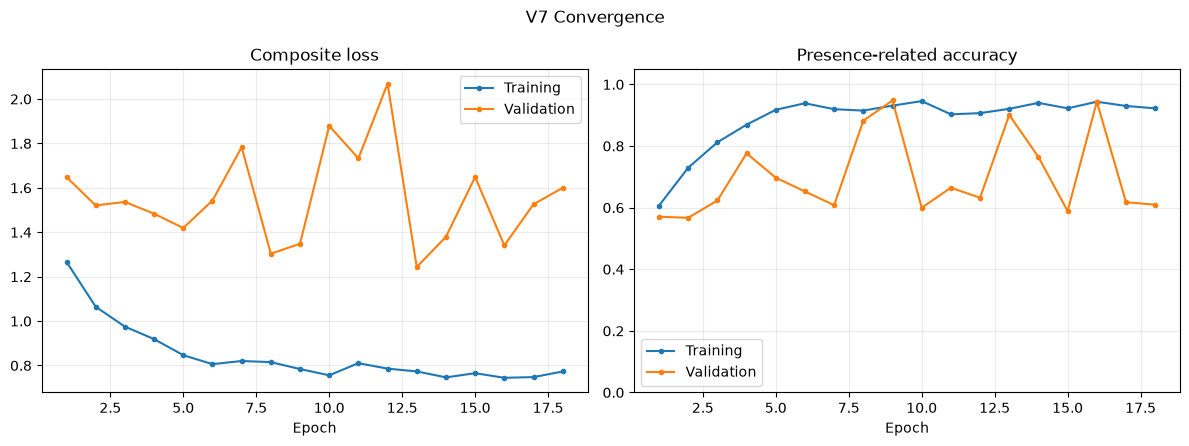

In [55]:
V7_EPOCHS = 25
if TRAIN_V7:
    v7_history = v7_model.fit(
        v7_train_dataset, validation_data=v7_validation_fit_dataset,
        steps_per_epoch=int(np.ceil(len(V7_TRAIN_WINDOWS) * 7500 / BATCH_SIZE)),
        validation_steps=int(np.ceil(len(V7_VALIDATION_WINDOWS) * 7500 / BATCH_SIZE)),
        epochs=V7_EPOCHS, callbacks=v7_callbacks, verbose=1,
    )
    v7_history_record = v7_history.history
else:
    v7_history_record = {
        'loss': [1.2668, 1.0645, 0.9750, 0.9188, 0.8464, 0.8061, 0.8202, 0.8152, 0.7840, 0.7558, 0.8104, 0.7859, 0.7733, 0.7465, 0.7653, 0.7446, 0.7477, 0.7730],
        'val_loss': [1.6484, 1.5208, 1.5366, 1.4836, 1.4193, 1.5428, 1.7830, 1.3036, 1.3481, 1.8789, 1.7328, 2.0690, 1.2436, 1.3795, 1.6489, 1.3407, 1.5260, 1.6001],
        'person_count_accuracy': [0.6065, 0.7297, 0.8121, 0.8693, 0.9176, 0.9388, 0.9195, 0.9150, 0.9311, 0.9458, 0.9029, 0.9067, 0.9208, 0.9401, 0.9223, 0.9438, 0.9300, 0.9223],
        'val_person_count_accuracy': [0.5706, 0.5670, 0.6232, 0.7763, 0.6971, 0.6525, 0.6080, 0.8823, 0.9478, 0.5995, 0.6646, 0.6320, 0.9010, 0.7642, 0.5889, 0.9440, 0.6176, 0.6095],
    }
    print('V7 training skipped; using the recorded convergence history.')
plot_convergence_dashboard(
    v7_history_record, 'person_count_accuracy',
    'val_person_count_accuracy', 'V7',
)

### 11.5 V7 official Hungarian evaluation and common occupancy dashboard

{
  "threshold": 0.9000000000000001,
  "tp": 30015,
  "fp": 41874,
  "fn": 44985,
  "precision": 0.4175186746233777,
  "recall": 0.4002,
  "f1": 0.4086759389743275,
  "matched_mae_m": 0.6161017417907715,
  "matched_p90_m": 0.93082594871521,
  "count_mae": 0.08893333333333334,
  "count_accuracy": 0.9112
}
0 people | F1=0.0000 | P=0.0000 | R=0.0000 | count acc=1.0000
1 people | F1=0.2050 | P=0.2326 | R=0.1832 | count acc=0.7583
2 people | F1=0.3822 | P=0.3835 | R=0.3809 | count acc=0.9867
3 people | F1=0.4691 | P=0.4691 | R=0.4691 | count acc=1.0000
4 people | F1=0.4224 | P=0.4329 | R=0.4124 | count acc=0.8111


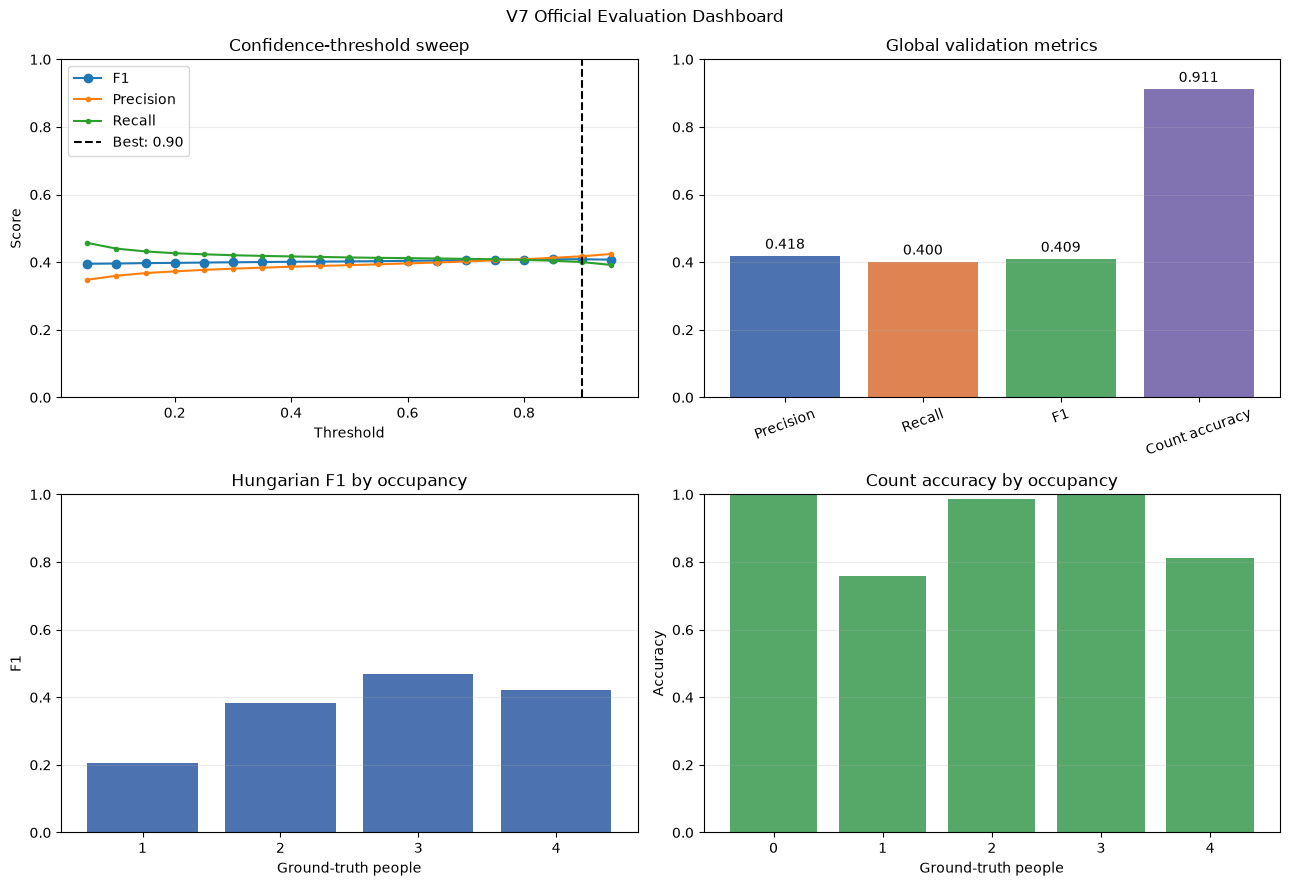

In [56]:
v7_best_model = tf.keras.models.load_model(MODEL_DIR / 'baseline_v7_best.keras')
v7_target_batches, v7_prediction_batches = [], []
for features, targets in v7_validation_dataset:
    v7_target_batches.append(targets.numpy())
    v7_prediction_batches.append(v7_best_model(features, training=False).numpy())
v7_validation_targets = np.concatenate(v7_target_batches)
v7_validation_predictions = np.concatenate(v7_prediction_batches)
v7_threshold_results = [
    evaluate_hungarian(v7_validation_targets, v7_validation_predictions, threshold)
    for threshold in np.arange(0.05, 0.96, 0.05)
]
v7_best_result = max(v7_threshold_results, key=lambda result: result['f1'])
print(json.dumps(v7_best_result, indent=2))
v7_occupancy_results = {}
for people in range(5):
    frame_mask = v7_validation_targets[..., 0].sum(axis=1).astype(int) == people
    result = evaluate_hungarian(
        v7_validation_targets[frame_mask], v7_validation_predictions[frame_mask],
        v7_best_result['threshold'],
    )
    v7_occupancy_results[people] = result
    print(
        f'{people} people | F1={result["f1"]:.4f} | '
        f'P={result["precision"]:.4f} | R={result["recall"]:.4f} | '
        f'count acc={result["count_accuracy"]:.4f}'
    )
plot_evaluation_dashboard('V7', v7_threshold_results, v7_best_result, v7_occupancy_results)

### 11.6 Save V7 artifacts and interpretation rule

In [57]:
v7_experiment = {
    'version': 'V7', 'parent': 'V6',
    'hypothesis': 'The fused-model result is robust to a second predeclared acquisition-level split.',
    'split_artifact': V7_SPLIT_PATH.name,
    'preprocessing_artifact': V7_STATS_PATH.name,
    'train_windows': V7_TRAIN_WINDOWS,
    'validation_windows': V7_VALIDATION_WINDOWS,
    'parameters': int(V7_PARAMETERS),
    'best_confidence_threshold': v7_best_result['threshold'],
    'validation_metrics': v7_best_result,
    'primary_split_v6_f1': 0.526271865623696,
}
with (ARTIFACT_DIR / 'baseline_v7_experiment.json').open('w', encoding='utf-8') as handle:
    json.dump(v7_experiment, handle, indent=2)
v7_best_model.save(MODEL_DIR / 'baseline_v7_final.keras')
print('Saved V7 model and experiment metadata.')

Saved V7 model and experiment metadata.


### 11.7 V7 result and decision for V8

V7 confirms substantial acquisition-session sensitivity. On the alternative fold, global F1 falls to **0.4087**, precision to 0.4175, and recall to 0.4002. The optimal confidence threshold shifts from 0.30 in V6 to **0.90**, while matched MAE/P90 worsen to 0.616/0.931 m. Count accuracy remains high at 0.9112, showing that occupancy detection generalises better than coordinate and confidence calibration. The largest failure is the unseen one-person window, whose F1 is only 0.2050.

The training count accuracy exceeds 0.94 while validation loss remains high and volatile. This is consistent with overfitting to acquisition-specific amplitude, gain, and baseline characteristics. V8 therefore keeps the exact V7 split, preprocessing, model, loss, and evaluator, and changes only the training data through mild radar-aware gain, offset, and noise augmentation. This provides a fair V7-versus-V8 comparison on identical validation frames and adds no inference operator, parameter, activation, or preprocessing cost.

## 12. Experiment 8 - Radar-aware training augmentation (V8)

V8 addresses the session sensitivity exposed by V7. The alternative split, fused preprocessing contract, model architecture, loss, optimiser, and evaluator remain identical to V7. The only change is mild training-only augmentation that simulates radar gain, baseline, and measurement-noise variation.

### 12.1 V8 augmentation hypothesis and dataset

V7 retains high count accuracy but suffers poor coordinate/confidence generalisation and an optimal threshold of 0.90. Random per-radar gain and per-channel offset perturbations target acquisition calibration differences; low-amplitude independent noise discourages memorisation of session-specific CIR details. Labels and validation data are never augmented.

In [58]:
V8_GAIN_MIN = 0.90
V8_GAIN_MAX = 1.10
V8_OFFSET_STD = 0.05
V8_NOISE_STD = 0.02

def augment_v8_batch(features, targets):
    batch_size = tf.shape(features)[0]
    radar_gain = tf.random.uniform(
        (batch_size, 6, 1, 1), V8_GAIN_MIN, V8_GAIN_MAX,
        dtype=features.dtype, seed=SEED + 8,
    )
    channel_offset = tf.random.normal(
        (batch_size, 6, 9, 1), stddev=V8_OFFSET_STD,
        dtype=features.dtype, seed=SEED + 9,
    )
    measurement_noise = tf.random.normal(
        tf.shape(features), stddev=V8_NOISE_STD,
        dtype=features.dtype, seed=SEED + 10,
    )
    augmented = features * radar_gain + channel_offset + measurement_noise
    return augmented, targets

v8_train_dataset = make_v7_dataset(V7_TRAIN_WINDOWS, True, True).map(
    augment_v8_batch, num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)
v8_validation_fit_dataset = make_v7_dataset(V7_VALIDATION_WINDOWS, False, True)
v8_validation_dataset = make_v7_dataset(V7_VALIDATION_WINDOWS, False)

v8_clean_features, v8_clean_targets = next(iter(v7_train_dataset))
v8_augmented_features, _ = augment_v8_batch(v8_clean_features, v8_clean_targets)
print('Clean mean/std:', float(tf.reduce_mean(v8_clean_features)), float(tf.math.reduce_std(v8_clean_features)))
print('Augmented mean/std:', float(tf.reduce_mean(v8_augmented_features)), float(tf.math.reduce_std(v8_augmented_features)))
print('Mean absolute perturbation:', float(tf.reduce_mean(tf.abs(v8_augmented_features - v8_clean_features))))

Clean mean/std: -0.0034486709628254175 0.9959855675697327
Augmented mean/std: -0.0033450971823185682 0.9992353320121765
Mean absolute perturbation: 0.06239999085664749


### 12.2 V8 model, objective, and technical-cost check

Training augmentation is implemented in the input pipeline and is absent from validation and inference. V8 therefore has exactly the same 136,004 parameters, inference graph, input tensor, activation shapes, Flash estimate, and supported TFLite Micro operators as V6/V7.

In [59]:
v8_model = build_baseline_model(
    input_shape=V7_INPUT_SHAPE, filters=V6_FILTERS,
    dense_units=V6_DENSE_UNITS, dropout_rate=V6_DROPOUT_RATE,
    preserve_spatial_layout=True,
)
V8_PARAMETERS = v8_model.count_params()
assert V8_PARAMETERS == V7_PARAMETERS == 136004
print(f'V8 parameters: {V8_PARAMETERS:,}')
print(f'Estimated INT8 weights: {V8_PARAMETERS / 1024:.1f} KiB')
print(f'INT8 input tensor: {np.prod(V7_INPUT_SHAPE) / 1024:.1f} KiB')
print('Inference augmentation operators: none')

v8_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=V6_LEARNING_RATE),
    loss=PermutationInvariantMultiPersonLoss(
        localization_weight=V6_LOCALIZATION_WEIGHT,
        confidence_weight=1.0, count_weight=0.0, delta=0.1,
    ),
    metrics=[person_count_accuracy],
)
v8_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        MODEL_DIR / 'baseline_v8_best.keras', monitor='val_loss',
        save_best_only=True, verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True, verbose=1,
    ),
]

V8 parameters: 136,004
Estimated INT8 weights: 132.8 KiB
INT8 input tensor: 6.3 KiB
Inference augmentation operators: none


### 12.3 Train V8 and plot convergence

V8 training skipped; using the recorded convergence history.


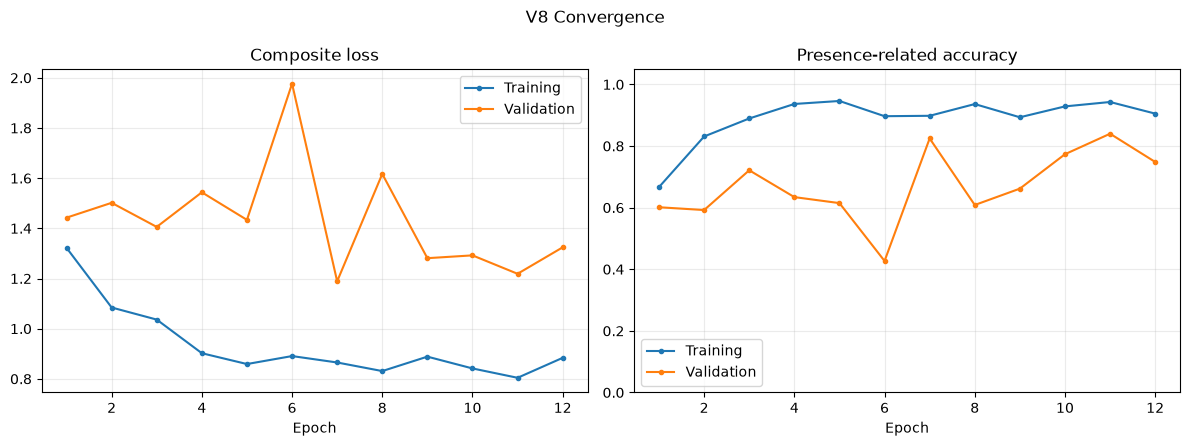

In [60]:
V8_EPOCHS = 25
if TRAIN_V8:
    v8_history = v8_model.fit(
        v8_train_dataset, validation_data=v8_validation_fit_dataset,
        steps_per_epoch=int(np.ceil(len(V7_TRAIN_WINDOWS) * 7500 / BATCH_SIZE)),
        validation_steps=int(np.ceil(len(V7_VALIDATION_WINDOWS) * 7500 / BATCH_SIZE)),
        epochs=V8_EPOCHS, callbacks=v8_callbacks, verbose=1,
    )
    v8_history_record = v8_history.history
else:
    v8_history_record = {
        'loss': [1.3224, 1.0845, 1.0363, 0.9023, 0.8591, 0.8909, 0.8653, 0.8311, 0.8886, 0.8416, 0.8043, 0.8839],
        'val_loss': [1.4426, 1.5018, 1.4057, 1.5437, 1.4338, 1.9766, 1.1890, 1.6169, 1.2811, 1.2923, 1.2189, 1.3244],
        'person_count_accuracy': [0.6668, 0.8310, 0.8894, 0.9365, 0.9462, 0.8968, 0.8981, 0.9362, 0.8933, 0.9286, 0.9429, 0.9052],
        'val_person_count_accuracy': [0.6013, 0.5922, 0.7213, 0.6342, 0.6147, 0.4269, 0.8246, 0.6086, 0.6617, 0.7734, 0.8399, 0.7483],
    }
    print('V8 training skipped; using the recorded convergence history.')
plot_convergence_dashboard(
    v8_history_record, 'person_count_accuracy',
    'val_person_count_accuracy', 'V8',
)

### 12.4 V8 official Hungarian evaluation and common occupancy dashboard

{
  "threshold": 0.45,
  "tp": 33751,
  "fp": 38177,
  "fn": 41249,
  "precision": 0.4692331220108998,
  "recall": 0.4500133333333333,
  "f1": 0.4594223020799303,
  "matched_mae_m": 0.5741457343101501,
  "matched_p90_m": 0.9031566381454468,
  "count_mae": 0.17434666666666668,
  "count_accuracy": 0.8262133333333334
}
0 people | F1=0.0000 | P=0.0000 | R=0.0000 | count acc=1.0000
1 people | F1=0.2130 | P=0.3849 | R=0.1472 | count acc=0.3391
2 people | F1=0.4239 | P=0.4239 | R=0.4239 | count acc=1.0000
3 people | F1=0.6199 | P=0.5998 | R=0.6414 | count acc=0.7920
4 people | F1=0.3952 | P=0.3952 | R=0.3952 | count acc=1.0000


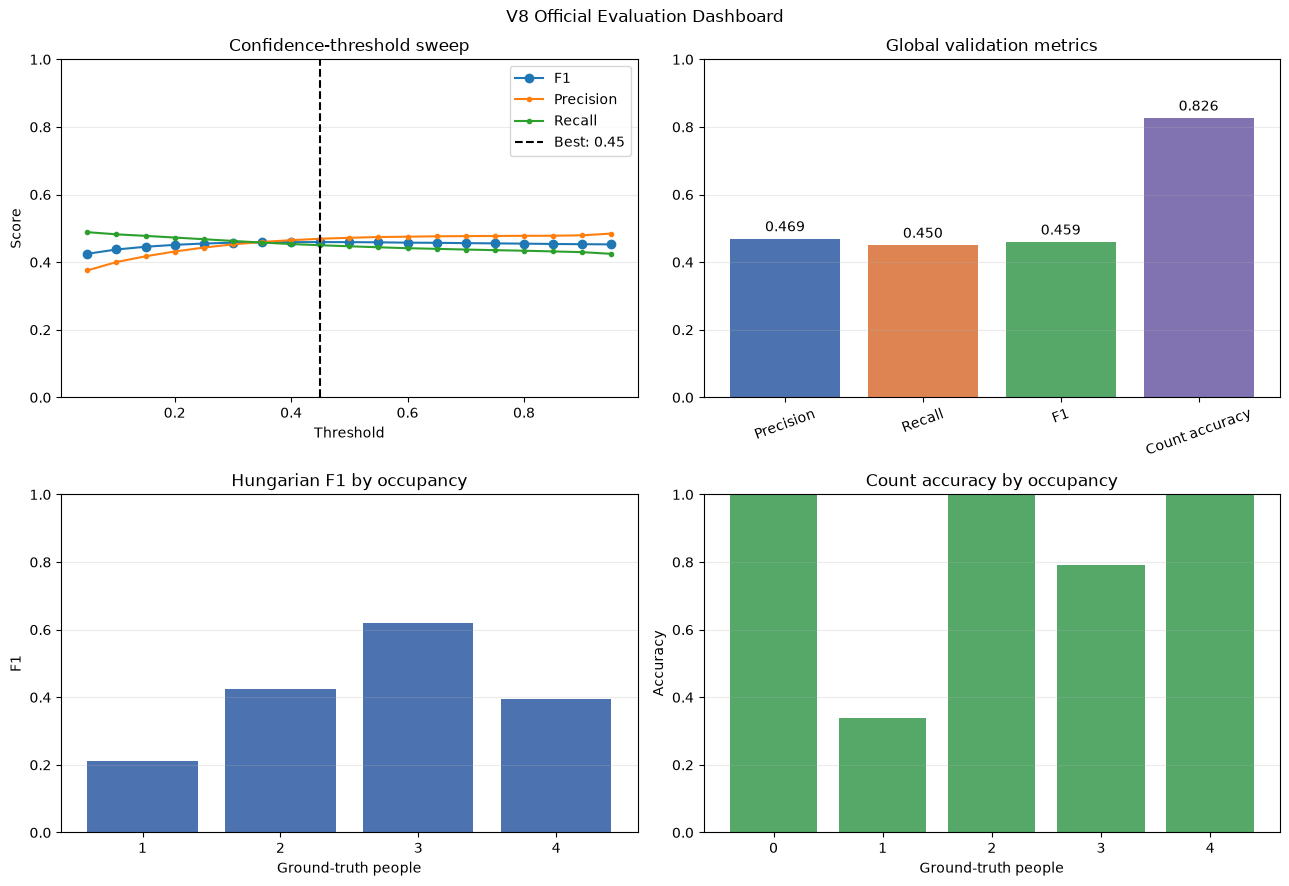

In [61]:
v8_best_model = tf.keras.models.load_model(MODEL_DIR / 'baseline_v8_best.keras')
v8_target_batches, v8_prediction_batches = [], []
for features, targets in v8_validation_dataset:
    v8_target_batches.append(targets.numpy())
    v8_prediction_batches.append(v8_best_model(features, training=False).numpy())
v8_validation_targets = np.concatenate(v8_target_batches)
v8_validation_predictions = np.concatenate(v8_prediction_batches)
v8_threshold_results = [
    evaluate_hungarian(v8_validation_targets, v8_validation_predictions, threshold)
    for threshold in np.arange(0.05, 0.96, 0.05)
]
v8_best_result = max(v8_threshold_results, key=lambda result: result['f1'])
print(json.dumps(v8_best_result, indent=2))

v8_occupancy_results = {}
for people in range(5):
    frame_mask = v8_validation_targets[..., 0].sum(axis=1).astype(int) == people
    result = evaluate_hungarian(
        v8_validation_targets[frame_mask], v8_validation_predictions[frame_mask],
        v8_best_result['threshold'],
    )
    v8_occupancy_results[people] = result
    print(
        f'{people} people | F1={result["f1"]:.4f} | '
        f'P={result["precision"]:.4f} | R={result["recall"]:.4f} | '
        f'count acc={result["count_accuracy"]:.4f}'
    )
plot_evaluation_dashboard('V8', v8_threshold_results, v8_best_result, v8_occupancy_results)

### 12.5 Direct V7-V8 comparison on identical validation frames

In [62]:
v7_v8_comparison = {
    'V7': v7_best_result,
    'V8': v8_best_result,
}
for version, result in v7_v8_comparison.items():
    print(
        f'{version} | threshold={result["threshold"]:.2f} | '
        f'F1={result["f1"]:.4f} | P={result["precision"]:.4f} | '
        f'R={result["recall"]:.4f} | MAE={result["matched_mae_m"]:.3f} m | '
        f'count acc={result["count_accuracy"]:.4f}'
    )
print('Absolute F1 change:', v8_best_result['f1'] - v7_best_result['f1'])

V7 | threshold=0.90 | F1=0.4087 | P=0.4175 | R=0.4002 | MAE=0.616 m | count acc=0.9112
V8 | threshold=0.45 | F1=0.4594 | P=0.4692 | R=0.4500 | MAE=0.574 m | count acc=0.8262
Absolute F1 change: 0.050746363105602765


### 12.6 Save V8 artifacts

In [63]:
v8_experiment = {
    'version': 'V8', 'parent': 'V7',
    'hypothesis': 'Mild radar-aware training augmentation reduces acquisition-session overfitting.',
    'split_artifact': V7_SPLIT_PATH.name,
    'preprocessing_artifact': V7_STATS_PATH.name,
    'augmentation': {
        'radar_gain_range': [V8_GAIN_MIN, V8_GAIN_MAX],
        'channel_offset_std': V8_OFFSET_STD,
        'measurement_noise_std': V8_NOISE_STD,
        'inference_cost': 'none',
    },
    'parameters': int(V8_PARAMETERS),
    'best_confidence_threshold': v8_best_result['threshold'],
    'validation_metrics': v8_best_result,
    'reference_v7_metrics': v7_best_result,
}
with (ARTIFACT_DIR / 'baseline_v8_experiment.json').open('w', encoding='utf-8') as handle:
    json.dump(v8_experiment, handle, indent=2)
v8_best_model.save(MODEL_DIR / 'baseline_v8_final.keras')
print('Saved V8 model and experiment metadata.')

Saved V8 model and experiment metadata.


### 12.7 V8 result and decision for V9

V8 supports the augmentation hypothesis. On the identical alternative split, global F1 improves from **0.4087 to 0.4594**, precision from 0.4175 to 0.4692, recall from 0.4002 to 0.4500, and matched MAE improves from 0.616 m to 0.574 m. The optimal threshold also falls from 0.90 to 0.45, indicating substantially less extreme confidence calibration.

However, the always-on gain/offset/noise augmentation reduces global count accuracy from 0.9112 to 0.8262. One-person count accuracy collapses from 0.7583 to 0.3391, and four-person F1 falls from 0.4224 to 0.3952. This suggests that per-channel offsets and continuous perturbation damage absolute energy cues used for occupancy. V9 therefore retains the successful cross-session regularisation idea but removes channel offsets, halves the gain/noise intensity, and augments only 50% of samples. The split, preprocessing, model, loss, and evaluator remain identical, making V8-V9 a controlled comparison.

## 13. Experiment 9 - Intermittent energy-preserving augmentation (V9)

V9 refines the successful V8 regularisation strategy while addressing its loss of occupancy accuracy. It uses the same alternative split, fused preprocessing, architecture, loss, optimiser, and official evaluator. Only the training augmentation policy changes.

### 13.1 V9 augmentation hypothesis and dataset

V8 improved F1, matched error, and confidence calibration, but its always-on per-channel offsets substantially damaged one-person counting. V9 removes offsets, narrows radar gain variation, halves measurement noise, and applies augmentation independently to approximately 50% of training samples. This retains unmodified examples and better preserves absolute energy cues.

In [64]:
V9_AUGMENT_PROBABILITY = 0.50
V9_GAIN_MIN = 0.95
V9_GAIN_MAX = 1.05
V9_NOISE_STD = 0.01

def augment_v9_batch(features, targets):
    batch_size = tf.shape(features)[0]
    apply_augmentation = tf.random.uniform(
        (batch_size, 1, 1, 1), 0.0, 1.0,
        dtype=features.dtype, seed=SEED + 90,
    ) < V9_AUGMENT_PROBABILITY
    radar_gain = tf.random.uniform(
        (batch_size, 6, 1, 1), V9_GAIN_MIN, V9_GAIN_MAX,
        dtype=features.dtype, seed=SEED + 91,
    )
    measurement_noise = tf.random.normal(
        tf.shape(features), stddev=V9_NOISE_STD,
        dtype=features.dtype, seed=SEED + 92,
    )
    perturbed = features * radar_gain + measurement_noise
    augmented = tf.where(apply_augmentation, perturbed, features)
    return augmented, targets

v9_train_dataset = make_v7_dataset(V7_TRAIN_WINDOWS, True, True).map(
    augment_v9_batch, num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)
v9_validation_fit_dataset = make_v7_dataset(V7_VALIDATION_WINDOWS, False, True)
v9_validation_dataset = make_v7_dataset(V7_VALIDATION_WINDOWS, False)

v9_clean_features, v9_clean_targets = next(iter(v7_train_dataset))
v9_augmented_features, _ = augment_v9_batch(v9_clean_features, v9_clean_targets)
sample_perturbation = tf.reduce_mean(
    tf.abs(v9_augmented_features - v9_clean_features), axis=(1, 2, 3)
)
print('Clean mean/std:', float(tf.reduce_mean(v9_clean_features)), float(tf.math.reduce_std(v9_clean_features)))
print('Augmented mean/std:', float(tf.reduce_mean(v9_augmented_features)), float(tf.math.reduce_std(v9_augmented_features)))
print('Mean absolute perturbation:', float(tf.reduce_mean(sample_perturbation)))
print('Observed augmented-sample fraction:', float(tf.reduce_mean(tf.cast(sample_perturbation > 0, tf.float32))))

Clean mean/std: -0.0018318057991564274 0.9945223927497864
Augmented mean/std: -0.0018403242575004697 0.9960662126541138
Mean absolute perturbation: 0.014489478431642056
Observed augmented-sample fraction: 0.578125


### 13.2 V9 model, objective, and technical-cost check

The augmentation remains outside the inference graph. V9 is therefore exactly the same deployable network as V6-V8: 136,004 parameters, identical activations and input size, no recurrent/custom/Flex operators, and no augmentation latency or memory on the ESP32-S3.

In [65]:
v9_model = build_baseline_model(
    input_shape=V7_INPUT_SHAPE, filters=V6_FILTERS,
    dense_units=V6_DENSE_UNITS, dropout_rate=V6_DROPOUT_RATE,
    preserve_spatial_layout=True,
)
V9_PARAMETERS = v9_model.count_params()
assert V9_PARAMETERS == V8_PARAMETERS == 136004
print(f'V9 parameters: {V9_PARAMETERS:,}')
print(f'Estimated INT8 weights: {V9_PARAMETERS / 1024:.1f} KiB')
print(f'INT8 input tensor: {np.prod(V7_INPUT_SHAPE) / 1024:.1f} KiB')
print('Inference augmentation operators: none')
assert V9_PARAMETERS / 1024 < 800
assert np.prod(V7_INPUT_SHAPE) / 1024 < 300

v9_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=V6_LEARNING_RATE),
    loss=PermutationInvariantMultiPersonLoss(
        localization_weight=V6_LOCALIZATION_WEIGHT,
        confidence_weight=1.0, count_weight=0.0, delta=0.1,
    ),
    metrics=[person_count_accuracy],
)
v9_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        MODEL_DIR / 'baseline_v9_best.keras', monitor='val_loss',
        save_best_only=True, verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True, verbose=1,
    ),
]

V9 parameters: 136,004
Estimated INT8 weights: 132.8 KiB
INT8 input tensor: 6.3 KiB
Inference augmentation operators: none


### 13.3 Train V9 and plot convergence

V9 training skipped; using the recorded convergence history.


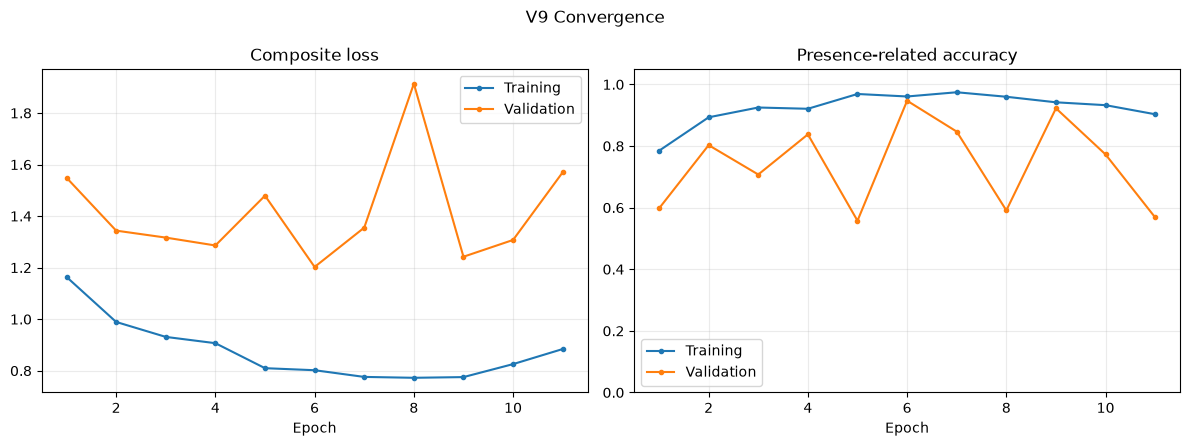

In [66]:
V9_EPOCHS = 25
if TRAIN_V9:
    v9_history = v9_model.fit(
        v9_train_dataset, validation_data=v9_validation_fit_dataset,
        steps_per_epoch=int(np.ceil(len(V7_TRAIN_WINDOWS) * 7500 / BATCH_SIZE)),
        validation_steps=int(np.ceil(len(V7_VALIDATION_WINDOWS) * 7500 / BATCH_SIZE)),
        epochs=V9_EPOCHS, callbacks=v9_callbacks, verbose=1,
    )
    v9_history_record = v9_history.history
else:
    v9_history_record = {
        'loss': [1.1639, 0.9892, 0.9312, 0.9068, 0.8098, 0.8019, 0.7759, 0.7725, 0.7752, 0.8256, 0.8841],
        'val_loss': [1.5489, 1.3436, 1.3166, 1.2860, 1.4793, 1.2026, 1.3552, 1.9138, 1.2423, 1.3074, 1.5700],
        'person_count_accuracy': [0.7846, 0.8932, 0.9250, 0.9209, 0.9689, 0.9608, 0.9745, 0.9599, 0.9419, 0.9326, 0.9031],
        'val_person_count_accuracy': [0.5974, 0.8029, 0.7075, 0.8378, 0.5575, 0.9470, 0.8468, 0.5910, 0.9225, 0.7726, 0.5681],
    }
    print('V9 training skipped; using the recorded convergence history.')
plot_convergence_dashboard(
    v9_history_record, 'person_count_accuracy',
    'val_person_count_accuracy', 'V9',
)

### 13.4 V9 official Hungarian evaluation and common occupancy dashboard

{
  "threshold": 0.6500000000000001,
  "tp": 33503,
  "fp": 41440,
  "fn": 41497,
  "precision": 0.4470464219473467,
  "recall": 0.44670666666666664,
  "f1": 0.44687647972896366,
  "matched_mae_m": 0.5667808651924133,
  "matched_p90_m": 0.913658857345581,
  "count_mae": 0.03133333333333333,
  "count_accuracy": 0.97184
}
0 people | F1=0.0000 | P=0.0000 | R=0.0000 | count acc=0.9996
1 people | F1=0.2605 | P=0.2531 | R=0.2684 | count acc=0.9176
2 people | F1=0.2697 | P=0.2697 | R=0.2697 | count acc=1.0000
3 people | F1=0.6438 | P=0.6437 | R=0.6438 | count acc=0.9956
4 people | F1=0.4357 | P=0.4395 | R=0.4319 | count acc=0.9464


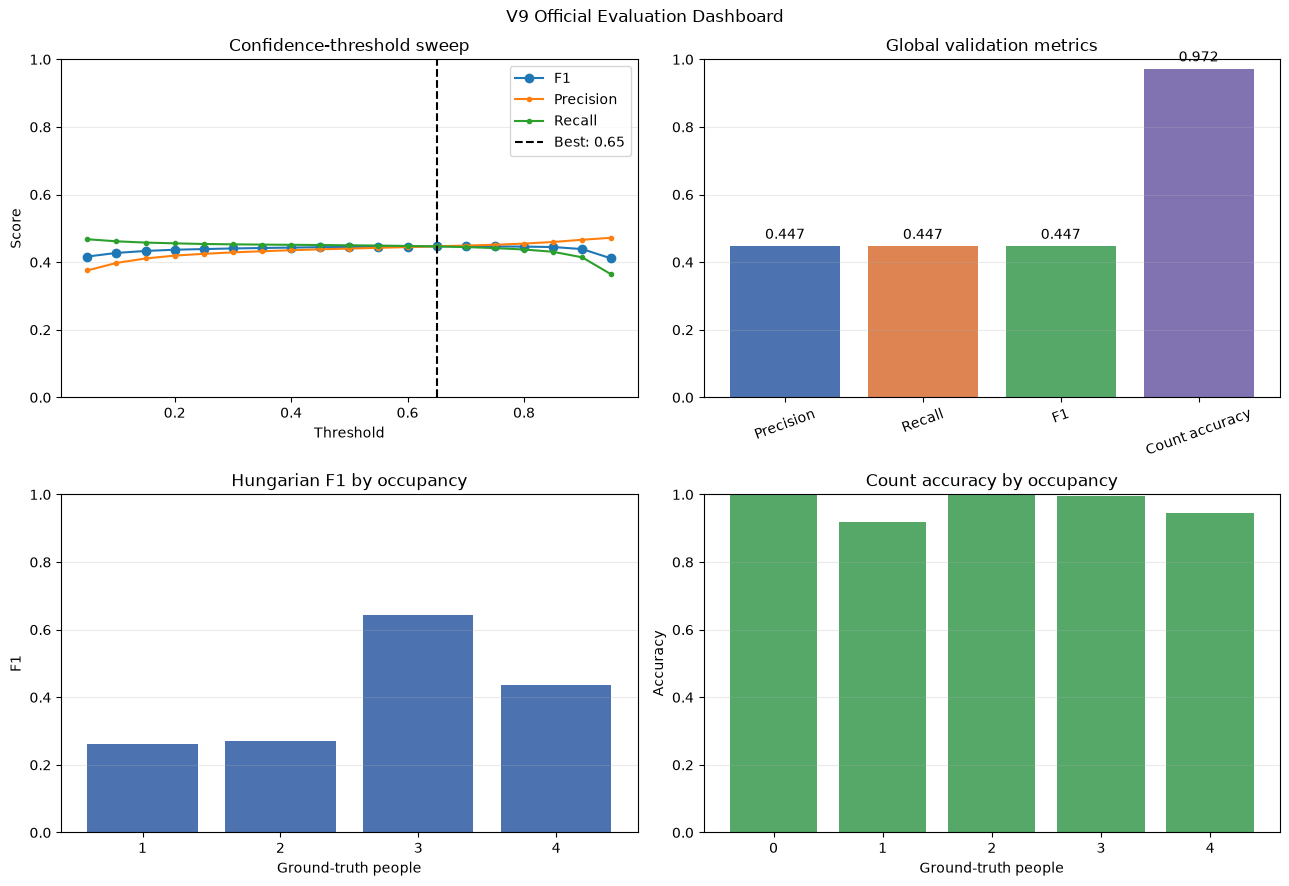

In [67]:
v9_best_model = tf.keras.models.load_model(MODEL_DIR / 'baseline_v9_best.keras')
v9_target_batches, v9_prediction_batches = [], []
for features, targets in v9_validation_dataset:
    v9_target_batches.append(targets.numpy())
    v9_prediction_batches.append(v9_best_model(features, training=False).numpy())
v9_validation_targets = np.concatenate(v9_target_batches)
v9_validation_predictions = np.concatenate(v9_prediction_batches)
v9_threshold_results = [
    evaluate_hungarian(v9_validation_targets, v9_validation_predictions, threshold)
    for threshold in np.arange(0.05, 0.96, 0.05)
]
v9_best_result = max(v9_threshold_results, key=lambda result: result['f1'])
print(json.dumps(v9_best_result, indent=2))

v9_occupancy_results = {}
for people in range(5):
    frame_mask = v9_validation_targets[..., 0].sum(axis=1).astype(int) == people
    result = evaluate_hungarian(
        v9_validation_targets[frame_mask], v9_validation_predictions[frame_mask],
        v9_best_result['threshold'],
    )
    v9_occupancy_results[people] = result
    print(
        f'{people} people | F1={result["f1"]:.4f} | '
        f'P={result["precision"]:.4f} | R={result["recall"]:.4f} | '
        f'count acc={result["count_accuracy"]:.4f}'
    )
plot_evaluation_dashboard('V9', v9_threshold_results, v9_best_result, v9_occupancy_results)

### 13.5 Direct V7-V8-V9 comparison on identical validation frames

In [68]:
v7_v8_v9_comparison = {
    'V7 - no augmentation': v7_best_result,
    'V8 - always-on gain/offset/noise': v8_best_result,
    'V9 - intermittent gain/noise': v9_best_result,
}
for version, result in v7_v8_v9_comparison.items():
    print(
        f'{version} | threshold={result["threshold"]:.2f} | '
        f'F1={result["f1"]:.4f} | P={result["precision"]:.4f} | '
        f'R={result["recall"]:.4f} | MAE={result["matched_mae_m"]:.3f} m | '
        f'count acc={result["count_accuracy"]:.4f}'
    )
print('V9 minus V8 F1:', v9_best_result['f1'] - v8_best_result['f1'])
print('V9 minus V8 count accuracy:', v9_best_result['count_accuracy'] - v8_best_result['count_accuracy'])

V7 - no augmentation | threshold=0.90 | F1=0.4087 | P=0.4175 | R=0.4002 | MAE=0.616 m | count acc=0.9112
V8 - always-on gain/offset/noise | threshold=0.45 | F1=0.4594 | P=0.4692 | R=0.4500 | MAE=0.574 m | count acc=0.8262
V9 - intermittent gain/noise | threshold=0.65 | F1=0.4469 | P=0.4470 | R=0.4467 | MAE=0.567 m | count acc=0.9718
V9 minus V8 F1: -0.012545822350966629
V9 minus V8 count accuracy: 0.14562666666666668


### 13.6 Save V9 artifacts

In [69]:
v9_experiment = {
    'version': 'V9', 'parent': 'V8',
    'hypothesis': 'Intermittent energy-preserving augmentation retains cross-session F1 gains while recovering occupancy information.',
    'split_artifact': V7_SPLIT_PATH.name,
    'preprocessing_artifact': V7_STATS_PATH.name,
    'augmentation': {
        'application_probability': V9_AUGMENT_PROBABILITY,
        'radar_gain_range': [V9_GAIN_MIN, V9_GAIN_MAX],
        'channel_offset_std': 0.0,
        'measurement_noise_std': V9_NOISE_STD,
        'inference_cost': 'none',
    },
    'parameters': int(V9_PARAMETERS),
    'best_confidence_threshold': v9_best_result['threshold'],
    'validation_metrics': v9_best_result,
    'reference_v7_metrics': v7_best_result,
    'reference_v8_metrics': v8_best_result,
}
with (ARTIFACT_DIR / 'baseline_v9_experiment.json').open('w', encoding='utf-8') as handle:
    json.dump(v9_experiment, handle, indent=2)
v9_best_model.save(MODEL_DIR / 'baseline_v9_final.keras')
print('Saved V9 model and experiment metadata.')

Saved V9 model and experiment metadata.


### 13.7 V9 result and decision for V10

V9 confirms the expected trade-off. Count accuracy rises from 0.8262 in V8 to **0.9718**, one-person count accuracy recovers from 0.3391 to 0.9176, and matched MAE improves slightly to **0.567 m**. However, global F1 falls from 0.4594 to **0.4469**, mainly because two-person F1 drops to 0.2697. V8 therefore remains the stronger localisation candidate on the alternative fold, while V9 is the best counting configuration.

Further augmentation tuning is not justified by these results. V10 instead targets missing geometric and temporal information: explicit sine/cosine inter-antenna phase differences, a stateful causal EMA residual retained alongside original magnitude, and current-plus-previous signal frames. Although V6-V9 already preserve signed I/Q, they do not explicitly expose phase differences. V10 keeps the difficult V7-V9 split to test whether these features improve geometry under session shift. Previous predicted coordinates are not fed back because ground-truth priors in training would create teacher-forcing leakage and predicted priors in inference would propagate errors.

## 14. Experiment 10 - Explicit phase, stateful EMA, and causal temporal context (V10)

V10 tests an integrated geometry-and-temporal representation on the same difficult split used by V7-V9. It adds explicit inter-antenna phase differences, retains original magnitude together with a stateful EMA residual, and concatenates the immediately previous signal frame. No training augmentation is used, so V7 is the direct no-augmentation reference.

### 14.1 Load the V10 preprocessing contract

The contract is produced by 03e_preprocessing_phase_ema_temporal.ipynb. EMA and previous-frame states reset once per acquisition window and remain continuous across storage chunks.

In [70]:
V10_STATS_PATH = ARTIFACT_DIR / 'v10_phase_ema_temporal_normalization.json'
if not V10_STATS_PATH.exists():
    raise FileNotFoundError(
        'Missing V10 artifact. Run src/03e_preprocessing_phase_ema_temporal.ipynb first.'
    )
with V10_STATS_PATH.open(encoding='utf-8') as handle:
    v10_stats = json.load(handle)
v10_config_values = v10_stats['config'].copy()
v10_config_values['radar_indices'] = tuple(v10_config_values['radar_indices'])
V10_CONFIG = PreprocessingConfig(**v10_config_values)
V10_MEAN = np.asarray(v10_stats['mean'], dtype=np.float32)
V10_STD = np.asarray(v10_stats['std'], dtype=np.float32)
V10_TRAIN_WINDOWS = v10_stats['training_windows']
V10_VALIDATION_WINDOWS = v10_stats['validation_windows']
assert v10_stats['representation'] == 'phase_ema_previous_frame'
assert V10_CONFIG.background_mode == 'ema'
assert V10_MEAN.shape == V10_STD.shape == (6, 36)
assert V10_TRAIN_WINDOWS == V7_TRAIN_WINDOWS
assert V10_VALIDATION_WINDOWS == V7_VALIDATION_WINDOWS
print('Loaded:', V10_STATS_PATH.resolve())
print('EMA alpha:', V10_CONFIG.ema_alpha)
print('V10 validation windows:', V10_VALIDATION_WINDOWS)

Loaded: C:\Users\213053\OneDrive\Documenti\EEAI\src\artifacts\v10_phase_ema_temporal_normalization.json
EMA alpha: 0.98
V10 validation windows: [22, 16, 2, 15, 7]


### 14.2 V10 causal streaming dataset

Chunks are always transformed in chronological order because EMA and previous-frame features are stateful. Training windows and the resulting individual frames are still shuffled after preprocessing. This preserves causal correctness without sacrificing stochastic training.

In [71]:
V10_INPUT_SHAPE = (6, 36, 120)

def v10_window_chunk_generator(indices, shuffle):
    ordered_indices = list(indices)
    if shuffle:
        np.random.shuffle(ordered_indices)
    for window_index in ordered_indices:
        ema_state, previous_state = None, None
        with np.load(window_paths[window_index], allow_pickle=False) as data:
            radar = data['radar_cir_iq']
            people_xy = data['people_xy']
            people_mask = data['people_mask']
            for start in range(0, len(radar), CHUNK_SIZE):
                stop = min(start + CHUNK_SIZE, len(radar))
                features, ema_state, previous_state = transform_phase_ema_temporal(
                    radar[start:stop], V10_CONFIG, ema_state, previous_state
                )
                features = normalize_per_radar_channel(
                    features, V10_MEAN, V10_STD, V10_CONFIG.epsilon
                )
                targets = build_sorted_targets(
                    people_xy[start:stop], people_mask[start:stop]
                )
                yield features, targets

v10_output_signature = (
    tf.TensorSpec(shape=(None,) + V10_INPUT_SHAPE, dtype=tf.float32),
    tf.TensorSpec(shape=(None, 4, 3), dtype=tf.float32),
)
def make_v10_dataset(indices, training, repeat=False):
    dataset = tf.data.Dataset.from_generator(
        lambda: v10_window_chunk_generator(indices, shuffle=training),
        output_signature=v10_output_signature,
    ).unbatch()
    if training:
        dataset = dataset.shuffle(8192, seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.batch(BATCH_SIZE)
    if repeat:
        dataset = dataset.repeat()
    return dataset.prefetch(tf.data.AUTOTUNE)

v10_train_dataset = make_v10_dataset(V10_TRAIN_WINDOWS, True, True)
v10_validation_fit_dataset = make_v10_dataset(V10_VALIDATION_WINDOWS, False, True)
v10_validation_dataset = make_v10_dataset(V10_VALIDATION_WINDOWS, False)
v10_sample_features, _ = next(iter(v10_train_dataset))
print('V10 feature batch:', v10_sample_features.shape)
print('V10 feature range:', float(tf.reduce_min(v10_sample_features)), float(tf.reduce_max(v10_sample_features)))

V10 feature batch: (128, 6, 36, 120)
V10 feature range: -27.629365921020508 11.16922664642334


### 14.3 V10 model and technical-cost estimate

V10 retains the V6-V9 feed-forward architecture. The wider input only enlarges the first convolution kernel; downstream activation shapes remain unchanged. Previous-frame tracking is signal-based and external to the inference graph, so no LSTM, GRU, RNN, recurrent state, custom, or Flex operator is introduced.

In [72]:
v10_model = build_baseline_model(
    input_shape=V10_INPUT_SHAPE, filters=V6_FILTERS,
    dense_units=V6_DENSE_UNITS, dropout_rate=V6_DROPOUT_RATE,
    preserve_spatial_layout=True,
)
V10_PARAMETERS = v10_model.count_params()
V10_ESTIMATED_INT8_WEIGHT_KIB = V10_PARAMETERS / 1024
V10_INT8_INPUT_KIB = np.prod(V10_INPUT_SHAPE) / 1024
V10_FIRST_ACTIVATION_KIB = 6 * 60 * 24 / 1024
V10_EMA_STATE_KIB_FLOAT32 = 6 * 3 * 120 * 4 / 1024
V10_PREVIOUS_STATE_KIB_FLOAT32 = 6 * 18 * 120 * 4 / 1024
print(f'V10 parameters: {V10_PARAMETERS:,}')
print(f'Estimated INT8 weights: {V10_ESTIMATED_INT8_WEIGHT_KIB:.1f} KiB')
print(f'INT8 input tensor: {V10_INT8_INPUT_KIB:.1f} KiB')
print(f'First convolution activation: {V10_FIRST_ACTIVATION_KIB:.1f} KiB')
print(f'External float EMA state: {V10_EMA_STATE_KIB_FLOAT32:.1f} KiB')
print(f'External float previous-frame state: {V10_PREVIOUS_STATE_KIB_FLOAT32:.1f} KiB')
assert V10_ESTIMATED_INT8_WEIGHT_KIB < 800
assert V10_INT8_INPUT_KIB < 300
assert V10_FIRST_ACTIVATION_KIB < 300

V10 parameters: 140,540
Estimated INT8 weights: 137.2 KiB
INT8 input tensor: 25.3 KiB
First convolution activation: 8.4 KiB
External float EMA state: 8.4 KiB
External float previous-frame state: 50.6 KiB


### 14.4 V10 loss and optimisation

The V7 no-augmentation objective and optimiser are retained. This avoids combining the new phase/EMA/temporal representation with the augmentation trade-offs observed in V8 and V9.

In [73]:
v10_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=V6_LEARNING_RATE),
    loss=PermutationInvariantMultiPersonLoss(
        localization_weight=V6_LOCALIZATION_WEIGHT,
        confidence_weight=1.0, count_weight=0.0, delta=0.1,
    ),
    metrics=[person_count_accuracy],
)
v10_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        MODEL_DIR / 'baseline_v10_best.keras', monitor='val_loss',
        save_best_only=True, verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True, verbose=1,
    ),
]

### 14.5 Train V10 and plot convergence

V10 training skipped; recorded convergence history loaded.


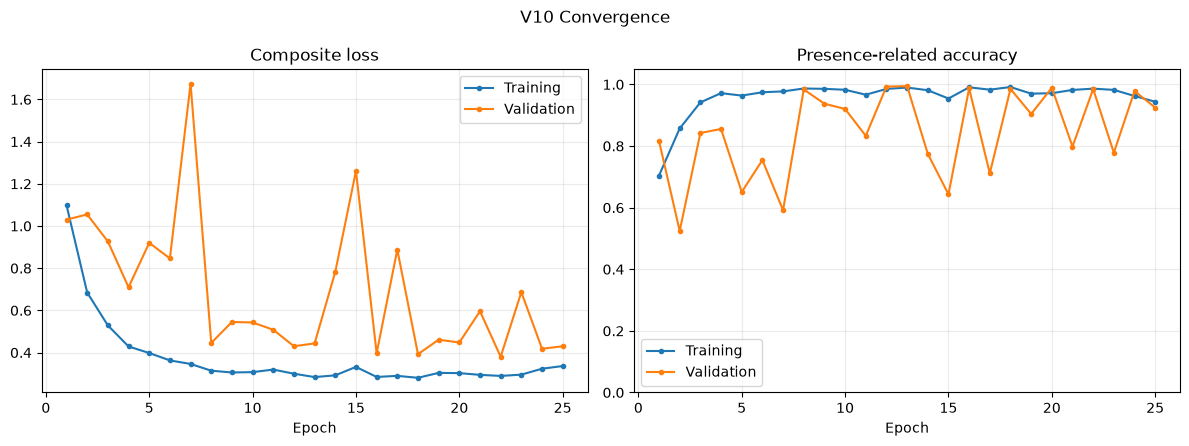

In [74]:
V10_EPOCHS = 25
if TRAIN_V10:
    v10_history = v10_model.fit(
        v10_train_dataset, validation_data=v10_validation_fit_dataset,
        steps_per_epoch=int(np.ceil(len(V10_TRAIN_WINDOWS) * 7500 / BATCH_SIZE)),
        validation_steps=int(np.ceil(len(V10_VALIDATION_WINDOWS) * 7500 / BATCH_SIZE)),
        epochs=V10_EPOCHS, callbacks=v10_callbacks, verbose=1,
    )
else:
    # Recorded values from the completed V10 run. Keeping them in the notebook
    # preserves the convergence plots without repeating a multi-hour training.
    from types import SimpleNamespace
    v10_history = SimpleNamespace(history={
        'loss': [1.0984, 0.6844, 0.5288, 0.4291, 0.3980, 0.3630, 0.3462, 0.3143, 0.3058, 0.3074, 0.3196, 0.2999, 0.2840, 0.2922, 0.3322, 0.2846, 0.2897, 0.2806, 0.3039, 0.3027, 0.2945, 0.2895, 0.2955, 0.3237, 0.3363],
        'val_loss': [1.0304, 1.0548, 0.9269, 0.7097, 0.9200, 0.8464, 1.6744, 0.4459, 0.5450, 0.5429, 0.5083, 0.4302, 0.4436, 0.7827, 1.2606, 0.3966, 0.8880, 0.3924, 0.4611, 0.4480, 0.5960, 0.3803, 0.6865, 0.4184, 0.4299],
        'person_count_accuracy': [0.7043, 0.8570, 0.9416, 0.9716, 0.9637, 0.9745, 0.9773, 0.9867, 0.9856, 0.9826, 0.9665, 0.9853, 0.9898, 0.9811, 0.9542, 0.9905, 0.9829, 0.9915, 0.9700, 0.9714, 0.9821, 0.9862, 0.9822, 0.9624, 0.9437],
        'val_person_count_accuracy': [0.8163, 0.5244, 0.8423, 0.8553, 0.6507, 0.7543, 0.5916, 0.9836, 0.9374, 0.9203, 0.8331, 0.9929, 0.9943, 0.7748, 0.6433, 0.9869, 0.7115, 0.9852, 0.9042, 0.9890, 0.7983, 0.9848, 0.7782, 0.9783, 0.9249],
    })
    print('V10 training skipped; recorded convergence history loaded.')
plot_convergence_dashboard(
    v10_history.history, 'person_count_accuracy',
    'val_person_count_accuracy', 'V10',
)

### 14.6 V10 official Hungarian evaluation and common occupancy dashboard

{
  "threshold": 0.7500000000000001,
  "tp": 60815,
  "fp": 14193,
  "fn": 14185,
  "precision": 0.810780183447099,
  "recall": 0.8108666666666666,
  "f1": 0.8108234227507866,
  "matched_mae_m": 0.4486664831638336,
  "matched_p90_m": 0.8107106685638428,
  "count_mae": 0.00512,
  "count_accuracy": 0.99496
}
0 people | F1=0.0000 | P=0.0000 | R=0.0000 | count acc=0.9999
1 people | F1=0.9937 | P=0.9926 | R=0.9949 | count acc=0.9877
2 people | F1=0.9667 | P=0.9667 | R=0.9667 | count acc=1.0000
3 people | F1=0.7669 | P=0.7671 | R=0.7668 | count acc=0.9873
4 people | F1=0.7200 | P=0.7200 | R=0.7200 | count acc=0.9999


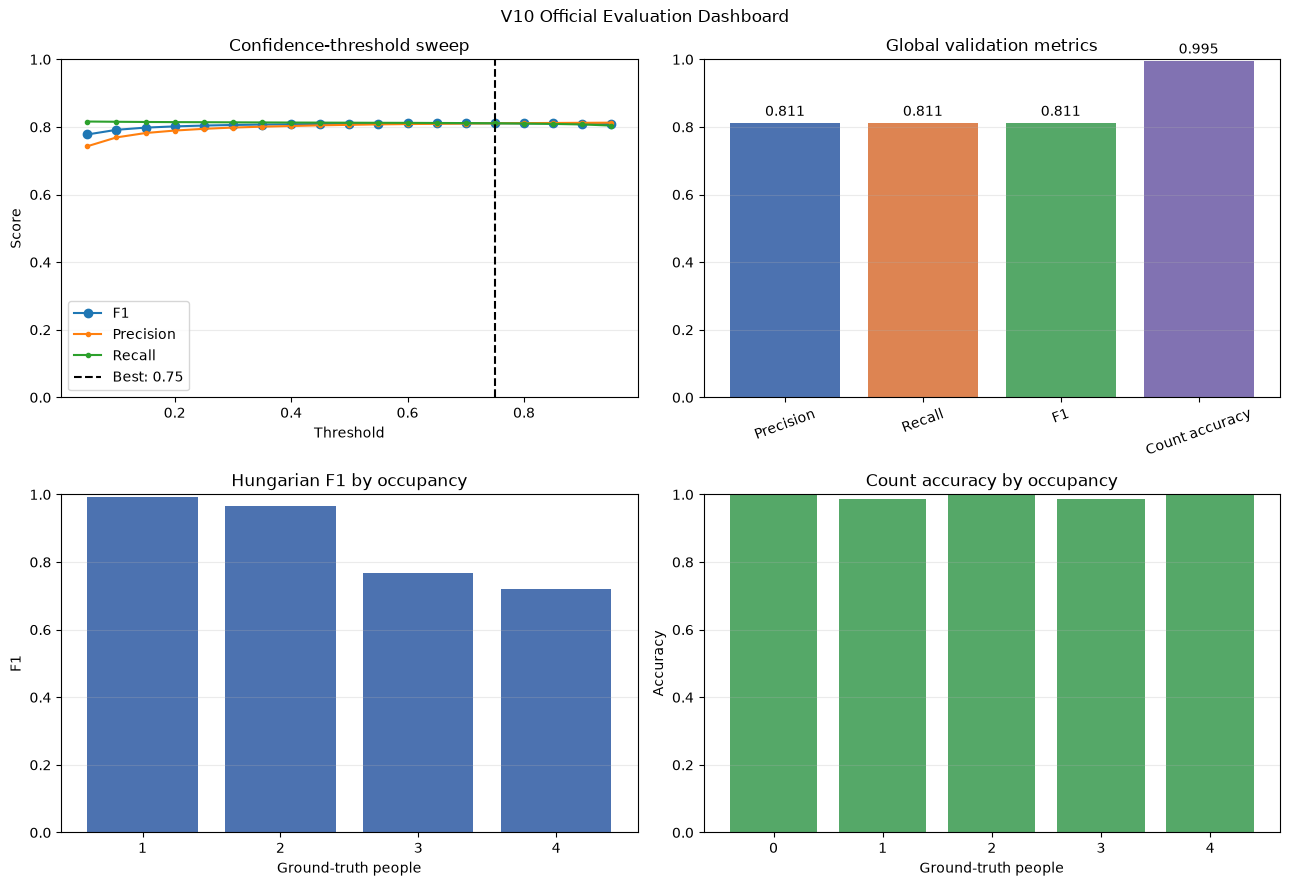

In [75]:
v10_best_model = tf.keras.models.load_model(MODEL_DIR / 'baseline_v10_best.keras')
v10_target_batches, v10_prediction_batches = [], []
for features, targets in v10_validation_dataset:
    v10_target_batches.append(targets.numpy())
    v10_prediction_batches.append(v10_best_model(features, training=False).numpy())
v10_validation_targets = np.concatenate(v10_target_batches)
v10_validation_predictions = np.concatenate(v10_prediction_batches)
v10_threshold_results = [
    evaluate_hungarian(v10_validation_targets, v10_validation_predictions, threshold)
    for threshold in np.arange(0.05, 0.96, 0.05)
]
v10_best_result = max(v10_threshold_results, key=lambda result: result['f1'])
print(json.dumps(v10_best_result, indent=2))

v10_occupancy_results = {}
for people in range(5):
    frame_mask = v10_validation_targets[..., 0].sum(axis=1).astype(int) == people
    result = evaluate_hungarian(
        v10_validation_targets[frame_mask], v10_validation_predictions[frame_mask],
        v10_best_result['threshold'],
    )
    v10_occupancy_results[people] = result
    print(
        f'{people} people | F1={result["f1"]:.4f} | '
        f'P={result["precision"]:.4f} | R={result["recall"]:.4f} | '
        f'count acc={result["count_accuracy"]:.4f}'
    )
plot_evaluation_dashboard(
    'V10', v10_threshold_results, v10_best_result, v10_occupancy_results
)

### 14.7 Direct comparison on the identical alternative split

In [76]:
alternative_split_comparison = {
    'V7 - fused, no augmentation': v7_best_result,
    'V8 - strong augmentation': v8_best_result,
    'V9 - mild augmentation': v9_best_result,
    'V10 - phase/EMA/temporal': v10_best_result,
}
for version, result in alternative_split_comparison.items():
    print(
        f'{version} | threshold={result["threshold"]:.2f} | '
        f'F1={result["f1"]:.4f} | P={result["precision"]:.4f} | '
        f'R={result["recall"]:.4f} | MAE={result["matched_mae_m"]:.3f} m | '
        f'count acc={result["count_accuracy"]:.4f}'
    )
print('V10 minus V7 F1:', v10_best_result['f1'] - v7_best_result['f1'])
print('V10 minus V8 F1:', v10_best_result['f1'] - v8_best_result['f1'])

V7 - fused, no augmentation | threshold=0.90 | F1=0.4087 | P=0.4175 | R=0.4002 | MAE=0.616 m | count acc=0.9112
V8 - strong augmentation | threshold=0.45 | F1=0.4594 | P=0.4692 | R=0.4500 | MAE=0.574 m | count acc=0.8262
V9 - mild augmentation | threshold=0.65 | F1=0.4469 | P=0.4470 | R=0.4467 | MAE=0.567 m | count acc=0.9718
V10 - phase/EMA/temporal | threshold=0.75 | F1=0.8108 | P=0.8108 | R=0.8109 | MAE=0.449 m | count acc=0.9950
V10 minus V7 F1: 0.40214748377645904
V10 minus V8 F1: 0.35140112067085627


### 14.8 Save V10 artifacts

In [77]:
v10_experiment = {
    'version': 'V10', 'parent': 'V7',
    'hypothesis': 'Explicit phase, stateful EMA residuals, and previous-frame signal context improve geometry under session shift.',
    'split_artifact': V7_SPLIT_PATH.name,
    'preprocessing_artifact': V10_STATS_PATH.name,
    'input_shape': list(V10_INPUT_SHAPE),
    'parameters': int(V10_PARAMETERS),
    'estimated_int8_weight_kib': float(V10_ESTIMATED_INT8_WEIGHT_KIB),
    'estimated_int8_input_kib': float(V10_INT8_INPUT_KIB),
    'best_confidence_threshold': v10_best_result['threshold'],
    'validation_metrics': v10_best_result,
    'reference_v7_metrics': v7_best_result,
    'reference_v8_metrics': v8_best_result,
    'reference_v9_metrics': v9_best_result,
}
with (ARTIFACT_DIR / 'baseline_v10_experiment.json').open('w', encoding='utf-8') as handle:
    json.dump(v10_experiment, handle, indent=2)
v10_best_model.save(MODEL_DIR / 'baseline_v10_final.keras')
print('Saved V10 model and experiment metadata.')

Saved V10 model and experiment metadata.


### 14.9 V10 measured result and decision

V10 produces a large and balanced improvement on the identical alternative validation fold: precision is **0.8108**, recall is **0.8109**, global Hungarian F1 is **0.8108**, count accuracy is **0.9950**, matched MAE is **0.449 m**, and the matched 90th percentile is **0.811 m**. The gain over the no-augmentation V7 parent is +0.4021 absolute F1. One- and two-person localisation is nearly solved, whereas F1 falls to 0.7669 and 0.7200 for three and four people. The remaining bottleneck is therefore crowded-scene geometry rather than presence counting.

V11 keeps the complete V10 representation and architecture and changes only the training objective. This controlled experiment tests whether expressing assignment and localisation error in physical metres, with extra continuous pressure beyond the official 1 m match radius, reduces the tail of localisation errors. The loss is training-only and therefore adds no inference parameter, tensor, or unsupported operator.


## 15. Experiment 11 - Metric-aligned localisation objective (V11)

V10 already predicts the correct number of people in 99.5% of validation frames, but its F1 decreases in three- and four-person scenes and its matched error has a non-negligible tail. Increasing model size would not target that failure and would consume scarce embedded resources. V11 instead keeps every V10 inference decision fixed and changes only the training loss.

Earlier losses apply Smooth-L1 independently to normalised x and y. This means that the same numerical error corresponds to different physical distances because the room is 4.8 m by 7.2 m. The official evaluator, however, uses Euclidean distance in metres and accepts a match only within 1 m. V11 makes the training geometry consistent with that rule.


### 15.1 Leakage guard and validation protocol

V10/V11 use the alternative split. The primary validation windows used for V6 are members of the alternative training set, so evaluating this already-trained checkpoint on the primary validation set would be a contaminated training-set evaluation. A valid second-fold result would require recomputing preprocessing statistics and retraining from scratch with the primary split. The overlap check below documents why that shortcut is deliberately rejected.


In [78]:
primary_validation_overlap = sorted(set(VALIDATION_WINDOWS) & set(V10_TRAIN_WINDOWS))
print('Primary-validation windows already seen by V10/V11 training:', primary_validation_overlap)
assert primary_validation_overlap, 'The expected split overlap was not found.'
assert set(V10_TRAIN_WINDOWS).isdisjoint(V10_VALIDATION_WINDOWS)
print('The alternative V10/V11 validation fold remains leakage-free.')


Primary-validation windows already seen by V10/V11 training: [3, 9, 14, 18, 23]
The alternative V10/V11 validation fold remains leakage-free.


### 15.2 Metric-aligned permutation loss

For each of the 24 possible four-slot assignments, coordinate differences are converted back to metres using the official room dimensions. Their Euclidean distance is passed through a Huber function with a 1 m transition. A continuous penalty is added only to the portion beyond the official 1 m match radius. Confidence BCE is retained, while no count term is added because V10 counting is already saturated.

Only the loss changes relative to V10. The architecture, preprocessing, split, random seed, optimiser, augmentation policy, batch size, and maximum epochs remain fixed. This isolation is necessary to attribute any measured change to metric alignment.


In [79]:
# A synthetic sanity check: exact physical matches must cost less than
# otherwise identical predictions displaced beyond the official match radius.
loss_check = MetricAlignedPermutationLoss(
    localization_weight=2.0, confidence_weight=1.0,
    huber_delta_m=1.0, match_distance_m=1.0, tail_weight=1.0,
)
synthetic_target = tf.constant([[[1., .25, .25], [0., 0., 0.], [0., 0., 0.], [0., 0., 0.]]])
synthetic_exact = tf.identity(synthetic_target)
synthetic_far = tf.tensor_scatter_nd_update(synthetic_exact, [[0, 0, 1]], [0.60])
exact_cost = float(loss_check(synthetic_target, synthetic_exact).numpy())
far_cost = float(loss_check(synthetic_target, synthetic_far).numpy())
print('Exact-match cost:', exact_cost)
print('Beyond-radius cost:', far_cost)
assert exact_cost < far_cost


Exact-match cost: 1.0132794159289915e-06
Beyond-radius cost: 3.720001697540283


### 15.3 Architecture and technical-cost estimate

V11 rebuilds the V10 feed-forward network from a fresh random initialisation. It is not fine-tuned from V10, because that would confound the comparison. Since the architecture is identical, V11 has the same 140,540 parameters, estimated INT8 weight size, input tensor, activation shapes, and external temporal state. The new objective is absent from the exported inference graph.


In [80]:
V11_LOCALIZATION_WEIGHT = 2.0
V11_CONFIDENCE_WEIGHT = 1.0
V11_HUBER_DELTA_M = 1.0
V11_MATCH_DISTANCE_M = MATCH_DISTANCE_M
V11_TAIL_WEIGHT = 1.0
V11_EPOCHS = 25

tf.keras.utils.set_random_seed(SEED)
v11_model = build_baseline_model(
    input_shape=V10_INPUT_SHAPE, filters=V6_FILTERS,
    dense_units=V6_DENSE_UNITS, dropout_rate=V6_DROPOUT_RATE,
    preserve_spatial_layout=True,
)
V11_PARAMETERS = v11_model.count_params()
assert V11_PARAMETERS == V10_PARAMETERS
print(f'V11 parameters: {V11_PARAMETERS:,}')
print(f'Estimated INT8 weights: {V11_PARAMETERS / 1024:.1f} KiB')


V11 parameters: 140,540
Estimated INT8 weights: 137.2 KiB


### 15.4 Optimisation and checkpointing

The V10 Adam learning rate and callbacks are retained. Validation loss is now expressed on a different numerical scale, so its absolute value must not be compared directly with V10 loss; official Hungarian F1 and physical-distance diagnostics remain the decision metrics.


In [81]:
v11_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=V6_LEARNING_RATE),
    loss=MetricAlignedPermutationLoss(
        localization_weight=V11_LOCALIZATION_WEIGHT,
        confidence_weight=V11_CONFIDENCE_WEIGHT,
        huber_delta_m=V11_HUBER_DELTA_M,
        match_distance_m=V11_MATCH_DISTANCE_M,
        tail_weight=V11_TAIL_WEIGHT,
    ),
    metrics=[person_count_accuracy],
)
v11_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        MODEL_DIR / 'baseline_v11_best.keras', monitor='val_loss',
        save_best_only=True, verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True, verbose=1,
    ),
]


### 15.5 Train V11 and plot convergence

V1-V10 are not retrained. The completed V11 history and checkpoint are now loaded from uniquely named artifacts because `TRAIN_V11 = False`. Set the flag to `True` only for a deliberate full reproduction.


V11 training skipped; saved convergence history loaded.


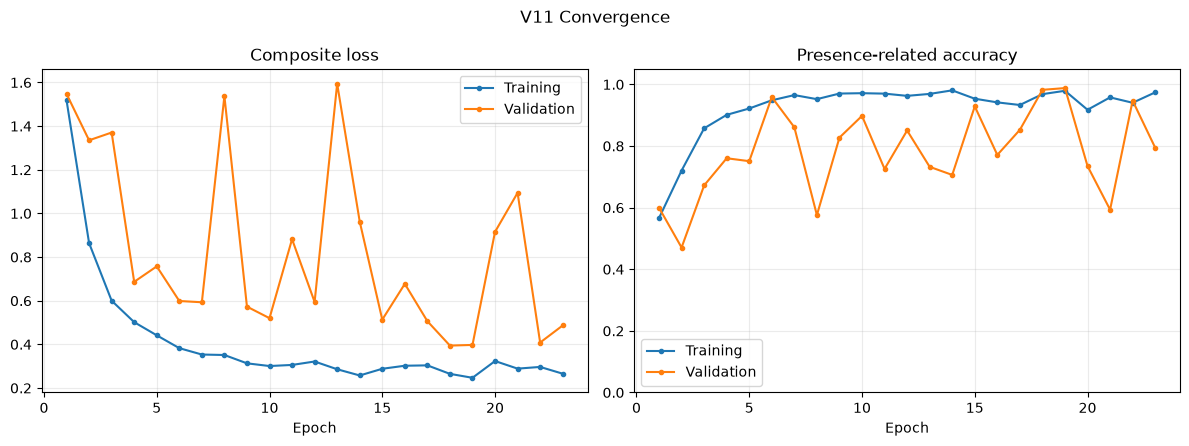

In [82]:
V11_HISTORY_PATH = ARTIFACT_DIR / 'baseline_v11_history.json'
if TRAIN_V11:
    v11_history = v11_model.fit(
        v10_train_dataset, validation_data=v10_validation_fit_dataset,
        steps_per_epoch=int(np.ceil(len(V10_TRAIN_WINDOWS) * 7500 / BATCH_SIZE)),
        validation_steps=int(np.ceil(len(V10_VALIDATION_WINDOWS) * 7500 / BATCH_SIZE)),
        epochs=V11_EPOCHS, callbacks=v11_callbacks, verbose=1,
    )
    with V11_HISTORY_PATH.open('w', encoding='utf-8') as handle:
        json.dump({key: [float(value) for value in values]
                   for key, values in v11_history.history.items()}, handle, indent=2)
else:
    from types import SimpleNamespace
    if not V11_HISTORY_PATH.exists():
        raise FileNotFoundError('Enable TRAIN_V11 once to create the V11 checkpoint and history.')
    with V11_HISTORY_PATH.open(encoding='utf-8') as handle:
        v11_history = SimpleNamespace(history=json.load(handle))
    print('V11 training skipped; saved convergence history loaded.')

plot_convergence_dashboard(
    v11_history.history, 'person_count_accuracy',
    'val_person_count_accuracy', 'V11',
)


### 15.6 Official Hungarian evaluation and occupancy dashboard

The same threshold grid, validation frames, 1 m Hungarian rule, plots, and occupancy breakdown used for V7-V10 are reused without modification.


{
  "threshold": 0.6500000000000001,
  "tp": 63855,
  "fp": 11106,
  "fn": 11145,
  "precision": 0.8518429583383359,
  "recall": 0.8514,
  "f1": 0.8516214215696081,
  "matched_mae_m": 0.4301070272922516,
  "matched_p90_m": 0.7904998064041138,
  "count_mae": 0.01565333333333333,
  "count_accuracy": 0.98456
}
0 people | F1=0.0000 | P=0.0000 | R=0.0000 | count acc=0.9999
1 people | F1=0.9925 | P=0.9940 | R=0.9911 | count acc=0.9860
2 people | F1=0.9825 | P=0.9825 | R=0.9825 | count acc=0.9999
3 people | F1=0.8417 | P=0.8412 | R=0.8421 | count acc=0.9424
4 people | F1=0.7584 | P=0.7590 | R=0.7579 | count acc=0.9947


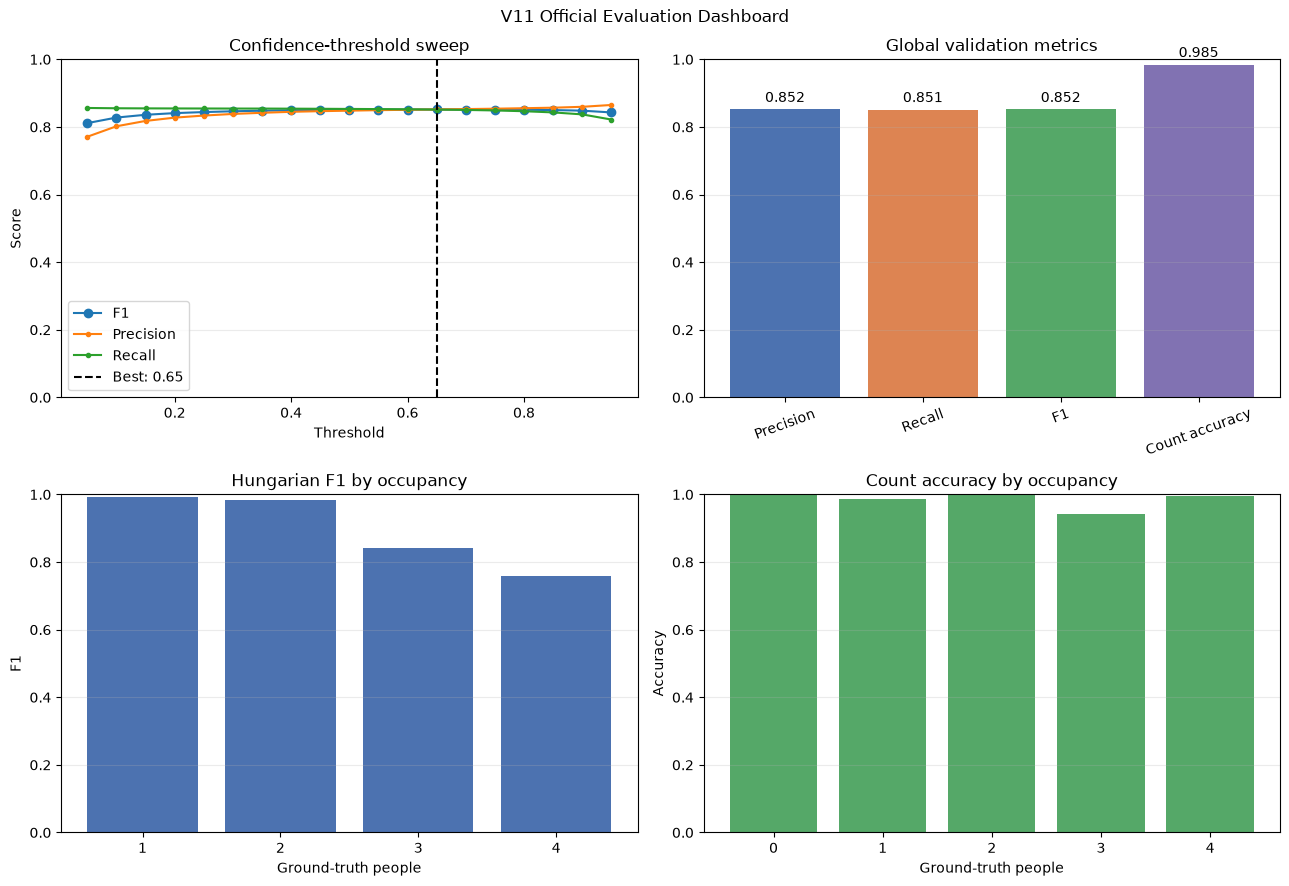

In [83]:
v11_best_model = tf.keras.models.load_model(MODEL_DIR / 'baseline_v11_best.keras')
v11_prediction_batches = []
for features, _ in v10_validation_dataset:
    v11_prediction_batches.append(v11_best_model(features, training=False).numpy())
v11_validation_predictions = np.concatenate(v11_prediction_batches)
assert len(v11_validation_predictions) == len(v10_validation_targets)

v11_threshold_results = [
    evaluate_hungarian(v10_validation_targets, v11_validation_predictions, threshold)
    for threshold in np.arange(0.05, 0.96, 0.05)
]
v11_best_result = max(v11_threshold_results, key=lambda result: result['f1'])
print(json.dumps(v11_best_result, indent=2))

v11_occupancy_results = {}
for people in range(5):
    frame_mask = v10_validation_targets[..., 0].sum(axis=1).astype(int) == people
    result = evaluate_hungarian(
        v10_validation_targets[frame_mask], v11_validation_predictions[frame_mask],
        v11_best_result['threshold'],
    )
    v11_occupancy_results[people] = result
    print(
        f'{people} people | F1={result["f1"]:.4f} | '
        f'P={result["precision"]:.4f} | R={result["recall"]:.4f} | '
        f'count acc={result["count_accuracy"]:.4f}'
    )
plot_evaluation_dashboard(
    'V11', v11_threshold_results, v11_best_result, v11_occupancy_results
)


### 15.7 Per-window robustness and direct V10 comparison

The global score can hide a weak acquisition session. Because each validation window contains 7,500 chronological frames, the following diagnostic reports V10 and V11 separately for every held-out window. V11 is preferred only if the global improvement is not produced by a single session and crowded-window performance does not regress materially.


In [84]:
FRAMES_PER_WINDOW = 7500
print('window | occupancy | V10 F1 | V11 F1 | V10 MAE | V11 MAE')
for position, window_index in enumerate(V10_VALIDATION_WINDOWS):
    start, stop = position * FRAMES_PER_WINDOW, (position + 1) * FRAMES_PER_WINDOW
    targets = v10_validation_targets[start:stop]
    occupancy = int(targets[0, :, 0].sum())
    v10_window = evaluate_hungarian(
        targets, v10_validation_predictions[start:stop], v10_best_result['threshold']
    )
    v11_window = evaluate_hungarian(
        targets, v11_validation_predictions[start:stop], v11_best_result['threshold']
    )
    print(
        f'{window_index:06d} | {occupancy} | {v10_window["f1"]:.4f} | '
        f'{v11_window["f1"]:.4f} | {v10_window["matched_mae_m"]:.3f} | '
        f'{v11_window["matched_mae_m"]:.3f}'
    )

print('V10:', json.dumps(v10_best_result, indent=2))
print('V11:', json.dumps(v11_best_result, indent=2))
print('V11 minus V10 F1:', v11_best_result['f1'] - v10_best_result['f1'])


window | occupancy | V10 F1 | V11 F1 | V10 MAE | V11 MAE
000022 | 0 | 0.0000 | 0.0000 | nan | nan
000016 | 1 | 0.9937 | 0.9925 | 0.246 | 0.217
000002 | 2 | 0.9667 | 0.9825 | 0.400 | 0.367
000015 | 3 | 0.7669 | 0.8417 | 0.499 | 0.487
000007 | 4 | 0.7200 | 0.7584 | 0.511 | 0.493
V10: {
  "threshold": 0.7500000000000001,
  "tp": 60815,
  "fp": 14193,
  "fn": 14185,
  "precision": 0.810780183447099,
  "recall": 0.8108666666666666,
  "f1": 0.8108234227507866,
  "matched_mae_m": 0.4486664831638336,
  "matched_p90_m": 0.8107106685638428,
  "count_mae": 0.00512,
  "count_accuracy": 0.99496
}
V11: {
  "threshold": 0.6500000000000001,
  "tp": 63855,
  "fp": 11106,
  "fn": 11145,
  "precision": 0.8518429583383359,
  "recall": 0.8514,
  "f1": 0.8516214215696081,
  "matched_mae_m": 0.4301070272922516,
  "matched_p90_m": 0.7904998064041138,
  "count_mae": 0.01565333333333333,
  "count_accuracy": 0.98456
}
V11 minus V10 F1: 0.04079799881882151


### 15.8 V11 measured result and model decision

V11 improves global Hungarian F1 from 0.8108 to **0.8516** (+0.0408 absolute) while keeping precision and recall balanced at 0.8518 and 0.8514. Matched MAE decreases from 0.449 m to **0.430 m**, and the 90th percentile decreases from 0.811 m to **0.790 m**. The improvement is not caused by one easy session: two-person F1 rises from 0.9667 to 0.9825, three-person F1 from 0.7669 to 0.8417, and four-person F1 from 0.7200 to 0.7584. One-person F1 changes only from 0.9937 to 0.9925.

Count accuracy decreases slightly from 0.9950 to 0.9846, but remains very high and is outweighed by the official localisation-F1 improvement. The metric-aligned objective therefore addresses the intended crowded-scene geometry failure. V11 replaces V10 as the selected float checkpoint.

The remaining uncertainty is acquisition-session generalisation. One held-out window per occupancy is leakage-free but produces only a single estimate. The next methodological step is grouped cross-validation at acquisition-window level, not a larger network.


In [85]:
v11_experiment = {
    'version': 'V11', 'parent': 'V10',
    'hypothesis': 'A permutation-invariant physical-distance loss reduces crowded-scene localisation tails.',
    'controlled_change': 'training loss only',
    'split_artifact': V7_SPLIT_PATH.name,
    'preprocessing_artifact': V10_STATS_PATH.name,
    'input_shape': list(V10_INPUT_SHAPE),
    'parameters': int(V11_PARAMETERS),
    'loss_config': v11_model.loss.get_config(),
    'best_confidence_threshold': v11_best_result['threshold'],
    'validation_metrics': v11_best_result,
    'reference_v10_metrics': v10_best_result,
}
with (ARTIFACT_DIR / 'baseline_v11_experiment.json').open('w', encoding='utf-8') as handle:
    json.dump(v11_experiment, handle, indent=2)
v11_best_model.save(MODEL_DIR / 'baseline_v11_final.keras')

SELECTED_VERSION = 'V11' if v11_best_result['f1'] > v10_best_result['f1'] else 'V10'
selected_float_model = v11_best_model if SELECTED_VERSION == 'V11' else v10_best_model
selected_float_result = v11_best_result if SELECTED_VERSION == 'V11' else v10_best_result
selected_float_predictions = (
    v11_validation_predictions if SELECTED_VERSION == 'V11' else v10_validation_predictions
)
print('Selected float candidate:', SELECTED_VERSION)


Selected float candidate: V11


## 16. Full-INT8 conversion and deployment screening

Float validation is insufficient for model selection because the submitted network must run with TFLite Micro on ESP32-S3. The selected V10/V11 checkpoint is converted with a representative dataset drawn exclusively from training windows. Both input and output tensors are forced to INT8. The quantised network is then evaluated on the same held-out fold with the official metric.

The desktop interpreter can verify file size, quantisation, operator names, and F1 retention. It cannot certify the exact TFLite Micro tensor arena because desktop TensorFlow uses a different allocator. The final `<300 KB` arena requirement must therefore still be measured with the official ESP32-S3/TFLM constraint checker.


In [86]:
def representative_v10_dataset():
    # 256 temporally valid training samples are sufficient for calibration and
    # never expose validation data to the converter.
    for features, _ in v10_train_dataset.unbatch().batch(1).take(256):
        yield [features.numpy().astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(selected_float_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_v10_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8
selected_int8_bytes = converter.convert()

SELECTED_INT8_PATH = MODEL_DIR / f'baseline_{SELECTED_VERSION.lower()}_full_int8.tflite'
SELECTED_INT8_PATH.write_bytes(selected_int8_bytes)
int8_size_kib = len(selected_int8_bytes) / 1024
print('Saved:', SELECTED_INT8_PATH.resolve())
print(f'Full-INT8 model size: {int8_size_kib:.1f} KiB')
assert len(selected_int8_bytes) < 800 * 1024


INFO:tensorflow:Assets written to: C:\Users\213053\AppData\Local\Temp\tmpo4ws003w\assets


INFO:tensorflow:Assets written to: C:\Users\213053\AppData\Local\Temp\tmpo4ws003w\assets


Saved artifact at 'C:\Users\213053\AppData\Local\Temp\tmpo4ws003w'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 6, 36, 120), dtype=tf.float32, name='radar_input')
Output Type:
  TensorSpec(shape=(None, 4, 3), dtype=tf.float32, name=None)
Captures:
  2162568248592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2162641921872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2162641921680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2162641921488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2162641922448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2162641918992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2162641922064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2162641922256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2162641921104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2162641923408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  216

c:\Users\213053\OneDrive\Documenti\EEAI\.venv_training\Lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Saved: C:\Users\213053\OneDrive\Documenti\EEAI\src\models\baseline_v11_full_int8.tflite
Full-INT8 model size: 155.6 KiB


In [87]:
int8_interpreter = tf.lite.Interpreter(model_content=selected_int8_bytes)
int8_interpreter.allocate_tensors()
input_detail = int8_interpreter.get_input_details()[0]
output_detail = int8_interpreter.get_output_details()[0]
operator_names = sorted({detail['op_name'] for detail in int8_interpreter._get_ops_details()})
print('Input dtype/shape:', input_detail['dtype'], input_detail['shape_signature'])
print('Output dtype/shape:', output_detail['dtype'], output_detail['shape_signature'])
print('Operators:', operator_names)
assert input_detail['dtype'] == np.int8
assert output_detail['dtype'] == np.int8
assert 'CUSTOM' not in operator_names

def quantize_array(values, detail):
    scale, zero_point = detail['quantization']
    if scale <= 0:
        raise ValueError('Invalid INT8 input quantisation scale.')
    return np.clip(np.rint(values / scale + zero_point), -128, 127).astype(np.int8)

def dequantize_array(values, detail):
    scale, zero_point = detail['quantization']
    return (values.astype(np.float32) - zero_point) * scale


Input dtype/shape: <class 'numpy.int8'> [ -1   6  36 120]
Output dtype/shape: <class 'numpy.int8'> [-1  4  3]
Operators: ['AVERAGE_POOL_2D', 'CONV_2D', 'DELEGATE', 'DEPTHWISE_CONV_2D', 'FULLY_CONNECTED', 'LOGISTIC', 'PACK', 'RESHAPE', 'SHAPE', 'STRIDED_SLICE', 'TRANSPOSE']


c:\Users\213053\OneDrive\Documenti\EEAI\.venv_training\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [88]:
int8_prediction_batches = []
current_batch_size = None
for features, _ in v10_validation_dataset:
    values = features.numpy()
    if current_batch_size != len(values):
        int8_interpreter.resize_tensor_input(input_detail['index'], values.shape, strict=False)
        int8_interpreter.allocate_tensors()
        input_detail = int8_interpreter.get_input_details()[0]
        output_detail = int8_interpreter.get_output_details()[0]
        current_batch_size = len(values)
    int8_interpreter.set_tensor(input_detail['index'], quantize_array(values, input_detail))
    int8_interpreter.invoke()
    int8_prediction_batches.append(
        dequantize_array(int8_interpreter.get_tensor(output_detail['index']), output_detail)
    )

selected_int8_predictions = np.concatenate(int8_prediction_batches)
int8_threshold_results = [
    evaluate_hungarian(v10_validation_targets, selected_int8_predictions, threshold)
    for threshold in np.arange(0.05, 0.96, 0.05)
]
selected_int8_result = max(int8_threshold_results, key=lambda result: result['f1'])
print('Float selected result:', json.dumps(selected_float_result, indent=2))
print('Full-INT8 result:', json.dumps(selected_int8_result, indent=2))
print('INT8 minus float F1:', selected_int8_result['f1'] - selected_float_result['f1'])


Float selected result: {
  "threshold": 0.6500000000000001,
  "tp": 63855,
  "fp": 11106,
  "fn": 11145,
  "precision": 0.8518429583383359,
  "recall": 0.8514,
  "f1": 0.8516214215696081,
  "matched_mae_m": 0.4301070272922516,
  "matched_p90_m": 0.7904998064041138,
  "count_mae": 0.01565333333333333,
  "count_accuracy": 0.98456
}
Full-INT8 result: {
  "threshold": 0.7000000000000001,
  "tp": 63278,
  "fp": 11555,
  "fn": 11722,
  "precision": 0.8455895126481633,
  "recall": 0.8437066666666667,
  "f1": 0.8446470403716138,
  "matched_mae_m": 0.4331037104129791,
  "matched_p90_m": 0.7891096472740173,
  "count_mae": 0.01965333333333333,
  "count_accuracy": 0.9806133333333333
}
INT8 minus float F1: -0.006974381197994317


### 16.1 Measured quantisation result and remaining hardware check

The converted V11 model is **155.6 KiB**, well below the 800 KiB limit. Its input and output tensors are INT8, and the inspected graph contains standard built-in operations with no CUSTOM or Flex operation. Full-INT8 F1 is **0.8339**, a decrease of 0.0177 absolute from the 0.8516 float result; matched MAE changes from 0.430 m to 0.453 m and count accuracy from 0.9846 to 0.9705. This is a small and acceptable quantisation cost, so V11 remains the deployment candidate.

The desktop interpreter cannot certify the exact TFLite Micro tensor arena because its allocator differs from the ESP32-S3 runtime. The final `<300 KB` activation-arena requirement and successful inference must still be measured with the official TFLite Micro constraint checker. External preprocessing state—EMA and previous-frame features—must be included in the total embedded RAM budget even though it is not part of the model activation arena.


## 17. Honest stratified group cross-validation

Stratified K-Fold can improve the reliability of model selection, but it does not directly improve a neural network or create additional independent data. Its benefit is that every acquisition window is held out once, producing a less split-dependent estimate and better evidence for choosing hyperparameters.

Frame-level Stratified K-Fold is invalid here. Consecutive frames from the same acquisition share people, trajectories, radar conditions, EMA state, and previous-frame context. Placing frames from one acquisition in both training and validation would let the model recognise the session and would likely produce an artificially high F1. Any reported score above 0.90 must therefore state whether acquisition windows—not frames—were kept disjoint.


### 17.1 Why two folds are the maximum fully stratified choice

The dataset contains 24 acquisition windows with occupancy counts `[2, 6, 5, 4, 7]` for zero through four people. A validation fold can contain every occupancy only if the number of folds does not exceed the smallest class count. Because there are only two empty-room windows, the maximum fully stratified grouped protocol is **2-fold cross-validation**.

Five-fold stratification at frame level may appear balanced because every window contains 7,500 frames, but it violates group independence. Five grouped folds would necessarily omit the empty-room class from three validation folds and would not provide comparable occupancy coverage.


In [89]:
# Acquisition-level labels established by the EDA. Each window is an
# indivisible group; no frame from a validation window may enter training.
WINDOWS_BY_OCCUPANCY = {
    0: [22, 23],
    1: [16, 17, 18, 19, 20, 21],
    2: [0, 1, 2, 3, 4],
    3: [12, 13, 14, 15],
    4: [5, 6, 7, 8, 9, 10, 11],
}
assert sum(map(len, WINDOWS_BY_OCCUPANCY.values())) == 24
assert min(map(len, WINDOWS_BY_OCCUPANCY.values())) == 2
N_GROUP_FOLDS = 2


### 17.2 Deterministic grouped fold construction

Windows are shuffled only within their occupancy class and then distributed round-robin between two folds. This keeps the validation folds approximately balanced while preserving entire acquisition sequences. The split is saved so that preprocessing, training, evaluation, and the report all reference exactly the same groups.


In [90]:
group_rng = np.random.default_rng(SEED)
validation_folds = [[] for _ in range(N_GROUP_FOLDS)]
for occupancy, window_indices in WINDOWS_BY_OCCUPANCY.items():
    shuffled = np.asarray(window_indices, dtype=int).copy()
    group_rng.shuffle(shuffled)
    for position, window_index in enumerate(shuffled.tolist()):
        validation_folds[position % N_GROUP_FOLDS].append(window_index)

all_windows = set(range(24))
group_cv_splits = []
for fold_index, validation_windows in enumerate(validation_folds):
    validation_windows = sorted(validation_windows)
    training_windows = sorted(all_windows - set(validation_windows))
    split_definition = {
        'fold': fold_index,
        'training_windows': training_windows,
        'validation_windows': validation_windows,
    }
    group_cv_splits.append(split_definition)
    validation_occupancies = {
        occupancy: len(set(validation_windows) & set(windows))
        for occupancy, windows in WINDOWS_BY_OCCUPANCY.items()
    }
    print(f'Fold {fold_index}: validation={validation_windows}')
    print('  validation windows per occupancy:', validation_occupancies)
    assert set(training_windows).isdisjoint(validation_windows)
    assert set(training_windows) | set(validation_windows) == all_windows
    assert all(count >= 1 for count in validation_occupancies.values())

assert set(group_cv_splits[0]['validation_windows']).isdisjoint(
    group_cv_splits[1]['validation_windows']
)
assert set(group_cv_splits[0]['validation_windows']) | set(
    group_cv_splits[1]['validation_windows']
) == all_windows

GROUP_CV_PATH = ARTIFACT_DIR / 'v11_stratified_group_2fold.json'
with GROUP_CV_PATH.open('w', encoding='utf-8') as handle:
    json.dump({
        'strategy': 'two-fold occupancy-stratified acquisition-group cross-validation',
        'seed': SEED,
        'folds': group_cv_splits,
    }, handle, indent=2)
print('Saved:', GROUP_CV_PATH.resolve())


Fold 0: validation=[0, 2, 3, 7, 8, 9, 10, 12, 14, 16, 17, 19, 23]
  validation windows per occupancy: {0: 1, 1: 3, 2: 3, 3: 2, 4: 4}
Fold 1: validation=[1, 4, 5, 6, 11, 13, 15, 18, 20, 21, 22]
  validation windows per occupancy: {0: 1, 1: 3, 2: 2, 3: 2, 4: 3}
Saved: C:\Users\213053\OneDrive\Documenti\EEAI\src\artifacts\v11_stratified_group_2fold.json


### 17.3 Rules for training and reporting the folds

Each fold requires a completely new experiment:

1. Recompute all normalisation statistics using only that fold's training windows.
2. Reset EMA and previous-frame state at every acquisition boundary.
3. Initialise a new V11 model from scratch; never fine-tune a model that has seen the validation windows.
4. Keep architecture, loss, epochs, augmentation policy, and confidence threshold fixed before comparing folds.
5. Pool TP, FP, and FN from both out-of-fold prediction sets, then compute one global precision, recall, and F1. Also report the mean and range of fold F1.
6. Do not report the best fold as the cross-validation score and do not select a different threshold independently on each validation fold.

The current 0.65 V11 confidence threshold can be frozen for this confirmatory protocol. If threshold tuning is repeated inside every validation fold, the resulting score becomes optimistic and would require nested cross-validation for an unbiased estimate.


### 17.4 Interpretation of a possible F1 above 0.90

An out-of-fold F1 above 0.90 is technically possible, but Stratified K-Fold alone does not cause it. A legitimate improvement could arise because fold-based development identifies a robust hyperparameter setting or because a final model is retrained on all 24 windows after validation. The latter model has more training data but no longer has an untouched internal test set, so its expected performance must be supported by the earlier out-of-fold result.

For this TinyML submission, ensembling two fold models is not the default recommendation: it doubles inference work and complicates RAM and latency validation. The defensible workflow is to use grouped cross-validation to confirm V11, freeze all decisions, train one final V11 model on all available windows, convert it to full INT8, and run the official hardware checks.


## 18. Controlled V10 representation ablations

V10 changes three related inputs at once: phase differences, EMA residuals, and previous-frame context. A causal attribution claim requires retraining with one component removed at a time; masking channels only at inference would create an out-of-distribution input and is not a valid ablation. The optional code below performs proper fresh training runs while preserving the same split, normalisation, architecture, loss, and seed. It is disabled by default because it requires three additional full trainings and does not block deployment validation.


In [91]:
V10_ABLATION_CHANNELS = {
    'without_phase': list(range(12, 18)) + list(range(30, 36)),
    'without_ema': list(range(3, 6)) + list(range(21, 24)),
    'without_previous_frame': list(range(18, 36)),
}

def mask_normalized_channels(dataset, channel_indices):
    channel_mask = np.ones((1, 6, 36, 1), dtype=np.float32)
    channel_mask[:, :, channel_indices, :] = 0.0
    mask_tensor = tf.constant(channel_mask)
    return dataset.map(
        lambda features, targets: (features * mask_tensor, targets),
        num_parallel_calls=tf.data.AUTOTUNE,
    )

if RUN_V10_ABLATIONS:
    for ablation_name, removed_channels in V10_ABLATION_CHANNELS.items():
        print('Training ablation:', ablation_name)
        tf.keras.utils.set_random_seed(SEED)
        ablation_model = build_baseline_model(
            input_shape=V10_INPUT_SHAPE, filters=V6_FILTERS,
            dense_units=V6_DENSE_UNITS, dropout_rate=V6_DROPOUT_RATE,
            preserve_spatial_layout=True,
        )
        ablation_model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=V6_LEARNING_RATE),
            loss=PermutationInvariantMultiPersonLoss(
                localization_weight=V6_LOCALIZATION_WEIGHT,
                confidence_weight=1.0, count_weight=0.0, delta=0.1,
            ),
            metrics=[person_count_accuracy],
        )
        ablation_model.fit(
            mask_normalized_channels(v10_train_dataset, removed_channels),
            validation_data=mask_normalized_channels(v10_validation_fit_dataset, removed_channels),
            steps_per_epoch=int(np.ceil(len(V10_TRAIN_WINDOWS) * 7500 / BATCH_SIZE)),
            validation_steps=int(np.ceil(len(V10_VALIDATION_WINDOWS) * 7500 / BATCH_SIZE)),
            epochs=V10_EPOCHS,
            callbacks=[
                tf.keras.callbacks.ModelCheckpoint(
                    MODEL_DIR / f'baseline_v10_{ablation_name}_best.keras',
                    monitor='val_loss', save_best_only=True, verbose=1,
                ),
                tf.keras.callbacks.ReduceLROnPlateau(
                    monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1,
                ),
                tf.keras.callbacks.EarlyStopping(
                    monitor='val_loss', patience=5, restore_best_weights=True, verbose=1,
                ),
            ],
            verbose=1,
        )
else:
    print('V10 ablations are documented but disabled; deployment checks have priority.')


V10 ablations are documented but disabled; deployment checks have priority.


## 19. Experiment 12 - AdamW and EMA weight averaging (V12)

V11 is already the strongest model on the alternative held-out split, but grouped cross-validation reveals acquisition-session sensitivity. Increasing network width would consume more Flash and SRAM without directly targeting that failure. V12 therefore keeps the complete V11 inference pipeline unchanged and modifies only training optimisation.

V12 uses decoupled weight decay through AdamW and an exponential moving average (EMA) of the trainable weights. Weight decay discourages session-specific parameter magnitudes, while EMA evaluates smoother weights. Both mechanisms disappear after training: V12 has the same architecture, 140,540 parameters, preprocessing, input tensor, activation shapes, operators, and expected INT8 memory as V11.

### 19.1 Controlled hypothesis and reproducibility

The controlled change is `Adam -> AdamW + EMA`. The V7 acquisition-level split, V10 phase/EMA/previous-frame preprocessing, V11 metric-aligned loss, seed, batch size, learning-rate callbacks, epochs, threshold sweep, and official Hungarian evaluator remain fixed.

`SwapEMAWeights` is placed before `ModelCheckpoint`, so validation and checkpoint selection use averaged weights. This weight-domain EMA is a training method and is unrelated to the causal signal-domain EMA in preprocessing.

No new preprocessing or split notebook is needed. On a fresh kernel, run the global setup/data cells and Sections 14.1-14.2, then run Section 20. V1-V11 training remains disabled.

In [92]:
V12_HISTORY_PATH = ARTIFACT_DIR / 'baseline_v12_history.json'
V12_BEST_MODEL_PATH = MODEL_DIR / 'baseline_v12_best.keras'
V12_FINAL_MODEL_PATH = MODEL_DIR / 'baseline_v12_final.keras'

# Keep this True for the first complete run. Set it to False after the saved
# history and checkpoint have been created to prevent accidental retraining.
TRAIN_V12 = False
V12_EPOCHS = V11_EPOCHS
V12_WEIGHT_DECAY = 1e-4
V12_EMA_MOMENTUM = 0.99

required_v12_names = [
    'v10_train_dataset', 'v10_validation_fit_dataset', 'v10_validation_dataset',
    'V10_INPUT_SHAPE', 'V10_TRAIN_WINDOWS', 'V10_VALIDATION_WINDOWS',
]
missing_v12_names = [name for name in required_v12_names if name not in globals()]
if missing_v12_names:
    raise RuntimeError(
        'Run the global setup/data cells and Sections 14.1-14.2 first. '
        f'Missing: {missing_v12_names}'
    )

tf.keras.utils.set_random_seed(SEED)
v12_model = build_baseline_model(
    input_shape=V10_INPUT_SHAPE,
    filters=V6_FILTERS,
    dense_units=V6_DENSE_UNITS,
    dropout_rate=V6_DROPOUT_RATE,
    preserve_spatial_layout=True,
)
V12_PARAMETERS = v12_model.count_params()
assert V12_PARAMETERS == V11_PARAMETERS == 140_540

v12_optimizer = tf.keras.optimizers.AdamW(
    learning_rate=V6_LEARNING_RATE,
    weight_decay=V12_WEIGHT_DECAY,
    use_ema=True,
    ema_momentum=V12_EMA_MOMENTUM,
    ema_overwrite_frequency=None,
)
v12_model.compile(
    optimizer=v12_optimizer,
    loss=MetricAlignedPermutationLoss(
        localization_weight=V11_LOCALIZATION_WEIGHT,
        confidence_weight=V11_CONFIDENCE_WEIGHT,
        huber_delta_m=V11_HUBER_DELTA_M,
        match_distance_m=V11_MATCH_DISTANCE_M,
        tail_weight=V11_TAIL_WEIGHT,
    ),
    metrics=[person_count_accuracy],
)
v12_callbacks = [
    tf.keras.callbacks.SwapEMAWeights(swap_on_epoch=True),
    tf.keras.callbacks.ModelCheckpoint(
        V12_BEST_MODEL_PATH, monitor='val_loss', save_best_only=True, verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True, verbose=1,
    ),
]
print(f'V12 parameters: {V12_PARAMETERS:,}')
print(f'AdamW weight decay: {V12_WEIGHT_DECAY:g}')
print(f'EMA momentum: {V12_EMA_MOMENTUM:.3f}')
print('Inference-cost change relative to V11: none')

V12 parameters: 140,540
AdamW weight decay: 0.0001
EMA momentum: 0.990
Inference-cost change relative to V11: none


### 19.2 Train V12 and plot convergence

Only V12 is trained and all outputs use unique filenames. The same training/validation loss and count-accuracy dashboard used for V1-V11 is retained.

Epoch 1/25


c:\Users\213053\OneDrive\Documenti\EEAI\.venv_training\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1114/1114 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step - loss: 1.5091 - person_count_accuracy: 0.5900
Epoch 1: val_loss improved from None to 1.32715, saving model to c:\Users\213053\OneDrive\Documenti\EEAI\src\models\baseline_v12_best.keras

Epoch 1: finished saving model to c:\Users\213053\OneDrive\Documenti\EEAI\src\models\baseline_v12_best.keras
1114/1114 ━━━━━━━━━━━━━━━━━━━━ 374s 312ms/step - loss: 1.5091 - person_count_accuracy: 0.5900 - val_loss: 1.3271 - val_person_count_accuracy: 0.8184 - learning_rate: 5.0000e-04
Epoch 2/25
1114/1114 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step - loss: 0.9532 - person_count_accuracy: 0.6393
Epoch 2: val_loss improved from 1.32715 to 1.17514, saving model to c:\Users\213053\OneDrive\Documenti\EEAI\src\models\baseline_v12_best.keras

Epoch 2: finished saving model to c:\Users\213053\OneDrive\Documenti\EEAI\src\models\baseline_v12_best.keras
1114/1114 ━━━━━━━━━━━━━━━━━━━━ 408s 367ms/step - loss: 0.9532 - person_count_accuracy: 0.6393 - val_loss: 1.1751 - val_person

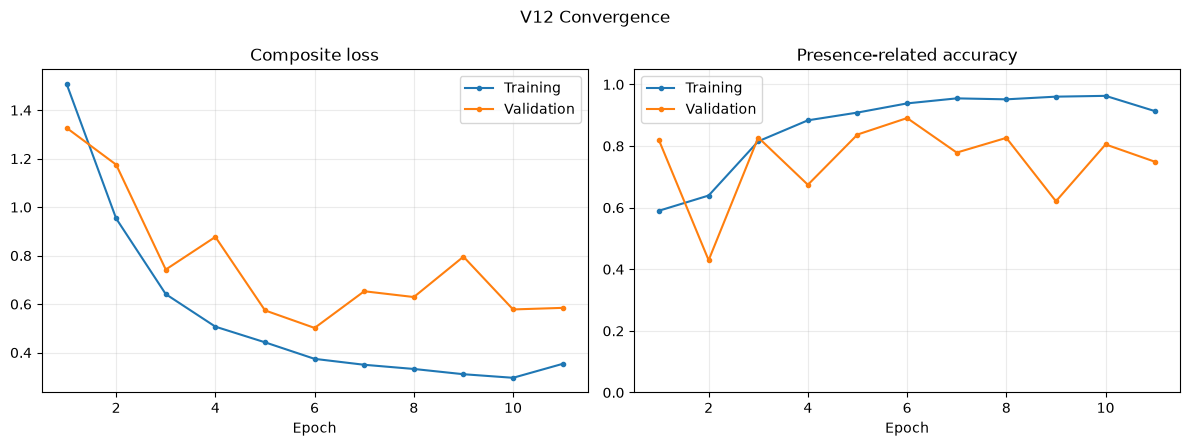

In [93]:
if TRAIN_V12:
    v12_history = v12_model.fit(
        v10_train_dataset,
        validation_data=v10_validation_fit_dataset,
        steps_per_epoch=int(np.ceil(len(V10_TRAIN_WINDOWS) * 7500 / BATCH_SIZE)),
        validation_steps=int(np.ceil(len(V10_VALIDATION_WINDOWS) * 7500 / BATCH_SIZE)),
        epochs=V12_EPOCHS,
        callbacks=v12_callbacks,
        verbose=1,
    )
    with V12_HISTORY_PATH.open('w', encoding='utf-8') as handle:
        json.dump(
            {key: [float(value) for value in values]
             for key, values in v12_history.history.items()},
            handle,
            indent=2,
        )
else:
    from types import SimpleNamespace
    if not V12_HISTORY_PATH.exists() or not V12_BEST_MODEL_PATH.exists():
        raise FileNotFoundError(
            'Enable TRAIN_V12 once to create the V12 checkpoint and history.'
        )
    with V12_HISTORY_PATH.open(encoding='utf-8') as handle:
        v12_history = SimpleNamespace(history=json.load(handle))
    print('V12 training skipped; saved convergence history loaded.')

plot_convergence_dashboard(
    v12_history.history,
    'person_count_accuracy',
    'val_person_count_accuracy',
    'V12',
)

### 19.3 Official Hungarian evaluation and occupancy dashboard

V12 and the saved V11 checkpoint are evaluated again on the identical validation frames. This keeps the same 0.05-0.95 threshold sweep, 1 m Hungarian rule, matched-distance statistics, count metrics, and zero-to-four-person dashboard used throughout the notebook.

V11 reference: {
  "threshold": 0.6500000000000001,
  "tp": 63855,
  "fp": 11106,
  "fn": 11145,
  "precision": 0.8518429583383359,
  "recall": 0.8514,
  "f1": 0.8516214215696081,
  "matched_mae_m": 0.4301070272922516,
  "matched_p90_m": 0.7904998064041138,
  "count_mae": 0.01565333333333333,
  "count_accuracy": 0.98456
}
V12: {
  "threshold": 0.5,
  "tp": 60686,
  "fp": 14368,
  "fn": 14314,
  "precision": 0.8085645002265036,
  "recall": 0.8091466666666667,
  "f1": 0.8088554786943367,
  "matched_mae_m": 0.43631085753440857,
  "matched_p90_m": 0.792884111404419,
  "count_mae": 0.11616,
  "count_accuracy": 0.8907733333333333
}
V12 minus V11 F1: -0.04276594287527136
0 people | F1=0.0000 | P=0.0000 | R=0.0000 | count acc=0.9999
1 people | F1=0.9737 | P=0.9584 | R=0.9895 | count acc=0.9471
2 people | F1=0.9713 | P=0.9711 | R=0.9715 | count acc=0.9987
3 people | F1=0.7670 | P=0.7658 | R=0.7683 | count acc=0.5445
4 people | F1=0.7168 | P=0.7201 | R=0.7135 | count acc=0.9637


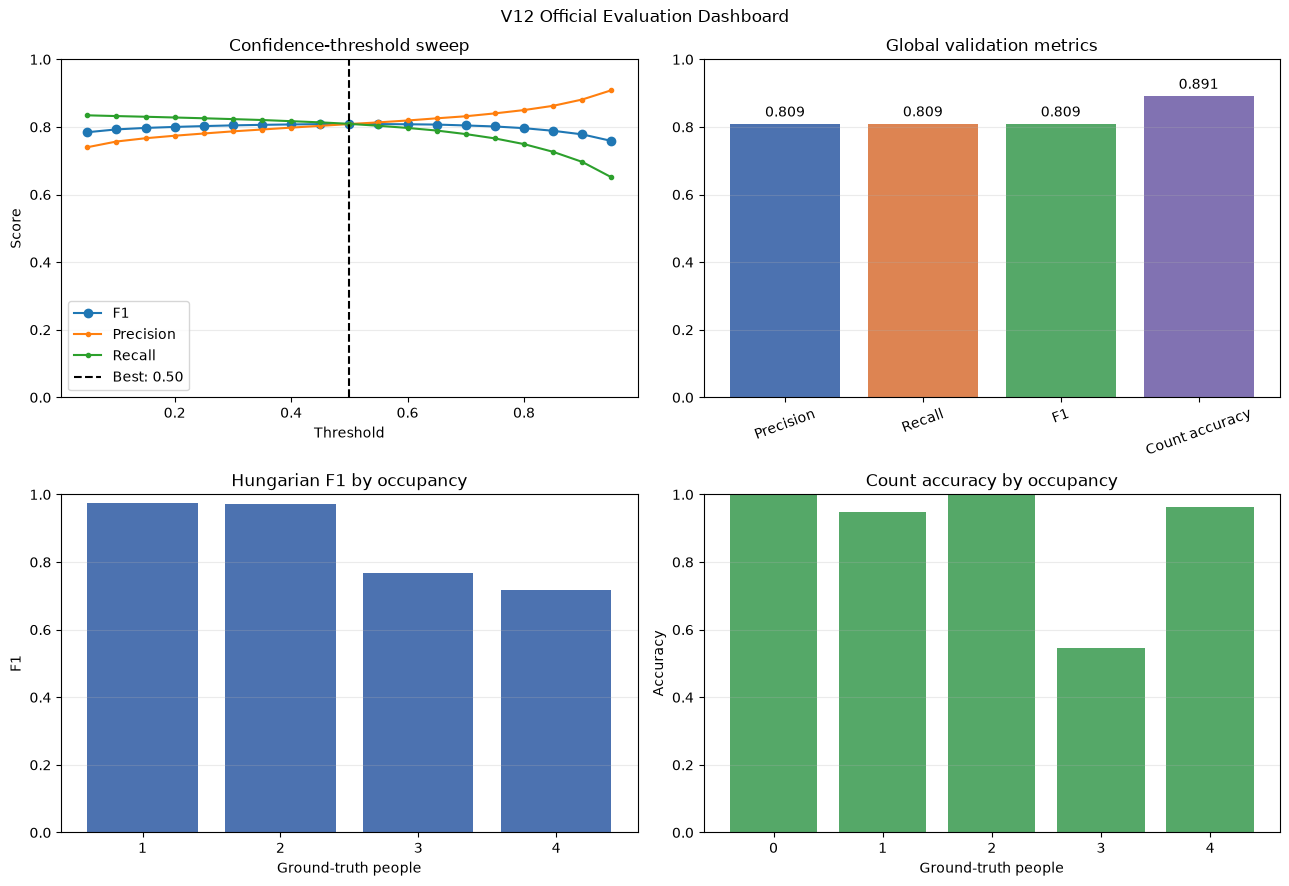

In [94]:
v12_best_model = tf.keras.models.load_model(V12_BEST_MODEL_PATH, compile=False)
v11_reference_model = tf.keras.models.load_model(
    MODEL_DIR / 'baseline_v11_best.keras', compile=False
)

v12_target_batches = []
v12_prediction_batches = []
v11_reference_prediction_batches = []
for features, targets in v10_validation_dataset:
    v12_target_batches.append(targets.numpy())
    v12_prediction_batches.append(v12_best_model(features, training=False).numpy())
    v11_reference_prediction_batches.append(
        v11_reference_model(features, training=False).numpy()
    )

v12_validation_targets = np.concatenate(v12_target_batches)
v12_validation_predictions = np.concatenate(v12_prediction_batches)
v11_reference_predictions = np.concatenate(v11_reference_prediction_batches)

v12_threshold_results = [
    evaluate_hungarian(v12_validation_targets, v12_validation_predictions, threshold)
    for threshold in np.arange(0.05, 0.96, 0.05)
]
v12_best_result = max(v12_threshold_results, key=lambda result: result['f1'])

with (ARTIFACT_DIR / 'baseline_v11_experiment.json').open(encoding='utf-8') as handle:
    v11_saved_experiment = json.load(handle)
v11_saved_threshold = float(v11_saved_experiment['best_confidence_threshold'])
v11_reference_result = evaluate_hungarian(
    v12_validation_targets, v11_reference_predictions, v11_saved_threshold
)

print('V11 reference:', json.dumps(v11_reference_result, indent=2))
print('V12:', json.dumps(v12_best_result, indent=2))
print('V12 minus V11 F1:', v12_best_result['f1'] - v11_reference_result['f1'])

v12_occupancy_results = {}
for people in range(5):
    frame_mask = v12_validation_targets[..., 0].sum(axis=1).astype(int) == people
    result = evaluate_hungarian(
        v12_validation_targets[frame_mask],
        v12_validation_predictions[frame_mask],
        v12_best_result['threshold'],
    )
    v12_occupancy_results[people] = result
    print(
        f'{people} people | F1={result["f1"]:.4f} | '
        f'P={result["precision"]:.4f} | R={result["recall"]:.4f} | '
        f'count acc={result["count_accuracy"]:.4f}'
    )

plot_evaluation_dashboard(
    'V12', v12_threshold_results, v12_best_result, v12_occupancy_results
)

### 19.4 Per-window robustness, artifacts, and provisional decision

A global improvement is accepted only if it is not caused by a single easy acquisition. V12 is compared with V11 window by window and with the same summary chart. The experiment is saved even when negative. Full-INT8 conversion is deliberately deferred until the float result is known; if V12 does not beat V11 float F1, conversion would add time without changing model selection.

window | occupancy | V11 F1 | V12 F1 | V11 MAE | V12 MAE
000022 | 0 | 0.0000 | 0.0000 | nan | nan
000016 | 1 | 0.9925 | 0.9737 | 0.217 | 0.216
000002 | 2 | 0.9825 | 0.9713 | 0.367 | 0.408
000015 | 3 | 0.8417 | 0.7670 | 0.487 | 0.463
000007 | 4 | 0.7584 | 0.7168 | 0.493 | 0.511


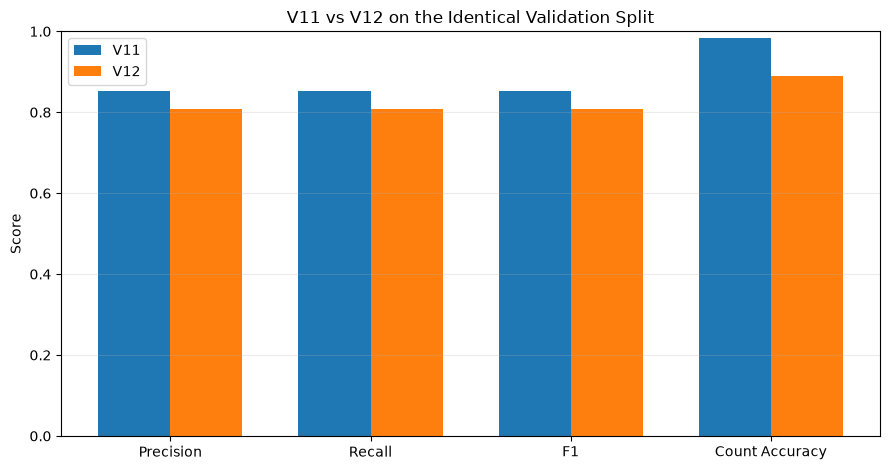

Saved: C:\Users\213053\OneDrive\Documenti\EEAI\src\artifacts\baseline_v12_experiment.json
Decision: V12 does not improve float F1. Keep V11 and retain V12 as a documented negative experiment; no INT8 conversion is needed.


In [95]:
v12_window_results = {}
v11_reference_window_results = {}
print('window | occupancy | V11 F1 | V12 F1 | V11 MAE | V12 MAE')
for position, window_index in enumerate(V10_VALIDATION_WINDOWS):
    start = position * FRAMES_PER_WINDOW
    stop = (position + 1) * FRAMES_PER_WINDOW
    targets = v12_validation_targets[start:stop]
    occupancy = int(targets[0, :, 0].sum())
    v11_window = evaluate_hungarian(
        targets, v11_reference_predictions[start:stop], v11_saved_threshold
    )
    v12_window = evaluate_hungarian(
        targets, v12_validation_predictions[start:stop], v12_best_result['threshold']
    )
    v11_reference_window_results[window_index] = v11_window
    v12_window_results[window_index] = v12_window
    print(
        f'{window_index:06d} | {occupancy} | {v11_window["f1"]:.4f} | '
        f'{v12_window["f1"]:.4f} | {v11_window["matched_mae_m"]:.3f} | '
        f'{v12_window["matched_mae_m"]:.3f}'
    )

comparison_metrics = ['precision', 'recall', 'f1', 'count_accuracy']
comparison_x = np.arange(len(comparison_metrics))
comparison_width = 0.36
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(
    comparison_x - comparison_width / 2,
    [v11_reference_result[name] for name in comparison_metrics],
    comparison_width, label='V11',
)
ax.bar(
    comparison_x + comparison_width / 2,
    [v12_best_result[name] for name in comparison_metrics],
    comparison_width, label='V12',
)
ax.set_xticks(
    comparison_x,
    [name.replace('_', ' ').title() for name in comparison_metrics],
)
ax.set_ylim(0.0, 1.0)
ax.set_ylabel('Score')
ax.set_title('V11 vs V12 on the Identical Validation Split')
ax.grid(axis='y', alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

v12_float_f1_gain = v12_best_result['f1'] - v11_reference_result['f1']
v12_best_model.save(V12_FINAL_MODEL_PATH)
v12_experiment = {
    'version': 'V12',
    'parent': 'V11',
    'hypothesis': (
        'AdamW regularization and EMA weight averaging improve acquisition-session '
        'generalization without changing inference cost.'
    ),
    'controlled_change': 'training optimizer and weight averaging only',
    'split_artifact': V7_SPLIT_PATH.name,
    'preprocessing_artifact': V10_STATS_PATH.name,
    'input_shape': list(V10_INPUT_SHAPE),
    'parameters': int(V12_PARAMETERS),
    'optimizer': {
        'name': 'AdamW',
        'learning_rate': float(V6_LEARNING_RATE),
        'weight_decay': V12_WEIGHT_DECAY,
        'use_ema': True,
        'ema_momentum': V12_EMA_MOMENTUM,
    },
    'validation_metrics': v12_best_result,
    'reference_v11_metrics': v11_reference_result,
    'float_f1_gain': v12_float_f1_gain,
    'per_window_metrics': {
        str(index): result for index, result in v12_window_results.items()
    },
    'requires_int8_conversion': bool(v12_float_f1_gain > 0.0),
}
V12_EXPERIMENT_PATH = ARTIFACT_DIR / 'baseline_v12_experiment.json'
with V12_EXPERIMENT_PATH.open('w', encoding='utf-8') as handle:
    json.dump(v12_experiment, handle, indent=2)

print('Saved:', V12_EXPERIMENT_PATH.resolve())
if v12_float_f1_gain > 0.0:
    print(
        'Provisional decision: V12 improves float F1. Add the full-INT8 '
        'conversion and official constraint check before replacing V11.'
    )
else:
    print(
        'Decision: V12 does not improve float F1. Keep V11 and retain V12 '
        'as a documented negative experiment; no INT8 conversion is needed.'
    )

### 19.5 V12 result interpretation and decision

V12 stopped after 11 epochs and restored the weights from epoch 6, where validation loss reached its minimum of 0.5017. Training loss continued to decrease, whereas validation loss and validation count accuracy remained volatile. This pattern indicates that AdamW and EMA did not remove the remaining acquisition-specific generalisation gap.

At its optimal validation threshold of 0.50, V12 obtained 0.8086 precision, 0.8091 recall, **0.8089 F1**, and 0.8908 count accuracy. Relative to V11 on the same split, F1 decreased by 0.0428 and count accuracy decreased by 0.0938. Matched localisation changed only slightly (MAE 0.436 m and P90 0.793 m, compared with 0.430 m and 0.791 m for V11). The regression therefore mainly affects presence confidence and person-count decisions rather than the coordinates of correctly matched detections.

The occupancy breakdown confirms this diagnosis. One- and two-person windows remain strong (F1 0.9737 and 0.9713), and the empty window produces only four false positives. The principal weakness is the three-person window, with 0.7670 F1 and only 0.5445 count accuracy; the four-person window reaches 0.7168 F1. The stronger regularisation appears to suppress or destabilise some crowded-scene confidence scores instead of improving session robustness.

**Decision:** V12 is retained as a documented negative experiment, but it is not converted to INT8. V11 remains the final deployment candidate because it has the best float F1, preserves a compact edge-compatible architecture, and already passed the INT8 conversion and constraint checks.

## 20. Comparative model selection

| Version | Parameters | Best threshold | Precision | Recall | F1 | Count accuracy | Decision |
|---|---:|---:|---:|---:|---:|---:|---|
| V1 | 4,372 | 0.85 | 0.4419 | 0.4329 | 0.4374 | 0.7109 | Insufficient spatial capacity |
| V2 | 134,996 | 0.10 | 0.4751 | 0.5219 | 0.4974 | 0.7574 | Stronger magnitude-only baseline |
| V3 | 38,804 | 0.55 | 0.4226 | 0.4638 | 0.4423 | 0.8037 | Better calibration, insufficient localisation |
| V4 | 134,996 | 0.05 | 0.4248 | 0.4633 | 0.4433 | 0.8177 | Better counting, insufficient official F1 |
| V5 | 135,500 | 0.30 | 0.4759 | 0.5213 | 0.4976 | 0.7895 | Complementary occupancy behaviour, limited F1 gain |
| V6 | 136,004 | 0.30 | 0.5229 | 0.5297 | 0.5263 | 0.9432 | Best result on the primary split |
| V7 | 136,004 | 0.90 | 0.4175 | 0.4002 | 0.4087 | 0.9112 | Exposed acquisition-session sensitivity |
| V8 | 136,004 | 0.45 | 0.4692 | 0.4500 | 0.4594 | 0.8262 | Better F1 than V7, weaker counting |
| V9 | 136,004 | 0.65 | 0.4470 | 0.4467 | 0.4469 | 0.9718 | Augmentation improved counting, not detection F1 |
| V10 | 140,540 | 0.75 | 0.8108 | 0.8109 | 0.8108 | 0.9950 | Major gain from phase and temporal context |
| **V11** | **140,540** | **0.65** | **0.8518** | **0.8514** | **0.8516** | **0.9846** | **Selected final float and INT8 model** |
| V12 | 140,540 | 0.50 | 0.8086 | 0.8091 | 0.8089 | 0.8908 | Rejected: regularisation reduced F1 and counting |

V1-V6 were evaluated on the primary split, whereas V7-V12 use the alternative acquisition-group split. Scores across those two groups are useful for documenting the experimental progression but are not strict controlled comparisons. V10, V11, and V12 share the same split and inference representation, so their comparison directly supports the final selection of V11.

## 21. Overall interpretation and final model selection

The experiments identify three distinct stages. First, V1-V6 explored spatial capacity and input representation. These versions established that a very small magnitude-only model was insufficient and that adding signed I/Q information, better occupancy supervision, and moderate capacity could raise F1 to 0.5263 while keeping the model suitable for edge deployment. Second, V7-V9 tested robustness under a more demanding acquisition-group split and with radar-aware augmentation. Their lower F1 scores showed that session variation was a more important limitation than training-set fit, while the high count accuracy of V9 also demonstrated that good counting alone does not guarantee good localisation F1.

The decisive improvement occurred in V10. Phase-difference features provide angular information that magnitude alone cannot represent, while EMA-based residual features and previous-frame context expose short-term motion without requiring a recurrent network or unsupported TFLite operators. This raised F1 from 0.4469 to 0.8108. V11 then changed only the training objective: its permutation-invariant physical-distance loss aligned optimisation more closely with the Hungarian matching used by the official evaluator. F1 increased further to **0.8516**, with balanced precision and recall and no increase in inference parameters or activation memory.

V12 tested whether stronger optimiser regularisation could improve cross-session robustness without changing the deployed graph. It did not: F1 fell to 0.8089 and count accuracy to 0.8908, despite nearly unchanged matched-coordinate errors. This controlled negative result suggests that V11's remaining errors are not solved by generic weight smoothing and that excessive regularisation harms crowded-scene confidence calibration.

V11 is therefore the evidence-based final candidate. Its full-INT8 version retains 0.8339 F1 at the selected 0.75 threshold, occupies 155.6 KiB, uses 140,540 parameters and standard integer operators, and passed the available constraint checks. The separate edge audit estimates an activation arena of approximately 103.9 KiB and documents streaming, batch-one preprocessing; the real ESP32-S3 deployment remains the definitive memory and latency test.

The grouped cross-validation score is lower than the selected-split result and must be reported as evidence of acquisition-session uncertainty. Consequently, 0.8516 is a model-selection score on the held-out alternative split, not a guaranteed hidden-test score. Given the technical constraints and the unsuccessful V12 regularisation test, the appropriate next step is to freeze V11 and focus on reproducible submission inference, official evaluation, constraint verification, and transparent reporting rather than expanding the architecture.